# Model Analysis Notebook

In [1]:
from pathlib import Path
import math
import polars as pl
from great_tables import GT, md
import matplotlib.pyplot as plt
import mplhep as hep
plt.style.use(hep.style.ATLAS)
from itertools import product, combinations
from collections import defaultdict
import os
import sys
sys.path.append(str(Path(os.getcwd()).parent.absolute()))
import colorlog
logger = colorlog.getLogger()

from neuralnet.matplotlib import get_color_cycle

In [2]:
color_cycle = get_color_cycle()
results = {
    'vqat0': {
        'dir': Path('../jobs/ringer_vqat0/results'),
        'val_color': color_cycle[0],
        'train_color': color_cycle[1],
        'label': 'MLPv0-QAT',
    },
    'mlp0': {
        'dir': Path('../jobs/ringer_mlp0/results'),
        'val_color': color_cycle[2],
        'train_color': color_cycle[3],
        'label': 'MLPv0',
    }
}
table_metrics = {
    'sp_val': 'SP',
    'pd_val': 'Pd',
    'fa_val': 'Fa',
}
CRITERIAS = ['tight', 'medium', 'loose', 'vloose']
for model_name in results:
    results_directory = results[model_name]['dir']
    results[model_name]['results_df'] = pl.read_parquet(results_directory / 'all_results.parquet')
    best_models_df = pl.read_parquet(results_directory / 'best_models.parquet')
    results[model_name]['best_models_df'] = best_models_df
    for criteria in CRITERIAS:
        logger.info(f'Processing {model_name} - {criteria}')

        decimal = pl.Decimal(None, 4)
        metric_cols = [
            pl.lit(f'**{label}:** ') + (pl.col(f'reference.{criteria}.{metric}',)*100).cast(decimal).cast(pl.String) + pl.lit('\\%\n')
            for metric, label in table_metrics.items()
        ]
        string_metric_col = pl.concat_str(metric_cols, separator='\n')
        # for metric, label in metrics.items():
        #     col_name = f'reference.{criteria}.{metric}'
        #     if string_metric_col is None:
        #         string_metric_col = process_value_col(col_name, label)
        #     else:
        #         string_metric_col += process_value_col(col_name, label)

        pivoted = best_models_df.select(
            pl.concat_str(
                pl.lit('**'),
                pl.col('et_bin_lower').cast(pl.String),
                pl.lit(', '),
                pl.col('et_bin_upper').cast(pl.String),
                pl.lit('**')
            ).alias('et'),
            pl.concat_str(
                pl.lit('**'),
                pl.col('eta_bin_lower').cast(pl.Decimal(None, 2)).cast(pl.String),
                pl.lit(', '),
                pl.col('eta_bin_upper').cast(pl.Decimal(None, 2)).cast(pl.String),
                pl.lit('**')
            ).alias('|eta|'),
            string_metric_col.alias('metrics'),
        ).pivot(
            index='et',
            columns='|eta|',
            values='metrics'
        )
        results[model_name][criteria] = pivoted


<>:32: SyntaxWarning: invalid escape sequence '\%'
<>:32: SyntaxWarning: invalid escape sequence '\%'
/tmp/ipykernel_1660427/3686774278.py:32: SyntaxWarning: invalid escape sequence '\%'
  pl.lit(f'**{label}:** ') + (pl.col(f'reference.{criteria}.{metric}',)*100).cast(decimal).cast(pl.String) + pl.lit('\%\n')
 [Thu, 09 Apr 2026 23:11:24] INFO Processing vqat0 - tight
/tmp/ipykernel_1660427/3686774278.py:59: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  ).pivot(
 [Thu, 09 Apr 2026 23:11:24] INFO Processing vqat0 - medium
 [Thu, 09 Apr 2026 23:11:24] INFO Processing vqat0 - loose
 [Thu, 09 Apr 2026 23:11:24] INFO Processing vqat0 - vloose
 [Thu, 09 Apr 2026 23:11:25] INFO Processing mlp0 - tight
 [Thu, 09 Apr 2026 23:11:25] INFO Processing mlp0 - medium
 [Thu, 09 Apr 2026 23:11:25] INFO Processing mlp0 - loose
 [Thu, 09 Apr 2026 23:11:25] INFO Processing mlp0 - vloose


In [3]:
for model_data, criteria in product(results.values(), CRITERIAS):
    title = f'{model_data["label"]} - {criteria.capitalize()}'
    df = model_data[criteria]
    (
    GT(df)
        .cols_label(**{col: md(col) for col in df.columns if col not in ['et', '|eta|']}, et='')
        .tab_header(title=f'{model_data["label"]} - {criteria.capitalize()} Performance',
                    subtitle='Rows: et [GeV], Columns: |eta|')
        .fmt_markdown(columns=df.columns)
        .show()
    )

MLPv0-QAT - Tight Performance 
 
 
 Rows: et [GeV], Columns: |eta| 
 
 
 
 0.00, 0.80 
 0.80, 1.37 
 1.37, 1.54 
 1.54, 2.37 
 2.37, 2.50 
 
 
 
 
 15000.0, 20000.0 
 SP: 95.5552% 
 Pd: 99.4168% 
 Fa: 8.2298% 
 SP: 93.2941% 
 Pd: 99.4022% 
 Fa: 12.6203% 
 SP: 90.6429% 
 Pd: 98.3137% 
 Fa: 16.7161% 
 SP: 95.1189% 
 Pd: 99.0906% 
 Fa: 8.7714% 
 SP: 92.6433% 
 Pd: 99.5781% 
 Fa: 14.0411% 
 
 
 20000.0, 30000.0 
 SP: 97.4654% 
 Pd: 99.5377% 
 Fa: 4.5850% 
 SP: 95.5069% 
 Pd: 99.5494% 
 Fa: 8.4517% 
 SP: 95.0922% 
 Pd: 97.1306% 
 Fa: 6.9246% 
 SP: 96.5195% 
 Pd: 99.2249% 
 Fa: 6.1485% 
 SP: 94.8973% 
 Pd: 99.0426% 
 Fa: 9.1594% 
 
 
 30000.0, 40000.0 
 SP: 98.4635% 
 Pd: 99.6832% 
 Fa: 2.7486% 
 SP: 96.9833% 
 Pd: 99.7427% 
 Fa: 5.7374% 
 SP: 94.7840% 
 Pd: 98.5869% 
 Fa: 8.9441% 
 SP: 97.6504% 
 Pd: 99.4572% 
 Fa: 4.1399% 
 SP: 94.7133% 
 Pd: 99.8394% 
 Fa: 10.2778% 
 
 
 40000.0, 50000.0 
 SP: 98.7472% 
 Pd: 99.7485% 
 Fa: 2.2491% 
 SP: 97.5813% 
 Pd: 99.8188% 
 Fa: 4.6308% 
 SP: 96.6236% 
 Pd: 98.7213% 
 Fa: 5.4514% 
 SP: 97.8656% 
 Pd: 99.4571% 
 Fa: 3.7131% 
 SP: 95.8844% 
 Pd: 99.7087% 
 Fa: 7.8652% 
 
 
 50000.0, inf 
 SP: 98.4464% 
 Pd: 99.8170% 
 Fa: 2.9146% 
 SP: 97.4665% 
 Pd: 99.8374% 
 Fa: 4.8759% 
 SP: 94.0111% 
 Pd: 99.5788% 
 Fa: 11.3965% 
 SP: 98.3270% 
 Pd: 99.6159% 
 Fa: 2.9536% 
 SP: 84.0708% 
 Pd: 100.0000% 
 Fa: 30.4721%

MLPv0-QAT - Medium Performance 
 
 
 Rows: et [GeV], Columns: |eta| 
 
 
 
 0.00, 0.80 
 0.80, 1.37 
 1.37, 1.54 
 1.54, 2.37 
 2.37, 2.50 
 
 
 
 
 15000.0, 20000.0 
 SP: 95.2407% 
 Pd: 99.6569% 
 Fa: 9.0755% 
 SP: 90.3840% 
 Pd: 99.6196% 
 Fa: 18.4019% 
 SP: 90.4078% 
 Pd: 98.4823% 
 Fa: 17.3212% 
 SP: 94.6258% 
 Pd: 99.3937% 
 Fa: 10.0248% 
 SP: 92.6433% 
 Pd: 99.5781% 
 Fa: 14.0411% 
 
 
 20000.0, 30000.0 
 SP: 96.6663% 
 Pd: 99.7614% 
 Fa: 6.3799% 
 SP: 94.3888% 
 Pd: 99.7314% 
 Fa: 10.8066% 
 SP: 94.4554% 
 Pd: 98.2783% 
 Fa: 9.2916% 
 SP: 96.2433% 
 Pd: 99.5517% 
 Fa: 7.0092% 
 SP: 93.1570% 
 Pd: 99.9130% 
 Fa: 13.3624% 
 
 
 30000.0, 40000.0 
 SP: 98.0357% 
 Pd: 99.8479% 
 Fa: 3.7599% 
 SP: 96.3243% 
 Pd: 99.8850% 
 Fa: 7.1718% 
 SP: 94.2828% 
 Pd: 98.9256% 
 Fa: 10.2484% 
 SP: 97.2381% 
 Pd: 99.7054% 
 Fa: 5.1983% 
 SP: 94.7133% 
 Pd: 99.8394% 
 Fa: 10.2778% 
 
 
 40000.0, 50000.0 
 SP: 98.4753% 
 Pd: 99.8670% 
 Fa: 2.9066% 
 SP: 97.1614% 
 Pd: 99.9094% 
 Fa: 5.5483% 
 SP: 95.4810% 
 Pd: 99.3878% 
 Fa: 8.3475% 
 SP: 97.7083% 
 Pd: 99.6215% 
 Fa: 4.1864% 
 SP: 95.8844% 
 Pd: 99.7087% 
 Fa: 7.8652% 
 
 
 50000.0, inf 
 SP: 97.8695% 
 Pd: 99.9241% 
 Fa: 4.1638% 
 SP: 96.9089% 
 Pd: 99.9152% 
 Fa: 6.0514% 
 SP: 94.0910% 
 Pd: 99.4033% 
 Fa: 11.0754% 
 SP: 98.0571% 
 Pd: 99.8122% 
 Fa: 3.6824% 
 SP: 84.0708% 
 Pd: 100.0000% 
 Fa: 30.4721%

MLPv0-QAT - Loose Performance 
 
 
 Rows: et [GeV], Columns: |eta| 
 
 
 
 0.00, 0.80 
 0.80, 1.37 
 1.37, 1.54 
 1.54, 2.37 
 2.37, 2.50 
 
 
 
 
 15000.0, 20000.0 
 SP: 95.2407% 
 Pd: 99.6569% 
 Fa: 9.0755% 
 SP: 91.9737% 
 Pd: 99.5652% 
 Fa: 15.3165% 
 SP: 90.0718% 
 Pd: 98.8196% 
 Fa: 18.2703% 
 SP: 94.8308% 
 Pd: 99.2800% 
 Fa: 9.5164% 
 SP: 92.6433% 
 Pd: 99.5781% 
 Fa: 14.0411% 
 
 
 20000.0, 30000.0 
 SP: 96.4237% 
 Pd: 99.7862% 
 Fa: 6.8812% 
 SP: 94.3888% 
 Pd: 99.7314% 
 Fa: 10.8066% 
 SP: 94.4154% 
 Pd: 98.3070% 
 Fa: 9.3976% 
 SP: 96.2433% 
 Pd: 99.5517% 
 Fa: 7.0092% 
 SP: 94.8973% 
 Pd: 99.0426% 
 Fa: 9.1594% 
 
 
 30000.0, 40000.0 
 SP: 97.9192% 
 Pd: 99.8769% 
 Fa: 4.0192% 
 SP: 96.3243% 
 Pd: 99.8850% 
 Fa: 7.1718% 
 SP: 93.4180% 
 Pd: 99.1825% 
 Fa: 12.1739% 
 SP: 97.2037% 
 Pd: 99.7319% 
 Fa: 5.2921% 
 SP: 94.7133% 
 Pd: 99.8394% 
 Fa: 10.2778% 
 
 
 40000.0, 50000.0 
 SP: 98.2213% 
 Pd: 99.9173% 
 Fa: 3.4602% 
 SP: 96.9943% 
 Pd: 99.9301% 
 Fa: 5.8978% 
 SP: 95.4810% 
 Pd: 99.3878% 
 Fa: 8.3475% 
 SP: 97.2299% 
 Pd: 99.7711% 
 Fa: 5.2785% 
 SP: 95.8844% 
 Pd: 99.7087% 
 Fa: 7.8652% 
 
 
 50000.0, inf 
 SP: 97.6525% 
 Pd: 99.9464% 
 Fa: 4.6149% 
 SP: 96.9089% 
 Pd: 99.9152% 
 Fa: 6.0514% 
 SP: 94.0111% 
 Pd: 99.5788% 
 Fa: 11.3965% 
 SP: 98.0462% 
 Pd: 99.8293% 
 Fa: 3.7208% 
 SP: 84.0708% 
 Pd: 100.0000% 
 Fa: 30.4721%

MLPv0-QAT - Vloose Performance 
 
 
 Rows: et [GeV], Columns: |eta| 
 
 
 
 0.00, 0.80 
 0.80, 1.37 
 1.37, 1.54 
 1.54, 2.37 
 2.37, 2.50 
 
 
 
 
 15000.0, 20000.0 
 SP: 94.9985% 
 Pd: 99.7599% 
 Fa: 9.6464% 
 SP: 89.6499% 
 Pd: 99.7283% 
 Fa: 19.8909% 
 SP: 88.9604% 
 Pd: 99.3255% 
 Fa: 20.8328% 
 SP: 94.6133% 
 Pd: 99.5074% 
 Fa: 10.1573% 
 SP: 92.6433% 
 Pd: 99.5781% 
 Fa: 14.0411% 
 
 
 20000.0, 30000.0 
 SP: 95.6664% 
 Pd: 99.8707% 
 Fa: 8.4476% 
 SP: 93.2229% 
 Pd: 99.8440% 
 Fa: 13.1709% 
 SP: 93.4732% 
 Pd: 98.8809% 
 Fa: 11.7824% 
 SP: 95.9739% 
 Pd: 99.6657% 
 Fa: 7.6481% 
 SP: 93.1570% 
 Pd: 99.9130% 
 Fa: 13.3624% 
 
 
 30000.0, 40000.0 
 SP: 97.3829% 
 Pd: 99.9330% 
 Fa: 5.1342% 
 SP: 95.3900% 
 Pd: 99.9304% 
 Fa: 9.0449% 
 SP: 91.7240% 
 Pd: 99.5446% 
 Fa: 15.7764% 
 SP: 96.8346% 
 Pd: 99.8378% 
 Fa: 6.1227% 
 SP: 94.7133% 
 Pd: 99.8394% 
 Fa: 10.2778% 
 
 
 40000.0, 50000.0 
 SP: 97.3875% 
 Pd: 99.9643% 
 Fa: 5.1557% 
 SP: 96.7382% 
 Pd: 99.9508% 
 Fa: 6.4220% 
 SP: 94.3789% 
 Pd: 99.6327% 
 Fa: 10.7325% 
 SP: 97.8801% 
 Pd: 99.4865% 
 Fa: 3.7131% 
 SP: 95.8844% 
 Pd: 99.7087% 
 Fa: 7.8652% 
 
 
 50000.0, inf 
 SP: 97.3670% 
 Pd: 99.9732% 
 Fa: 5.2047% 
 SP: 96.0843% 
 Pd: 99.9505% 
 Fa: 7.7057% 
 SP: 93.2333% 
 Pd: 99.6841% 
 Fa: 13.0016% 
 SP: 97.7743% 
 Pd: 99.9061% 
 Fa: 4.3345% 
 SP: 84.0708% 
 Pd: 100.0000% 
 Fa: 30.4721%

MLPv0 - Tight Performance 
 
 
 Rows: et [GeV], Columns: |eta| 
 
 
 
 0.00, 0.80 
 0.80, 1.37 
 1.37, 1.54 
 1.54, 2.37 
 2.37, 2.50 
 
 
 
 
 15000.0, 20000.0 
 SP: 97.2817% 
 Pd: 99.4168% 
 Fa: 4.8303% 
 SP: 95.5903% 
 Pd: 99.4022% 
 Fa: 8.1469% 
 SP: 93.9586% 
 Pd: 98.3137% 
 Fa: 10.2978% 
 SP: 96.9714% 
 Pd: 99.1161% 
 Fa: 5.1498% 
 SP: 96.8245% 
 Pd: 99.1561% 
 Fa: 5.4795% 
 
 
 20000.0, 30000.0 
 SP: 98.1360% 
 Pd: 99.5327% 
 Fa: 3.2508% 
 SP: 97.3841% 
 Pd: 99.5494% 
 Fa: 4.7574% 
 SP: 96.0644% 
 Pd: 97.0445% 
 Fa: 4.9108% 
 SP: 97.7658% 
 Pd: 99.2329% 
 Fa: 3.6904% 
 SP: 96.9012% 
 Pd: 99.3037% 
 Fa: 5.4718% 
 
 
 30000.0, 40000.0 
 SP: 98.9199% 
 Pd: 99.6578% 
 Fa: 1.8154% 
 SP: 98.4524% 
 Pd: 99.7488% 
 Fa: 2.8354% 
 SP: 96.8044% 
 Pd: 98.5154% 
 Fa: 4.8916% 
 SP: 98.4286% 
 Pd: 99.4540% 
 Fa: 2.5916% 
 SP: 97.6178% 
 Pd: 99.2774% 
 Fa: 4.0278% 
 
 
 40000.0, 50000.0 
 SP: 99.3730% 
 Pd: 99.7502% 
 Fa: 1.0035% 
 SP: 98.6436% 
 Pd: 99.8292% 
 Fa: 2.5350% 
 SP: 98.3952% 
 Pd: 99.0069% 
 Fa: 2.2147% 
 SP: 98.7811% 
 Pd: 99.4672% 
 Fa: 1.9027% 
 SP: 98.9544% 
 Pd: 99.3858% 
 Fa: 1.4760% 
 
 
 50000.0, inf 
 SP: 99.4009% 
 Pd: 99.8438% 
 Fa: 1.0409% 
 SP: 99.0246% 
 Pd: 99.8374% 
 Fa: 1.7849% 
 SP: 97.3055% 
 Pd: 99.6139% 
 Fa: 4.9759% 
 SP: 99.2108% 
 Pd: 99.6501% 
 Fa: 1.2275% 
 SP: 99.5853% 
 Pd: 99.6681% 
 Fa: 0.4975%

MLPv0 - Medium Performance 
 
 
 Rows: et [GeV], Columns: |eta| 
 
 
 
 0.00, 0.80 
 0.80, 1.37 
 1.37, 1.54 
 1.54, 2.37 
 2.37, 2.50 
 
 
 
 
 15000.0, 20000.0 
 SP: 96.8837% 
 Pd: 99.6569% 
 Fa: 5.8503% 
 SP: 93.4073% 
 Pd: 99.6196% 
 Fa: 12.6049% 
 SP: 93.9013% 
 Pd: 98.4823% 
 Fa: 10.5706% 
 SP: 96.5544% 
 Pd: 99.4235% 
 Fa: 6.2727% 
 SP: 96.6131% 
 Pd: 99.5781% 
 Fa: 6.3071% 
 
 
 20000.0, 30000.0 
 SP: 97.9423% 
 Pd: 99.7564% 
 Fa: 3.8552% 
 SP: 96.9308% 
 Pd: 99.7313% 
 Fa: 5.8299% 
 SP: 95.4159% 
 Pd: 98.2209% 
 Fa: 7.3485% 
 SP: 97.4769% 
 Pd: 99.5291% 
 Fa: 4.5538% 
 SP: 96.5046% 
 Pd: 99.4778% 
 Fa: 6.4235% 
 
 
 30000.0, 40000.0 
 SP: 98.6356% 
 Pd: 99.8461% 
 Fa: 2.5674% 
 SP: 98.0231% 
 Pd: 99.8608% 
 Fa: 3.7975% 
 SP: 96.7504% 
 Pd: 98.9749% 
 Fa: 5.4489% 
 SP: 98.3684% 
 Pd: 99.7037% 
 Fa: 2.9579% 
 SP: 97.5268% 
 Pd: 99.5183% 
 Fa: 4.4444% 
 
 
 40000.0, 50000.0 
 SP: 99.1286% 
 Pd: 99.8864% 
 Fa: 1.6263% 
 SP: 98.3961% 
 Pd: 99.9068% 
 Fa: 3.1031% 
 SP: 98.0238% 
 Pd: 99.2926% 
 Fa: 3.2368% 
 SP: 98.6060% 
 Pd: 99.6692% 
 Fa: 2.4515% 
 SP: 98.9544% 
 Pd: 99.3858% 
 Fa: 1.4760% 
 
 
 50000.0, inf 
 SP: 99.1929% 
 Pd: 99.9152% 
 Fa: 1.5267% 
 SP: 98.6913% 
 Pd: 99.9152% 
 Fa: 2.5250% 
 SP: 97.4621% 
 Pd: 99.4384% 
 Fa: 4.4944% 
 SP: 99.1678% 
 Pd: 99.7952% 
 Fa: 1.4576% 
 SP: 98.8924% 
 Pd: 99.7788% 
 Fa: 1.9900%

MLPv0 - Loose Performance 
 
 
 Rows: et [GeV], Columns: |eta| 
 
 
 
 0.00, 0.80 
 0.80, 1.37 
 1.37, 1.54 
 1.54, 2.37 
 2.37, 2.50 
 
 
 
 
 15000.0, 20000.0 
 SP: 96.8705% 
 Pd: 99.6226% 
 Fa: 5.8431% 
 SP: 93.9470% 
 Pd: 99.5652% 
 Fa: 11.5081% 
 SP: 92.6978% 
 Pd: 98.8196% 
 Fa: 13.2281% 
 SP: 96.9240% 
 Pd: 99.2698% 
 Fa: 5.3938% 
 SP: 96.6131% 
 Pd: 99.5781% 
 Fa: 6.3071% 
 
 
 20000.0, 30000.0 
 SP: 97.8175% 
 Pd: 99.7862% 
 Fa: 4.1317% 
 SP: 96.9006% 
 Pd: 99.7487% 
 Fa: 5.9062% 
 SP: 95.3893% 
 Pd: 98.4218% 
 Fa: 7.5958% 
 SP: 97.4674% 
 Pd: 99.5367% 
 Fa: 4.5801% 
 SP: 96.5624% 
 Pd: 99.3908% 
 Fa: 6.2252% 
 
 
 30000.0, 40000.0 
 SP: 98.5726% 
 Pd: 99.8769% 
 Fa: 2.7230% 
 SP: 97.9695% 
 Pd: 99.8729% 
 Fa: 3.9156% 
 SP: 96.5729% 
 Pd: 99.1870% 
 Fa: 6.0062% 
 SP: 98.3234% 
 Pd: 99.7370% 
 Fa: 3.0801% 
 SP: 97.5572% 
 Pd: 99.4380% 
 Fa: 4.3056% 
 
 
 40000.0, 50000.0 
 SP: 98.9419% 
 Pd: 99.9302% 
 Fa: 2.0415% 
 SP: 98.3623% 
 Pd: 99.9275% 
 Fa: 3.1906% 
 SP: 97.9333% 
 Pd: 99.4559% 
 Fa: 3.5775% 
 SP: 98.4501% 
 Pd: 99.7629% 
 Fa: 2.8540% 
 SP: 98.6922% 
 Pd: 99.6026% 
 Fa: 2.2140% 
 
 
 50000.0, inf 
 SP: 98.9820% 
 Pd: 99.9464% 
 Fa: 1.9778% 
 SP: 98.6510% 
 Pd: 99.9222% 
 Fa: 2.6121% 
 SP: 97.4157% 
 Pd: 99.5086% 
 Fa: 4.6549% 
 SP: 99.1463% 
 Pd: 99.8293% 
 Fa: 1.5343% 
 SP: 98.4469% 
 Pd: 99.8894% 
 Fa: 2.9851%

MLPv0 - Vloose Performance 
 
 
 Rows: et [GeV], Columns: |eta| 
 
 
 
 0.00, 0.80 
 0.80, 1.37 
 1.37, 1.54 
 1.54, 2.37 
 2.37, 2.50 
 
 
 
 
 15000.0, 20000.0 
 SP: 95.1786% 
 Pd: 99.7599% 
 Fa: 9.2950% 
 SP: 92.1128% 
 Pd: 99.7283% 
 Fa: 15.2001% 
 SP: 92.2290% 
 Pd: 99.3255% 
 Fa: 14.6043% 
 SP: 96.5346% 
 Pd: 99.5004% 
 Fa: 6.3864% 
 SP: 96.6131% 
 Pd: 99.5781% 
 Fa: 6.3071% 
 
 
 20000.0, 30000.0 
 SP: 97.2501% 
 Pd: 99.8757% 
 Fa: 5.3406% 
 SP: 96.2398% 
 Pd: 99.8440% 
 Fa: 7.2981% 
 SP: 95.0933% 
 Pd: 98.8809% 
 Fa: 8.6204% 
 SP: 97.2425% 
 Pd: 99.6886% 
 Fa: 5.1733% 
 SP: 95.8031% 
 Pd: 99.6519% 
 Fa: 7.9699% 
 
 
 30000.0, 40000.0 
 SP: 98.2085% 
 Pd: 99.9330% 
 Fa: 3.5010% 
 SP: 97.6894% 
 Pd: 99.9274% 
 Fa: 4.5232% 
 SP: 94.9539% 
 Pd: 99.5523% 
 Fa: 9.5356% 
 SP: 98.1542% 
 Pd: 99.8369% 
 Fa: 3.5142% 
 SP: 97.3956% 
 Pd: 99.6788% 
 Fa: 4.8611% 
 
 
 40000.0, 50000.0 
 SP: 98.7667% 
 Pd: 99.9627% 
 Fa: 2.4221% 
 SP: 98.2209% 
 Pd: 99.9534% 
 Fa: 3.4965% 
 SP: 97.3193% 
 Pd: 99.6055% 
 Fa: 4.9404% 
 SP: 98.7347% 
 Pd: 99.4848% 
 Fa: 2.0124% 
 SP: 98.6922% 
 Pd: 99.6026% 
 Fa: 2.2140% 
 
 
 50000.0, inf 
 SP: 98.7314% 
 Pd: 99.9688% 
 Fa: 2.4983% 
 SP: 98.2922% 
 Pd: 99.9505% 
 Fa: 3.3522% 
 SP: 96.8521% 
 Pd: 99.6841% 
 Fa: 5.9390% 
 SP: 98.8721% 
 Pd: 99.8976% 
 Fa: 2.1481% 
 SP: 98.4469% 
 Pd: 99.8894% 
 Fa: 2.9851%

In [4]:
diffs = defaultdict(dict)
for (a_model, b_model), criteria in product(combinations(list(results.keys()), 2), CRITERIAS):
    logger.info(f'Comparing {a_model} and {b_model} - {criteria}')
    bins_cols = ['et_bin_lower', 'et_bin_upper', 'eta_bin_lower', 'eta_bin_upper']
    cols_to_select = bins_cols + [f'reference.{criteria}.{metric}' for metric in table_metrics]
    
    decimal = pl.Decimal(None, 4)
    metric_cols = [
        pl.lit(f'**{label}:** ') + (pl.col(metric)*100).cast(decimal).cast(pl.String) + pl.lit('pp\n')
        for metric, label in table_metrics.items()
    ]
    string_metric_col = pl.concat_str(metric_cols, separator='\n')
    
    a_df = results[a_model]['best_models_df'].select(*cols_to_select)
    b_df = results[b_model]['best_models_df'].select(*cols_to_select)
    diff = a_df.join(
        b_df, on=bins_cols, suffix='_b'
    ).select(
        *bins_cols,
        *[(pl.col(f'reference.{criteria}.{metric}') - pl.col(f'reference.{criteria}.{metric}_b')).alias(f'{metric}')
          for metric in table_metrics]
    ).select(
            pl.concat_str(
                pl.lit('**'),
                pl.col('et_bin_lower').cast(pl.String),
                pl.lit(', '),
                pl.col('et_bin_upper').cast(pl.String),
                pl.lit('**')
            ).alias('et'),
            pl.concat_str(
                pl.lit('**'),
                pl.col('eta_bin_lower').cast(pl.Decimal(None, 2)).cast(pl.String),
                pl.lit(', '),
                pl.col('eta_bin_upper').cast(pl.Decimal(None, 2)).cast(pl.String),
                pl.lit('**')
            ).alias('eta'),
            string_metric_col.alias('metrics'),
    ).pivot(
        index='et',
        columns='eta',
        values='metrics'
    )
    diffs[(a_model, b_model)][criteria] = diff

 [Thu, 09 Apr 2026 23:11:25] INFO Comparing vqat0 and mlp0 - tight
/tmp/ipykernel_1660427/2460520482.py:38: DeprecationWarning: the argument `columns` for `DataFrame.pivot` is deprecated. It was renamed to `on` in version 1.0.0.
  ).pivot(
 [Thu, 09 Apr 2026 23:11:25] INFO Comparing vqat0 and mlp0 - medium
 [Thu, 09 Apr 2026 23:11:25] INFO Comparing vqat0 and mlp0 - loose
 [Thu, 09 Apr 2026 23:11:25] INFO Comparing vqat0 and mlp0 - vloose


In [5]:
for model_pair, criteria in product(diffs.keys(), CRITERIAS):
    a_model, b_model = model_pair
    title = f'{results[a_model]["label"]} vs {results[b_model]["label"]} - {criteria.capitalize()} Performance'
    df = diffs[model_pair][criteria]
    (
    GT(df)
        .cols_label(**{col: md(col) for col in df.columns if col not in ['et', '|eta|']}, et='')
        .tab_header(title=title,
                    subtitle='Rows: et [GeV], Columns: |eta|')
        .fmt_markdown(columns=df.columns)
        .show()
    )

MLPv0-QAT vs MLPv0 - Tight Performance 
 
 
 Rows: et [GeV], Columns: |eta| 
 
 
 
 0.00, 0.80 
 0.80, 1.37 
 1.37, 1.54 
 1.54, 2.37 
 2.37, 2.50 
 
 
 
 
 15000.0, 20000.0 
 SP: -1.7264pp 
 Pd: 0.0000pp 
 Fa: 3.3995pp 
 SP: -2.2963pp 
 Pd: 0.0000pp 
 Fa: 4.4733pp 
 SP: -3.3157pp 
 Pd: 0.0000pp 
 Fa: 6.4183pp 
 SP: -1.8524pp 
 Pd: -0.0255pp 
 Fa: 3.6216pp 
 SP: -4.1812pp 
 Pd: 0.4219pp 
 Fa: 8.5616pp 
 
 
 20000.0, 30000.0 
 SP: -0.6706pp 
 Pd: 0.0050pp 
 Fa: 1.3342pp 
 SP: -1.8772pp 
 Pd: 0.0000pp 
 Fa: 3.6943pp 
 SP: -0.9722pp 
 Pd: 0.0861pp 
 Fa: 2.0138pp 
 SP: -1.2463pp 
 Pd: -0.0079pp 
 Fa: 2.4582pp 
 SP: -2.0039pp 
 Pd: -0.2611pp 
 Fa: 3.6875pp 
 
 
 30000.0, 40000.0 
 SP: -0.4563pp 
 Pd: 0.0253pp 
 Fa: 0.9333pp 
 SP: -1.4691pp 
 Pd: -0.0061pp 
 Fa: 2.9020pp 
 SP: -2.0204pp 
 Pd: 0.0716pp 
 Fa: 4.0525pp 
 SP: -0.7782pp 
 Pd: 0.0031pp 
 Fa: 1.5483pp 
 SP: -2.9046pp 
 Pd: 0.5620pp 
 Fa: 6.2500pp 
 
 
 40000.0, 50000.0 
 SP: -0.6258pp 
 Pd: -0.0016pp 
 Fa: 1.2457pp 
 SP: -1.0623pp 
 Pd: -0.0104pp 
 Fa: 2.0959pp 
 SP: -1.7716pp 
 Pd: -0.2857pp 
 Fa: 3.2368pp 
 SP: -0.9155pp 
 Pd: -0.0101pp 
 Fa: 1.8105pp 
 SP: -3.0701pp 
 Pd: 0.3228pp 
 Fa: 6.3892pp 
 
 
 50000.0, inf 
 SP: -0.9545pp 
 Pd: -0.0268pp 
 Fa: 1.8737pp 
 SP: -1.5581pp 
 Pd: 0.0000pp 
 Fa: 3.0910pp 
 SP: -3.2944pp 
 Pd: -0.0351pp 
 Fa: 6.4205pp 
 SP: -0.8838pp 
 Pd: -0.0341pp 
 Fa: 1.7261pp 
 SP: -15.5145pp 
 Pd: 0.3319pp 
 Fa: 29.9746pp

MLPv0-QAT vs MLPv0 - Medium Performance 
 
 
 Rows: et [GeV], Columns: |eta| 
 
 
 
 0.00, 0.80 
 0.80, 1.37 
 1.37, 1.54 
 1.54, 2.37 
 2.37, 2.50 
 
 
 
 
 15000.0, 20000.0 
 SP: -1.6431pp 
 Pd: 0.0000pp 
 Fa: 3.2252pp 
 SP: -3.0233pp 
 Pd: 0.0000pp 
 Fa: 5.7969pp 
 SP: -3.4935pp 
 Pd: 0.0000pp 
 Fa: 6.7505pp 
 SP: -1.9286pp 
 Pd: -0.0298pp 
 Fa: 3.7522pp 
 SP: -3.9698pp 
 Pd: 0.0000pp 
 Fa: 7.7340pp 
 
 
 20000.0, 30000.0 
 SP: -1.2759pp 
 Pd: 0.0050pp 
 Fa: 2.5247pp 
 SP: -2.5419pp 
 Pd: 0.0000pp 
 Fa: 4.9766pp 
 SP: -0.9605pp 
 Pd: 0.0574pp 
 Fa: 1.9431pp 
 SP: -1.2337pp 
 Pd: 0.0226pp 
 Fa: 2.4554pp 
 SP: -3.3476pp 
 Pd: 0.4352pp 
 Fa: 6.9389pp 
 
 
 30000.0, 40000.0 
 SP: -0.5999pp 
 Pd: 0.0018pp 
 Fa: 1.1925pp 
 SP: -1.6988pp 
 Pd: 0.0242pp 
 Fa: 3.3743pp 
 SP: -2.4676pp 
 Pd: -0.0493pp 
 Fa: 4.7995pp 
 SP: -1.1303pp 
 Pd: 0.0017pp 
 Fa: 2.2403pp 
 SP: -2.8136pp 
 Pd: 0.3212pp 
 Fa: 5.8333pp 
 
 
 40000.0, 50000.0 
 SP: -0.6533pp 
 Pd: -0.0195pp 
 Fa: 1.2803pp 
 SP: -1.2347pp 
 Pd: 0.0026pp 
 Fa: 2.4451pp 
 SP: -2.5428pp 
 Pd: 0.0952pp 
 Fa: 5.1107pp 
 SP: -0.8977pp 
 Pd: -0.0477pp 
 Fa: 1.7349pp 
 SP: -3.0701pp 
 Pd: 0.3228pp 
 Fa: 6.3892pp 
 
 
 50000.0, inf 
 SP: -1.3234pp 
 Pd: 0.0089pp 
 Fa: 2.6371pp 
 SP: -1.7824pp 
 Pd: 0.0000pp 
 Fa: 3.5263pp 
 SP: -3.3711pp 
 Pd: -0.0351pp 
 Fa: 6.5811pp 
 SP: -1.1107pp 
 Pd: 0.0171pp 
 Fa: 2.2248pp 
 SP: -14.8215pp 
 Pd: 0.2212pp 
 Fa: 28.4821pp

MLPv0-QAT vs MLPv0 - Loose Performance 
 
 
 Rows: et [GeV], Columns: |eta| 
 
 
 
 0.00, 0.80 
 0.80, 1.37 
 1.37, 1.54 
 1.54, 2.37 
 2.37, 2.50 
 
 
 
 
 15000.0, 20000.0 
 SP: -1.6298pp 
 Pd: 0.0343pp 
 Fa: 3.2323pp 
 SP: -1.9732pp 
 Pd: 0.0000pp 
 Fa: 3.8084pp 
 SP: -2.6260pp 
 Pd: 0.0000pp 
 Fa: 5.0421pp 
 SP: -2.0931pp 
 Pd: 0.0102pp 
 Fa: 4.1226pp 
 SP: -3.9698pp 
 Pd: 0.0000pp 
 Fa: 7.7340pp 
 
 
 20000.0, 30000.0 
 SP: -1.3938pp 
 Pd: 0.0000pp 
 Fa: 2.7495pp 
 SP: -2.5118pp 
 Pd: -0.0173pp 
 Fa: 4.9004pp 
 SP: -0.9739pp 
 Pd: -0.1148pp 
 Fa: 1.8018pp 
 SP: -1.2241pp 
 Pd: 0.0150pp 
 Fa: 2.4291pp 
 SP: -1.6651pp 
 Pd: -0.3481pp 
 Fa: 2.9342pp 
 
 
 30000.0, 40000.0 
 SP: -0.6535pp 
 Pd: 0.0000pp 
 Fa: 1.2962pp 
 SP: -1.6452pp 
 Pd: 0.0121pp 
 Fa: 3.2562pp 
 SP: -3.1550pp 
 Pd: -0.0045pp 
 Fa: 6.1677pp 
 SP: -1.1197pp 
 Pd: -0.0051pp 
 Fa: 2.2120pp 
 SP: -2.8440pp 
 Pd: 0.4014pp 
 Fa: 5.9722pp 
 
 
 40000.0, 50000.0 
 SP: -0.7206pp 
 Pd: -0.0130pp 
 Fa: 1.4187pp 
 SP: -1.3680pp 
 Pd: 0.0026pp 
 Fa: 2.7072pp 
 SP: -2.4523pp 
 Pd: -0.0680pp 
 Fa: 4.7700pp 
 SP: -1.2202pp 
 Pd: 0.0082pp 
 Fa: 2.4245pp 
 SP: -2.8078pp 
 Pd: 0.1061pp 
 Fa: 5.6511pp 
 
 
 50000.0, inf 
 SP: -1.3295pp 
 Pd: 0.0000pp 
 Fa: 2.6371pp 
 SP: -1.7421pp 
 Pd: -0.0071pp 
 Fa: 3.4393pp 
 SP: -3.4047pp 
 Pd: 0.0702pp 
 Fa: 6.7416pp 
 SP: -1.1001pp 
 Pd: 0.0000pp 
 Fa: 2.1864pp 
 SP: -14.3761pp 
 Pd: 0.1106pp 
 Fa: 27.4870pp

MLPv0-QAT vs MLPv0 - Vloose Performance 
 
 
 Rows: et [GeV], Columns: |eta| 
 
 
 
 0.00, 0.80 
 0.80, 1.37 
 1.37, 1.54 
 1.54, 2.37 
 2.37, 2.50 
 
 
 
 
 15000.0, 20000.0 
 SP: -0.1801pp 
 Pd: 0.0000pp 
 Fa: 0.3514pp 
 SP: -2.4628pp 
 Pd: 0.0000pp 
 Fa: 4.6909pp 
 SP: -3.2686pp 
 Pd: 0.0000pp 
 Fa: 6.2285pp 
 SP: -1.9212pp 
 Pd: 0.0070pp 
 Fa: 3.7709pp 
 SP: -3.9698pp 
 Pd: 0.0000pp 
 Fa: 7.7340pp 
 
 
 20000.0, 30000.0 
 SP: -1.5837pp 
 Pd: -0.0050pp 
 Fa: 3.1070pp 
 SP: -3.0169pp 
 Pd: 0.0000pp 
 Fa: 5.8728pp 
 SP: -1.6201pp 
 Pd: 0.0000pp 
 Fa: 3.1620pp 
 SP: -1.2685pp 
 Pd: -0.0229pp 
 Fa: 2.4748pp 
 SP: -2.6461pp 
 Pd: 0.2611pp 
 Fa: 5.3925pp 
 
 
 30000.0, 40000.0 
 SP: -0.8256pp 
 Pd: 0.0000pp 
 Fa: 1.6332pp 
 SP: -2.2994pp 
 Pd: 0.0030pp 
 Fa: 4.5217pp 
 SP: -3.2300pp 
 Pd: -0.0077pp 
 Fa: 6.2408pp 
 SP: -1.3196pp 
 Pd: 0.0009pp 
 Fa: 2.6085pp 
 SP: -2.6824pp 
 Pd: 0.1606pp 
 Fa: 5.4167pp 
 
 
 40000.0, 50000.0 
 SP: -1.3792pp 
 Pd: 0.0016pp 
 Fa: 2.7336pp 
 SP: -1.4827pp 
 Pd: -0.0026pp 
 Fa: 2.9255pp 
 SP: -2.9404pp 
 Pd: 0.0272pp 
 Fa: 5.7922pp 
 SP: -0.8546pp 
 Pd: 0.0017pp 
 Fa: 1.7007pp 
 SP: -2.8078pp 
 Pd: 0.1061pp 
 Fa: 5.6511pp 
 
 
 50000.0, inf 
 SP: -1.3644pp 
 Pd: 0.0045pp 
 Fa: 2.7065pp 
 SP: -2.2080pp 
 Pd: 0.0000pp 
 Fa: 4.3535pp 
 SP: -3.6188pp 
 Pd: 0.0000pp 
 Fa: 7.0626pp 
 SP: -1.0978pp 
 Pd: 0.0085pp 
 Fa: 2.1864pp 
 SP: -14.3761pp 
 Pd: 0.1106pp 
 Fa: 27.4870pp

# Best Model Training curves

In [6]:
def plot_training_curve(
    results: dict,
    metric: str,
    metric_label: str,
    summary_metric_name: str | None = None,
    ylim: tuple[float, float] | None = None,
    legend_kwargs: dict | None = None,
    title_kwargs: dict | None = None
) -> list[tuple[plt.Figure, plt.Axes]]:
    plots = []
    for row in results['vqat0']['best_models_df'].iter_rows(named=True):
        et_bin_upper = row['et_bin_upper']
        et_bin_lower = row['et_bin_lower']
        eta_bin_upper = row['eta_bin_upper']
        eta_bin_lower = row['eta_bin_lower']
        logger.info(f'Processing row with et_bin_upper: {et_bin_upper}, et_bin_lower: {et_bin_lower}, eta_bin_upper: {eta_bin_upper}, eta_bin_lower: {eta_bin_lower}')
        fig, ax = plt.subplots()

        for model_name, model_results in results.items():
            model_data = model_results['best_models_df'].filter(
                (pl.col('et_bin_upper') == et_bin_upper) &
                (pl.col('et_bin_lower') == et_bin_lower) &
                (pl.col('eta_bin_upper') == eta_bin_upper) &
                (pl.col('eta_bin_lower') == eta_bin_lower)
            )
            if model_data.is_empty():
                logger.warning(f"No data found for model {model_name} with et_bin_upper: {et_bin_upper}, et_bin_lower: {et_bin_lower}, eta_bin_upper: {eta_bin_upper}, eta_bin_lower: {eta_bin_lower}")
                continue
            elif model_data.height > 1:
                logger.warning(f"Multiple entries found for model {model_name} with et_bin_upper: {et_bin_upper}, et_bin_lower: {et_bin_lower}, eta_bin_upper: {eta_bin_upper}, eta_bin_lower: {eta_bin_lower}. Using the first entry.")
            
            model_data = model_data.row(0, named=True)
        
            n_epochs = len(model_data[f'history.{metric}'])
            ax.plot([], [], ' ', label=f"{model_results['label']} Epochs {n_epochs}")

            if summary_metric_name is not None:
                summary_metric = f'summary.{summary_metric_name}'
                ax.plot([], [], ' ', label=f"{model_results['label']} Final {metric_label} {model_data[summary_metric]:.4f}")

            ax.plot(model_data[f'history.{metric}'], label=f'{model_results["label"]} {metric_label}', color=model_results['train_color'])

            summary_val_metric = f'summary.val_{metric}'
            if summary_val_metric in model_data:
                ax.plot([], [], ' ', label=f"{model_results['label']} Final Val {metric_label} {model_data[summary_val_metric]:.4f}")

            history_val_metric = f'history.val_{metric}'
            if history_val_metric in model_data:
                ax.plot(model_data[history_val_metric], label=f'{model_results["label"]} Val {metric_label}', color=model_results['val_color'])

            if math.isinf(et_bin_upper):
                title = f'{metric_label} for $E_T \\in [{et_bin_lower/1e3:.1f}, \\infty)$ GeV, $|\\eta| \\in [{eta_bin_lower:.2f}, {eta_bin_upper:.2f})$'
            else:
                title = f'{metric_label} for $E_T \\in [{et_bin_lower/1e3:.1f}, {et_bin_upper/1e3:.1f})$ GeV, $|\\eta| \\in [{eta_bin_lower:.2f}, {eta_bin_upper:.2f})$'
            
            if title_kwargs is None:
                title_kwargs = {}
            ax.set_title(title, **title_kwargs)
            ax.set(
                xlabel='Epochs',
                ylabel=metric_label,
                ylim=ylim
            )
            if legend_kwargs is None:
                legend_kwargs = {}
            ax.legend(**legend_kwargs)
            ax.grid(linestyle='--', alpha=0.1, color='k')
            fig.tight_layout()
            plots.append((fig, ax))
    return plots

 [Thu, 09 Apr 2026 23:11:25] INFO Processing row with et_bin_upper: 20000.0, et_bin_lower: 15000.0, eta_bin_upper: 0.8, eta_bin_lower: 0.0
 [Thu, 09 Apr 2026 23:11:25] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:11:25] INFO Processing row with et_bin_upper: 20000.0, et_bin_lower: 15000.0, eta_bin_upper: 1.37, eta_bin_lower: 0.8
 [Thu, 09 Apr 2026 23:11:25] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:11:25] INFO Processing row with et_bin_upper: 20000.0, et_bin_lower: 15000.0, eta_bin_upper: 1.54, eta_bin_lower: 1.37
 [Thu, 09 Apr 2026 23:11:25] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:11:25] INFO Processing row with et_bin_upper: 20000.0, et_bin_lower: 15000.0, eta_bin_upper: 2.37, eta_bin_lower: 1.54
 [Thu, 09 Apr 2026 23:11:25] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:11:26] INFO Processing row with et_bin_upper: 20000.0, et_bin_lower: 15000.0, eta_bin_upper: 2.500000

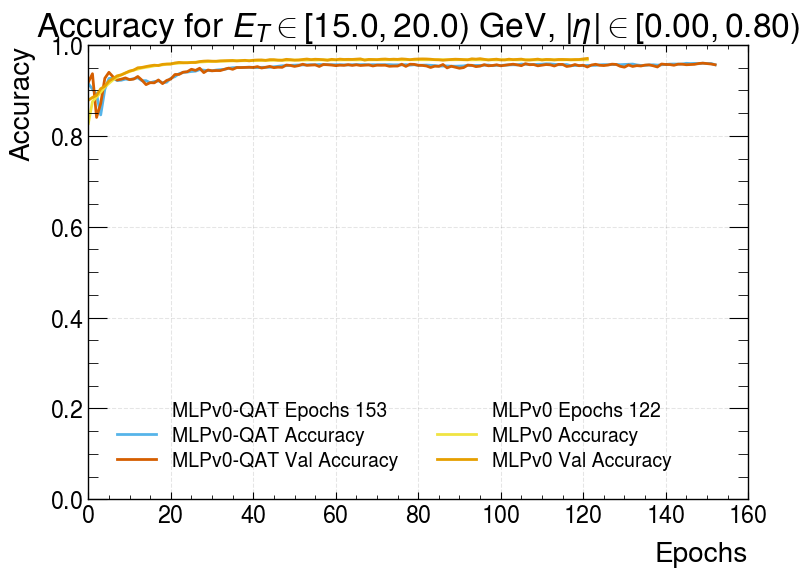

 [Thu, 09 Apr 2026 23:11:31] INFO Substituting symbol \in from Computer Modern


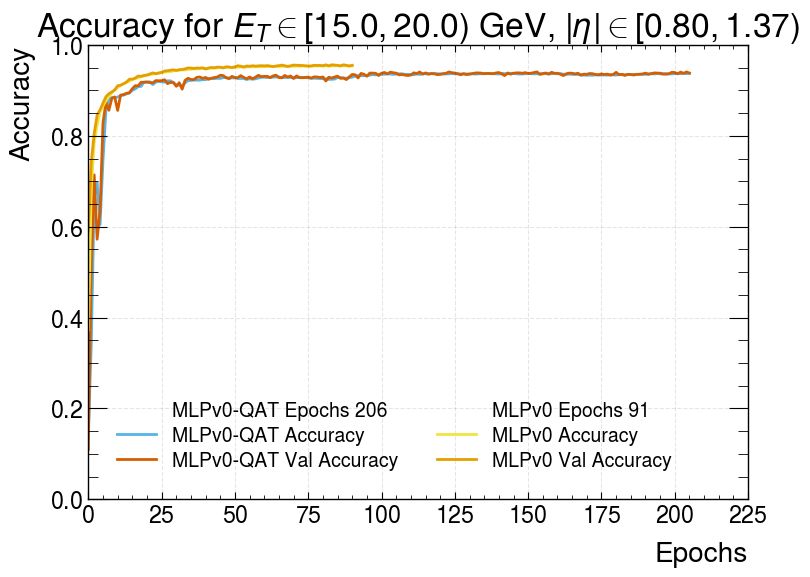

 [Thu, 09 Apr 2026 23:11:31] INFO Substituting symbol \in from Computer Modern


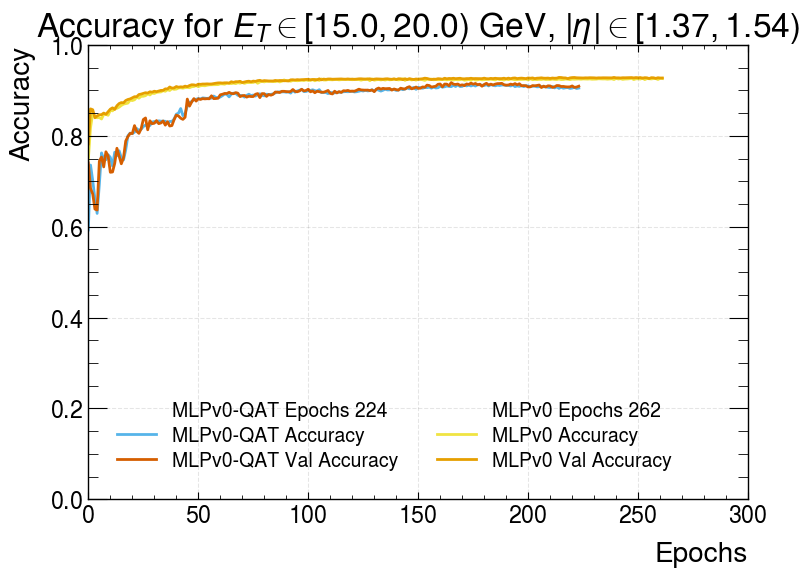

 [Thu, 09 Apr 2026 23:11:31] INFO Substituting symbol \in from Computer Modern


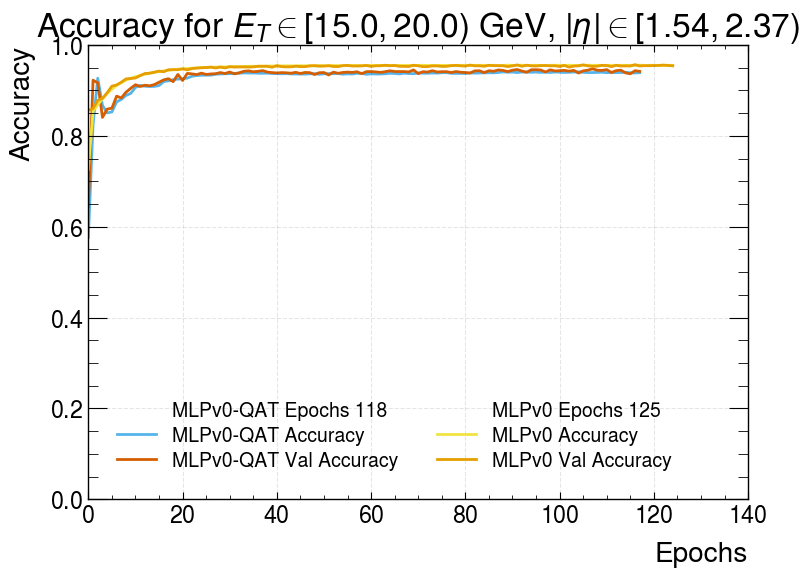

 [Thu, 09 Apr 2026 23:11:32] INFO Substituting symbol \in from Computer Modern


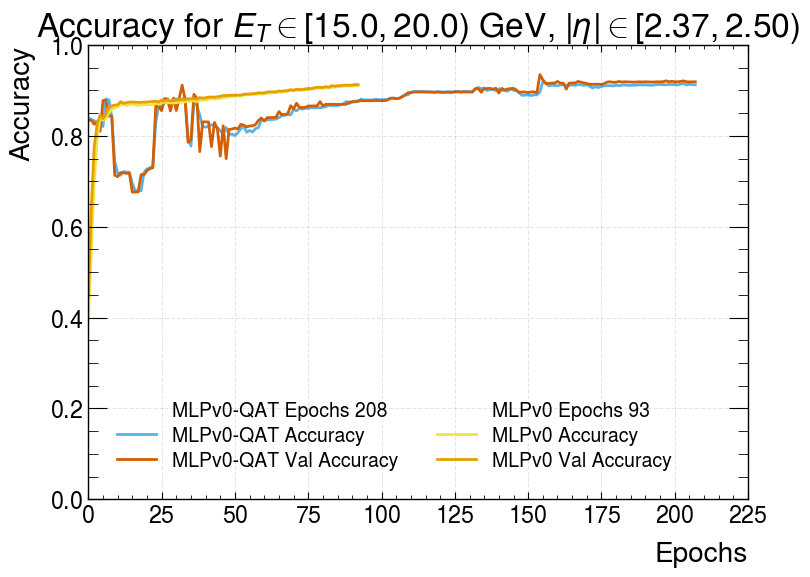

 [Thu, 09 Apr 2026 23:11:32] INFO Substituting symbol \in from Computer Modern


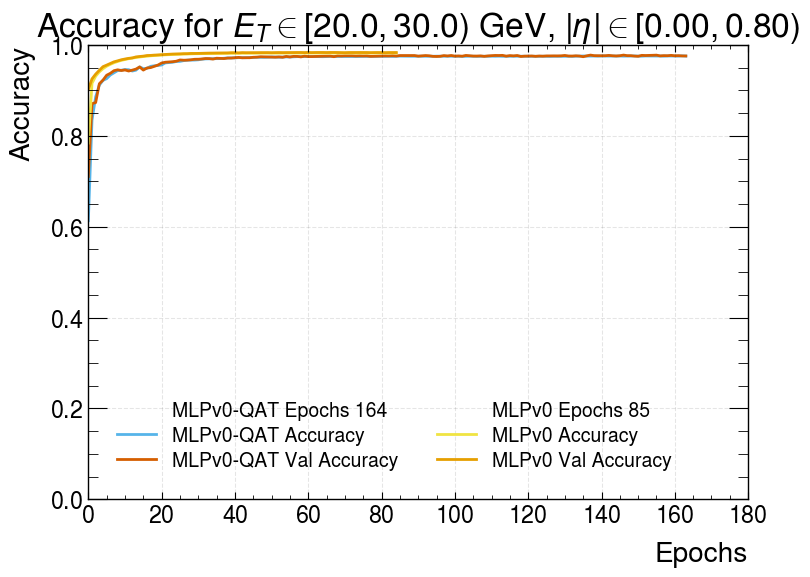

 [Thu, 09 Apr 2026 23:11:32] INFO Substituting symbol \in from Computer Modern


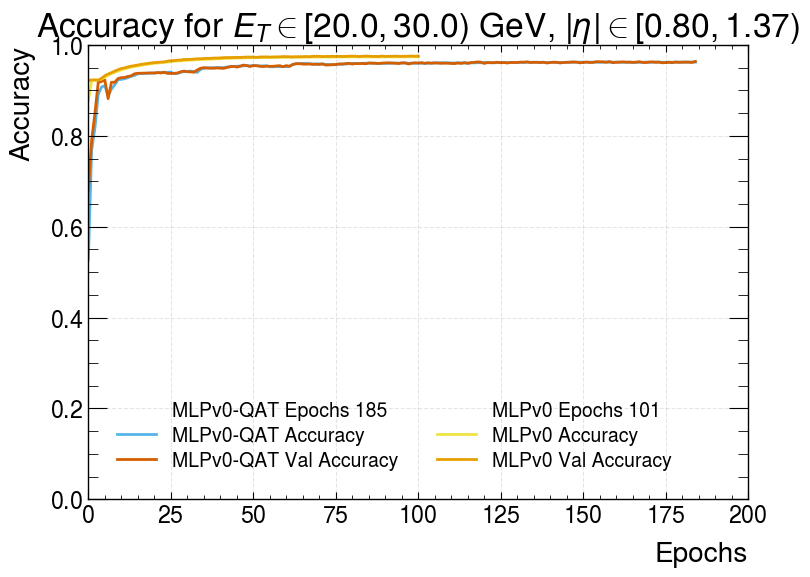

 [Thu, 09 Apr 2026 23:11:32] INFO Substituting symbol \in from Computer Modern


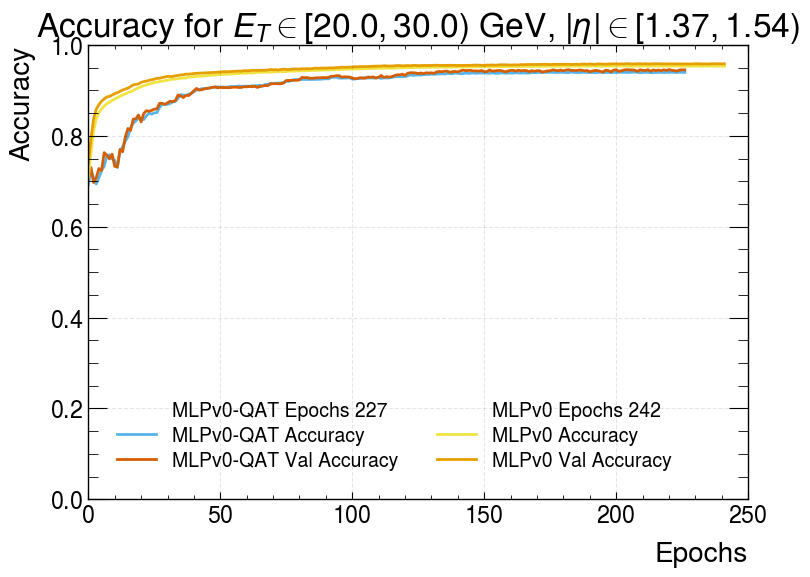

 [Thu, 09 Apr 2026 23:11:32] INFO Substituting symbol \in from Computer Modern


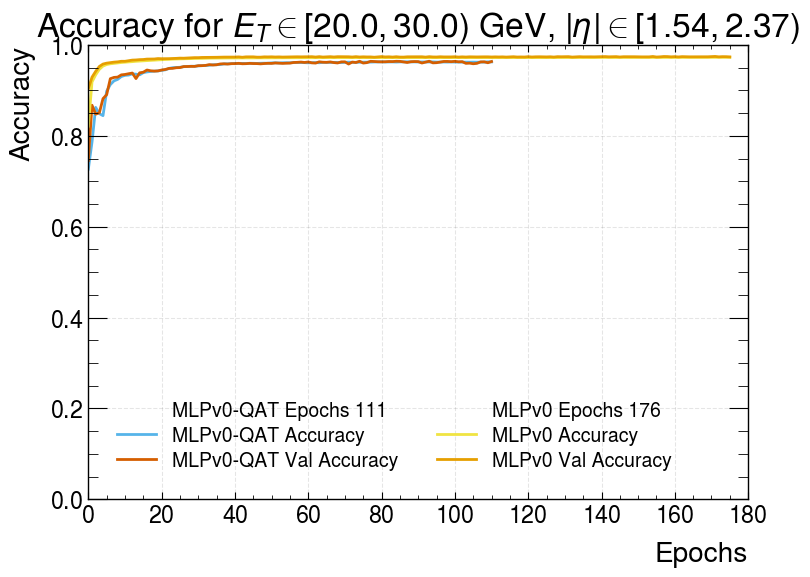

 [Thu, 09 Apr 2026 23:11:32] INFO Substituting symbol \in from Computer Modern


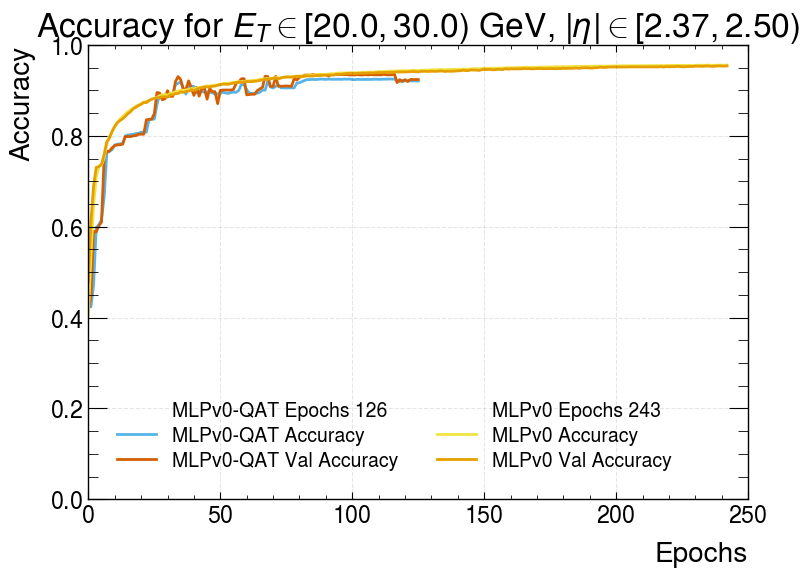

 [Thu, 09 Apr 2026 23:11:32] INFO Substituting symbol \in from Computer Modern


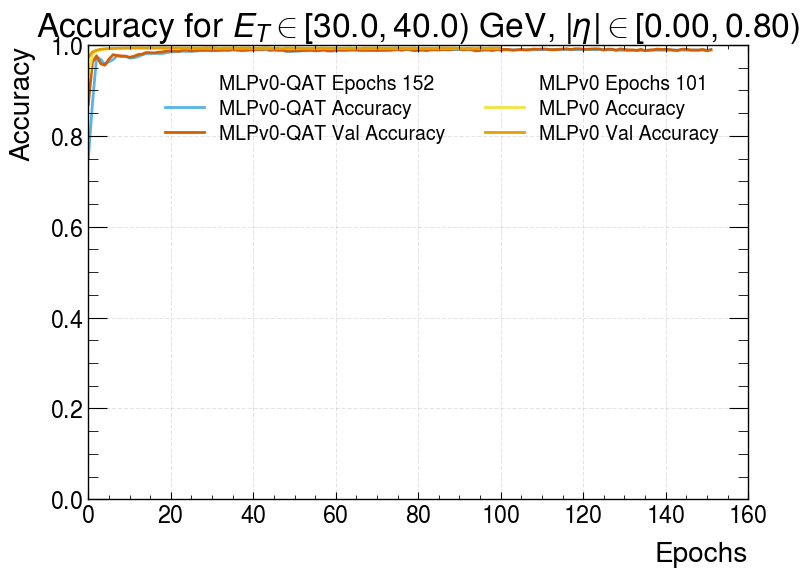

 [Thu, 09 Apr 2026 23:11:33] INFO Substituting symbol \in from Computer Modern


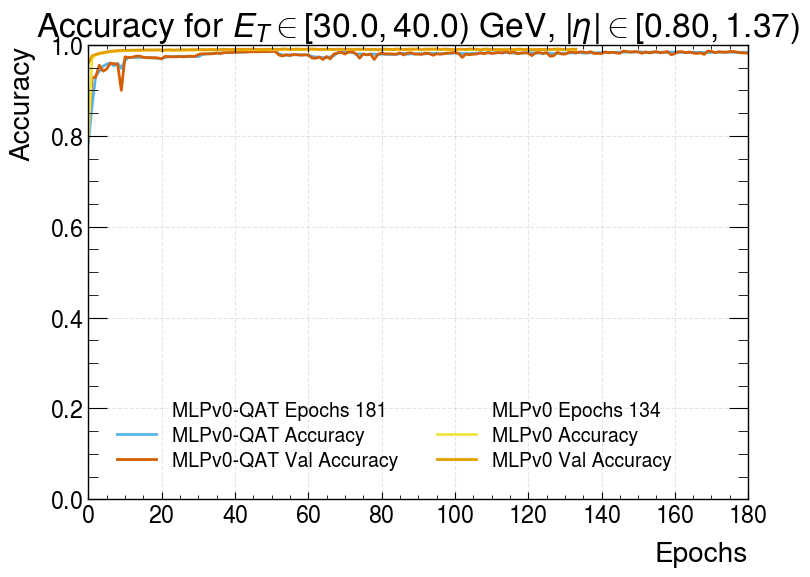

 [Thu, 09 Apr 2026 23:11:33] INFO Substituting symbol \in from Computer Modern


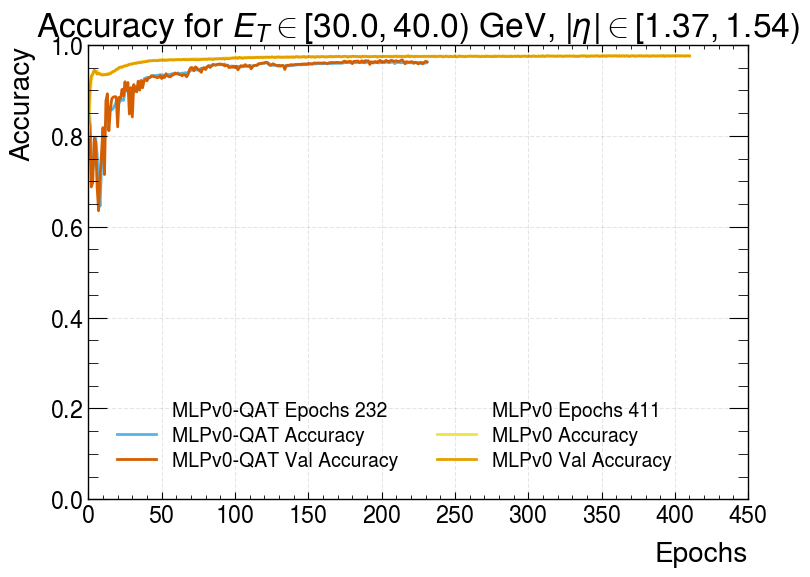

 [Thu, 09 Apr 2026 23:11:33] INFO Substituting symbol \in from Computer Modern


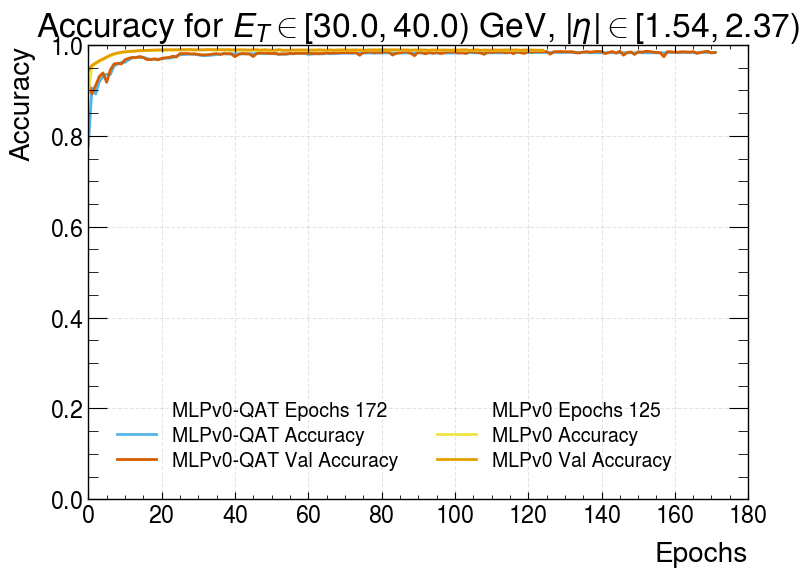

 [Thu, 09 Apr 2026 23:11:33] INFO Substituting symbol \in from Computer Modern


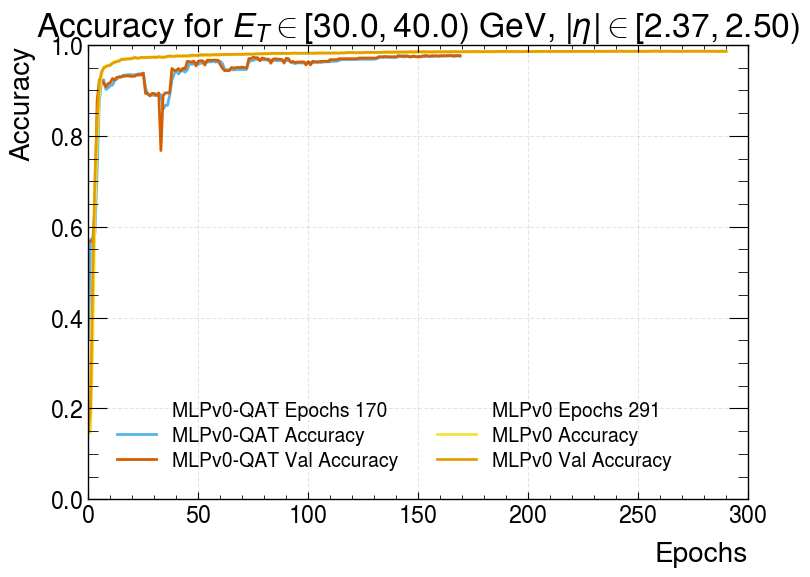

 [Thu, 09 Apr 2026 23:11:33] INFO Substituting symbol \in from Computer Modern


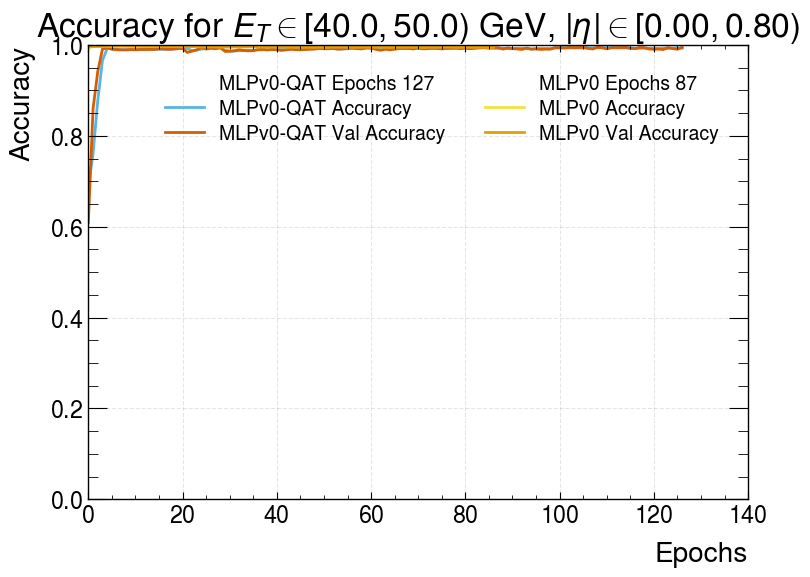

 [Thu, 09 Apr 2026 23:11:33] INFO Substituting symbol \in from Computer Modern


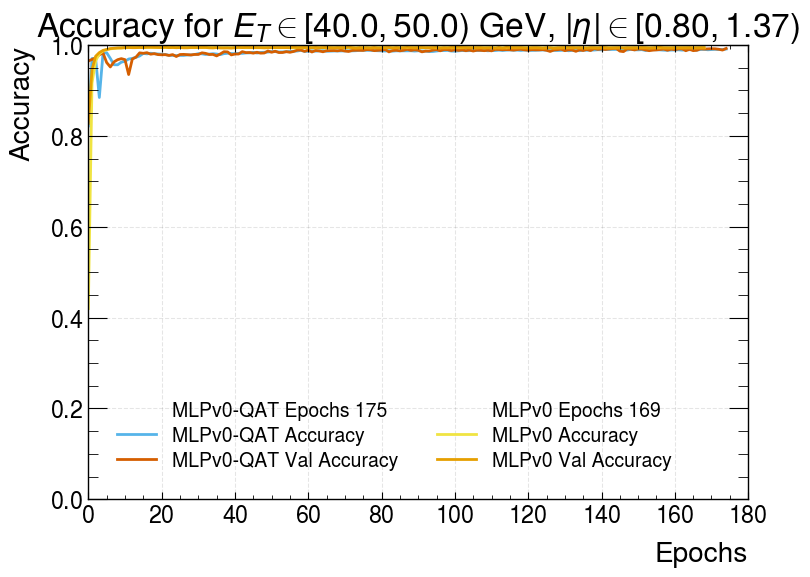

 [Thu, 09 Apr 2026 23:11:34] INFO Substituting symbol \in from Computer Modern


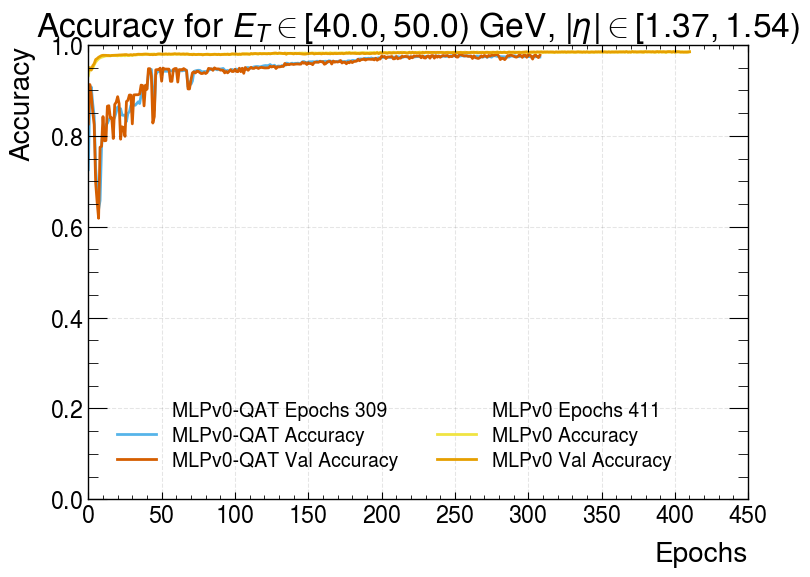

 [Thu, 09 Apr 2026 23:11:34] INFO Substituting symbol \in from Computer Modern


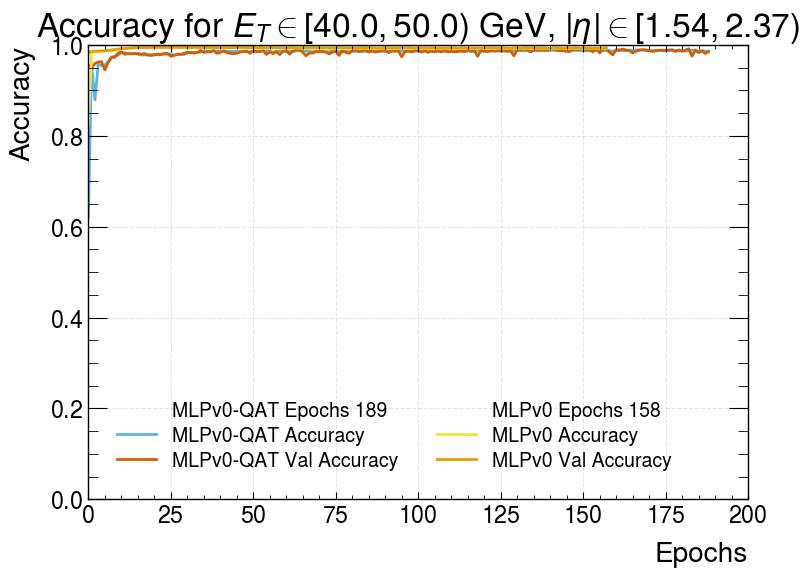

 [Thu, 09 Apr 2026 23:11:34] INFO Substituting symbol \in from Computer Modern


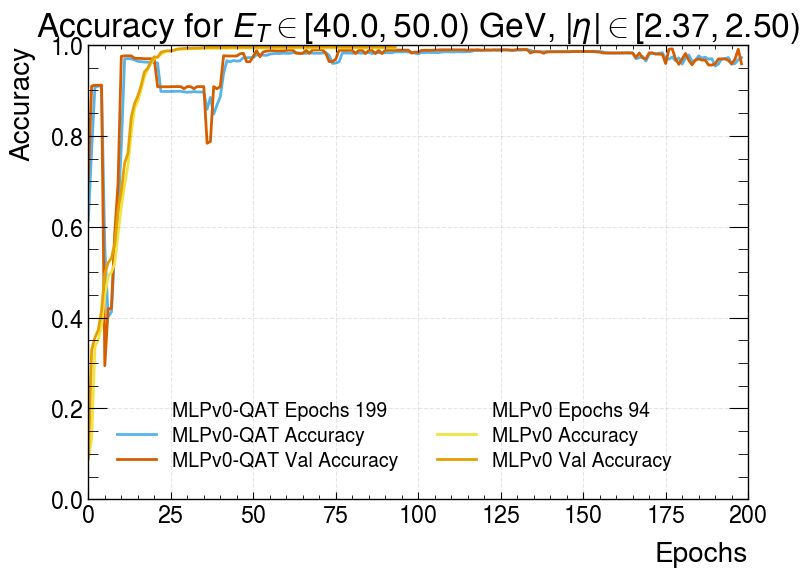

 [Thu, 09 Apr 2026 23:11:34] INFO Substituting symbol \in from Computer Modern


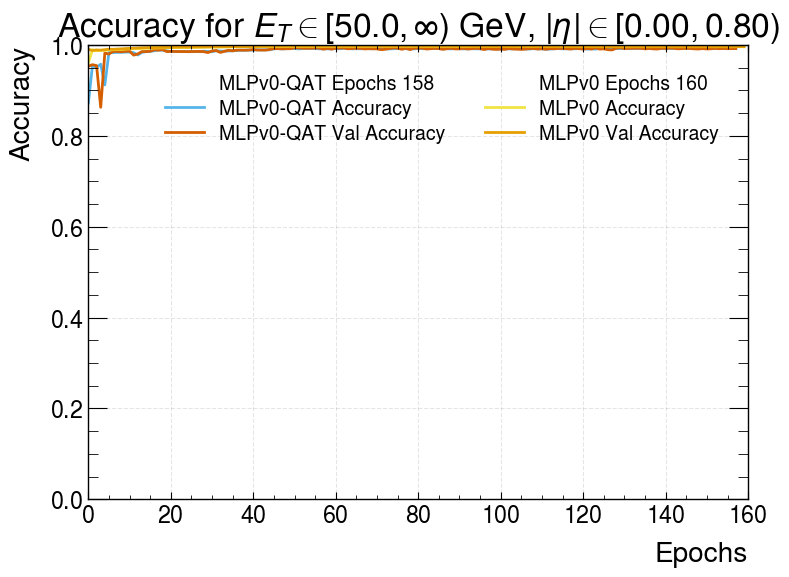

 [Thu, 09 Apr 2026 23:11:34] INFO Substituting symbol \in from Computer Modern


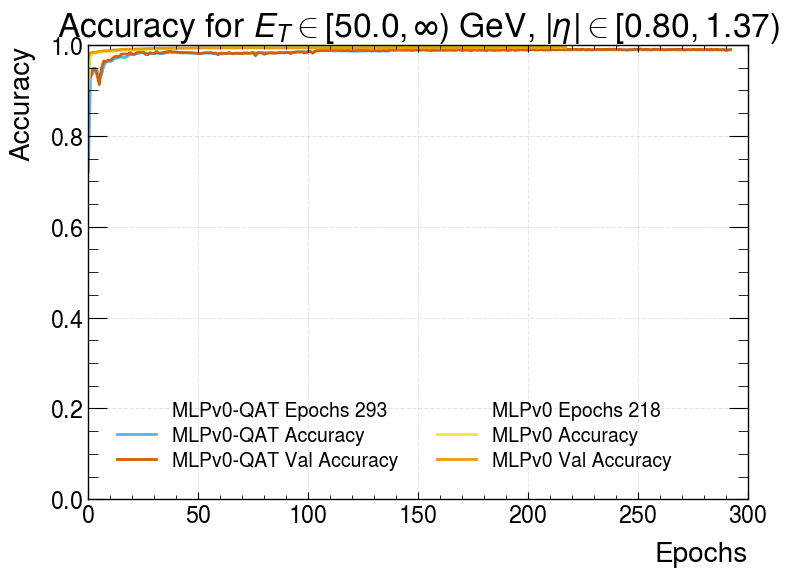

 [Thu, 09 Apr 2026 23:11:34] INFO Substituting symbol \in from Computer Modern


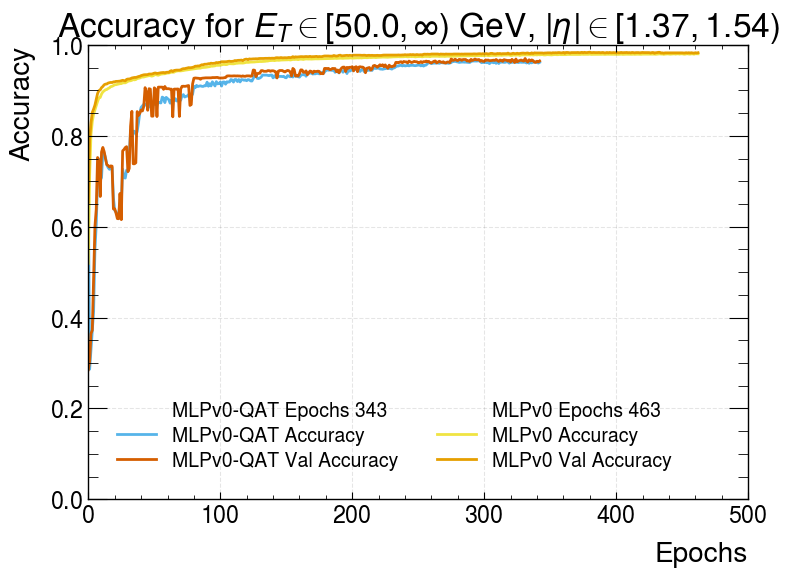

 [Thu, 09 Apr 2026 23:11:34] INFO Substituting symbol \in from Computer Modern


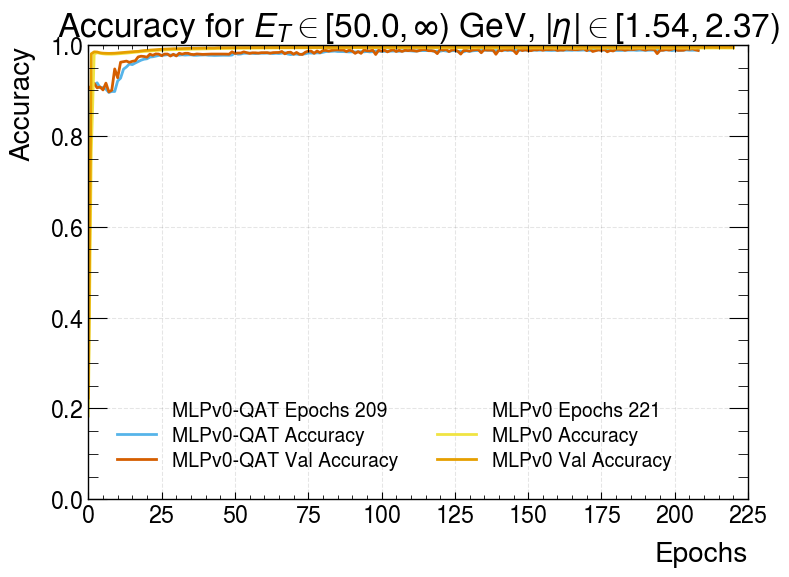

 [Thu, 09 Apr 2026 23:11:35] INFO Substituting symbol \in from Computer Modern


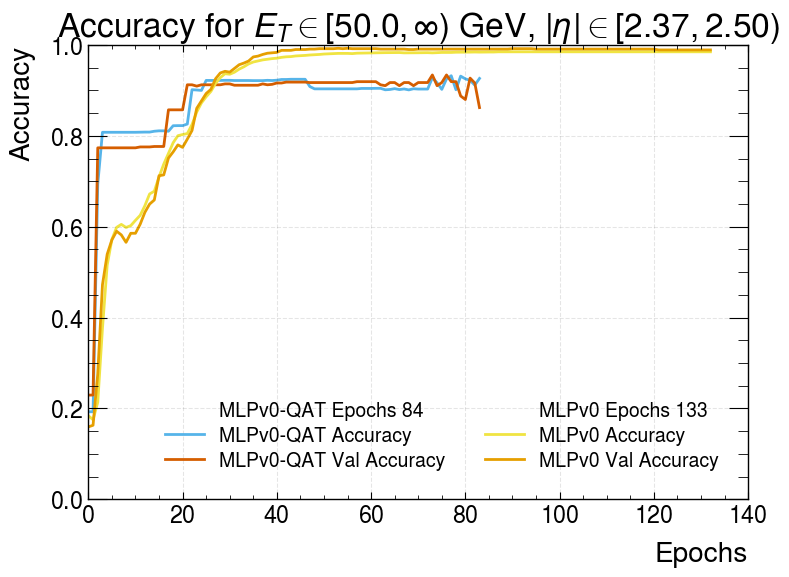

In [7]:
accuracy_plots = plot_training_curve(
    results,
    metric='accuracy',
    metric_label='Accuracy',
    ylim=(0, 1),
    legend_kwargs=dict(ncols=2)
)

 [Thu, 09 Apr 2026 23:11:35] INFO Processing row with et_bin_upper: 20000.0, et_bin_lower: 15000.0, eta_bin_upper: 0.8, eta_bin_lower: 0.0
 [Thu, 09 Apr 2026 23:11:35] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:11:35] INFO Processing row with et_bin_upper: 20000.0, et_bin_lower: 15000.0, eta_bin_upper: 1.37, eta_bin_lower: 0.8
 [Thu, 09 Apr 2026 23:11:35] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:11:35] INFO Processing row with et_bin_upper: 20000.0, et_bin_lower: 15000.0, eta_bin_upper: 1.54, eta_bin_lower: 1.37
 [Thu, 09 Apr 2026 23:11:35] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:11:35] INFO Processing row with et_bin_upper: 20000.0, et_bin_lower: 15000.0, eta_bin_upper: 2.37, eta_bin_lower: 1.54
 [Thu, 09 Apr 2026 23:11:35] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:11:35] INFO Processing row with et_bin_upper: 20000.0, et_bin_lower: 15000.0, eta_bin_upper: 2.500000

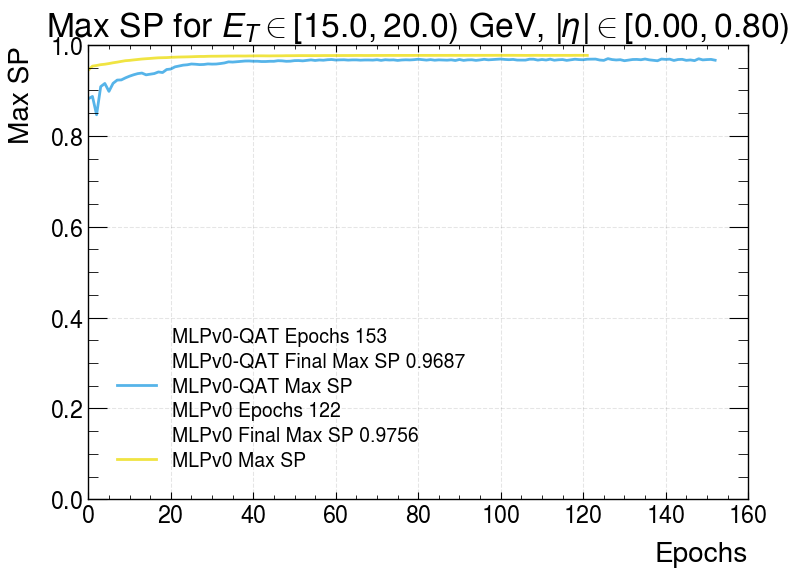

 [Thu, 09 Apr 2026 23:11:40] INFO Substituting symbol \in from Computer Modern


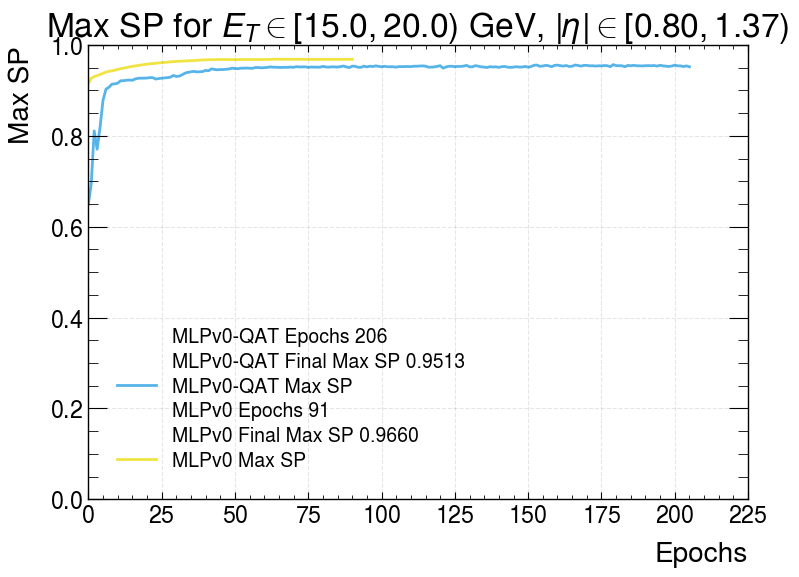

 [Thu, 09 Apr 2026 23:11:40] INFO Substituting symbol \in from Computer Modern


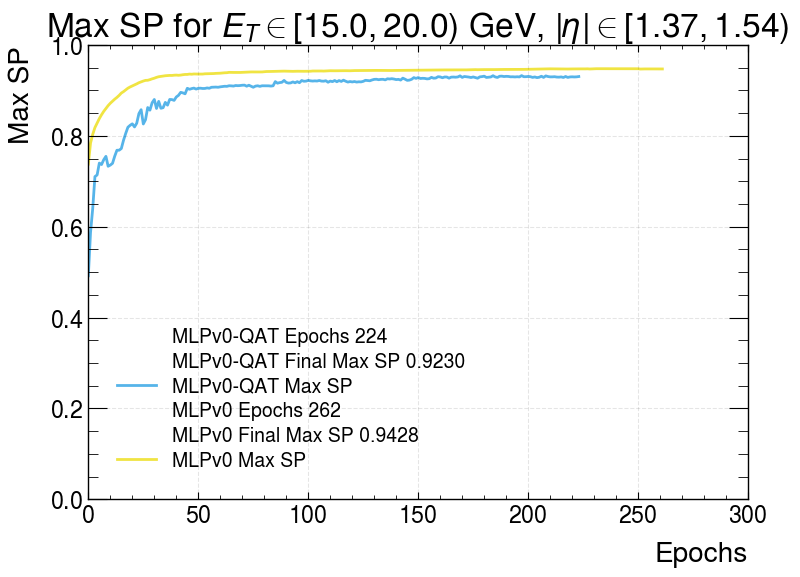

 [Thu, 09 Apr 2026 23:11:40] INFO Substituting symbol \in from Computer Modern


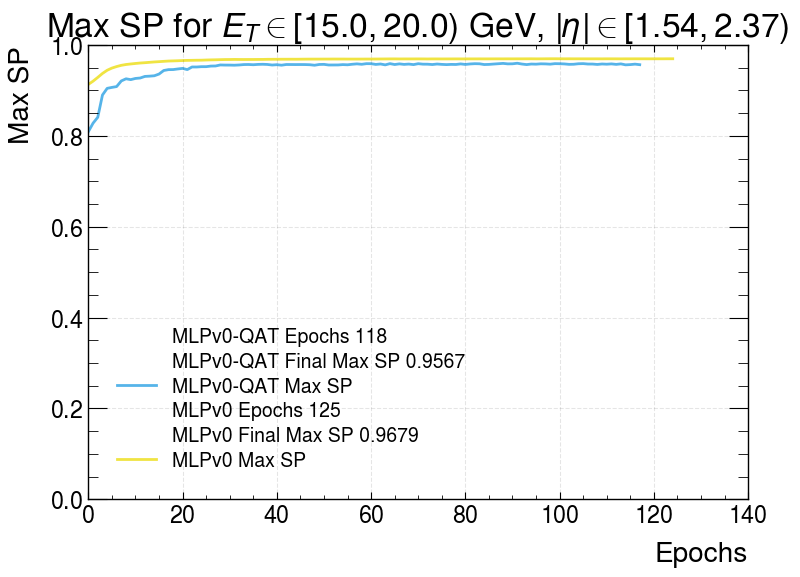

 [Thu, 09 Apr 2026 23:11:40] INFO Substituting symbol \in from Computer Modern


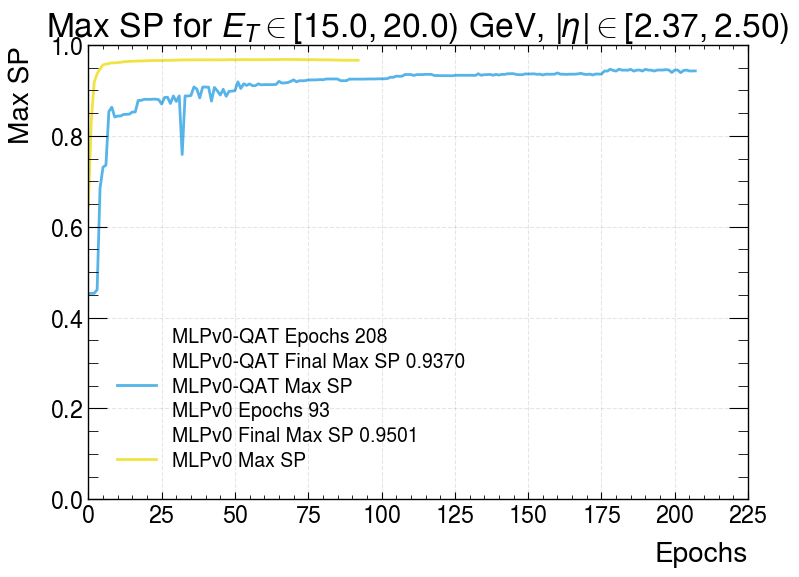

 [Thu, 09 Apr 2026 23:11:40] INFO Substituting symbol \in from Computer Modern


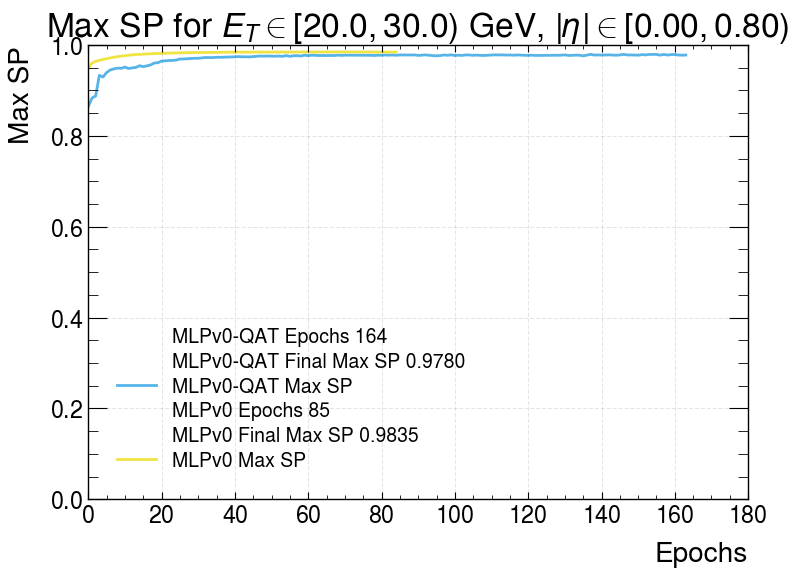

 [Thu, 09 Apr 2026 23:11:41] INFO Substituting symbol \in from Computer Modern


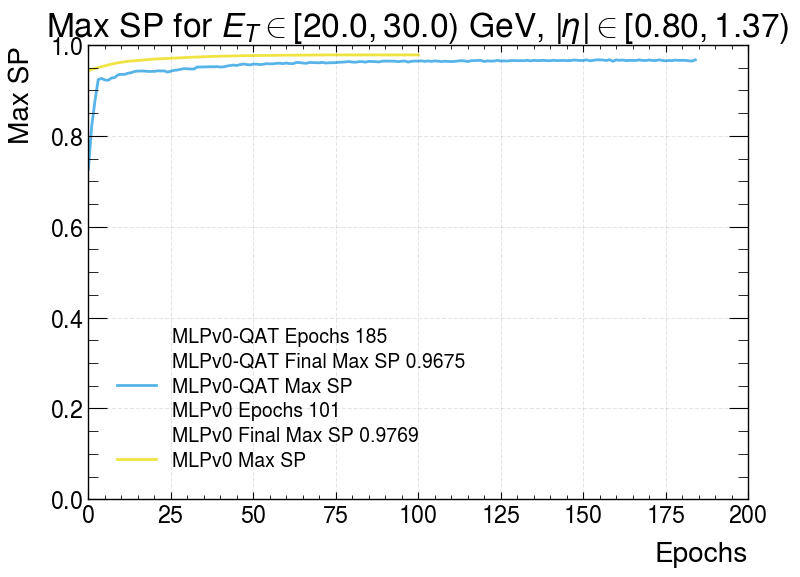

 [Thu, 09 Apr 2026 23:11:41] INFO Substituting symbol \in from Computer Modern


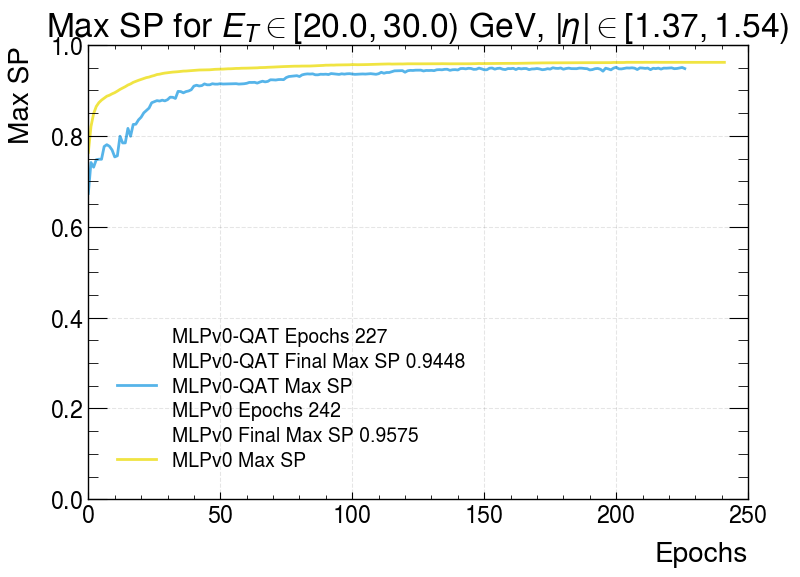

 [Thu, 09 Apr 2026 23:11:41] INFO Substituting symbol \in from Computer Modern


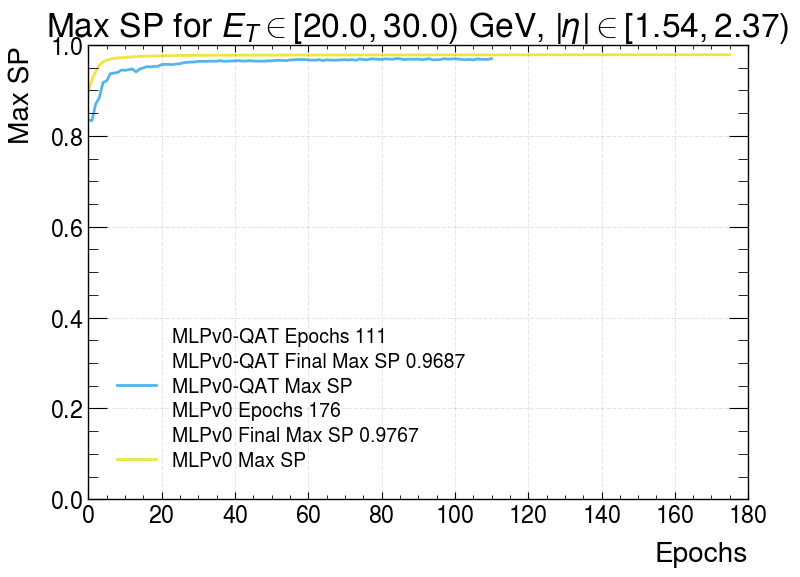

 [Thu, 09 Apr 2026 23:11:41] INFO Substituting symbol \in from Computer Modern


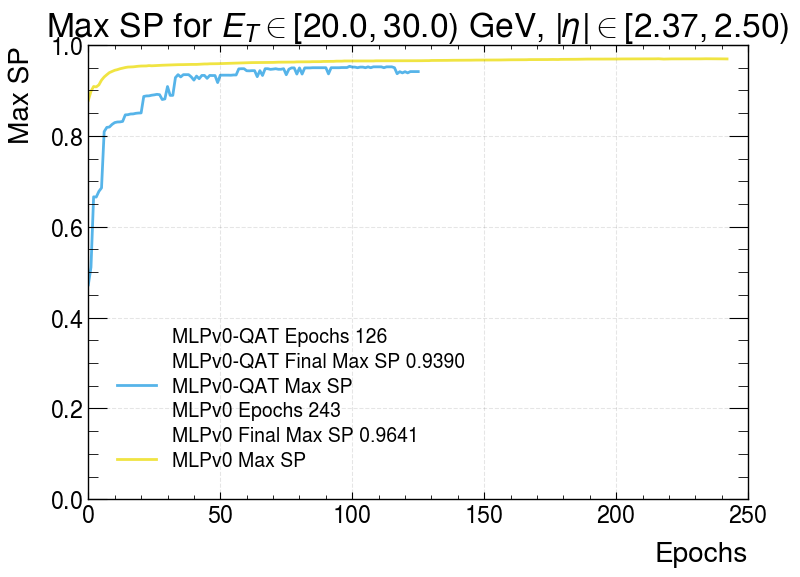

 [Thu, 09 Apr 2026 23:11:41] INFO Substituting symbol \in from Computer Modern


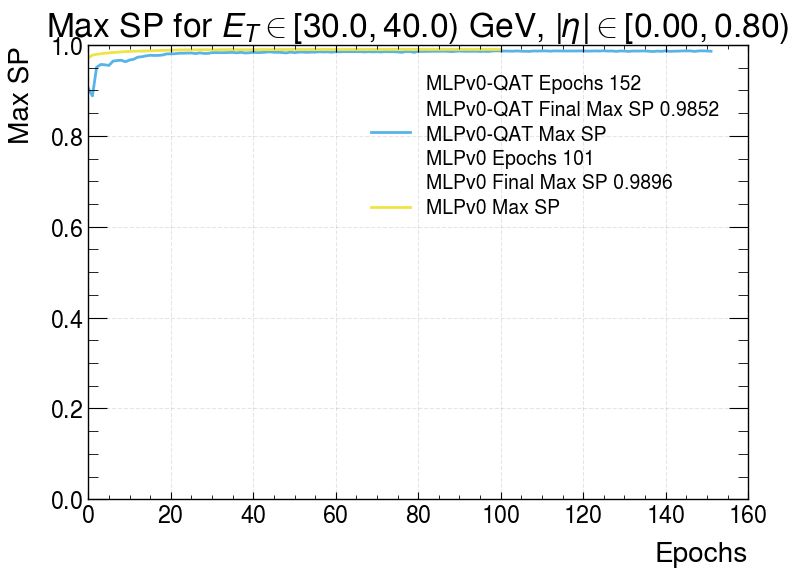

 [Thu, 09 Apr 2026 23:11:42] INFO Substituting symbol \in from Computer Modern


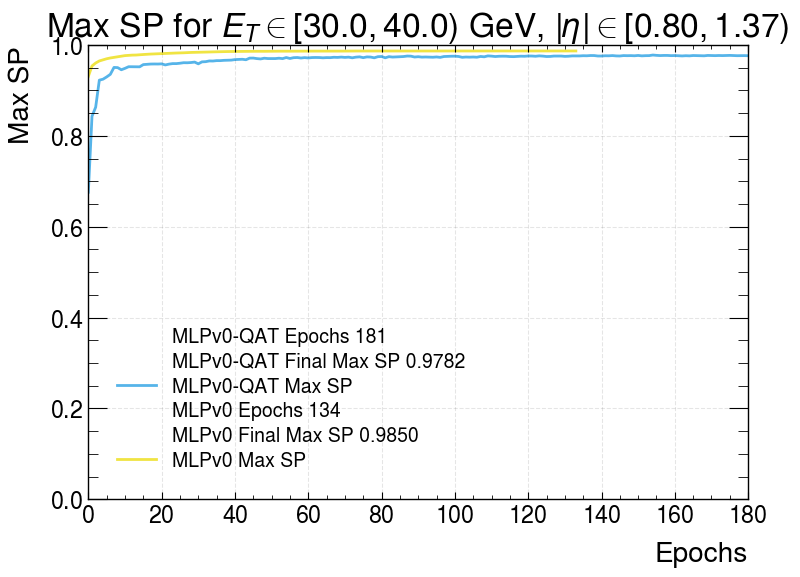

 [Thu, 09 Apr 2026 23:11:42] INFO Substituting symbol \in from Computer Modern


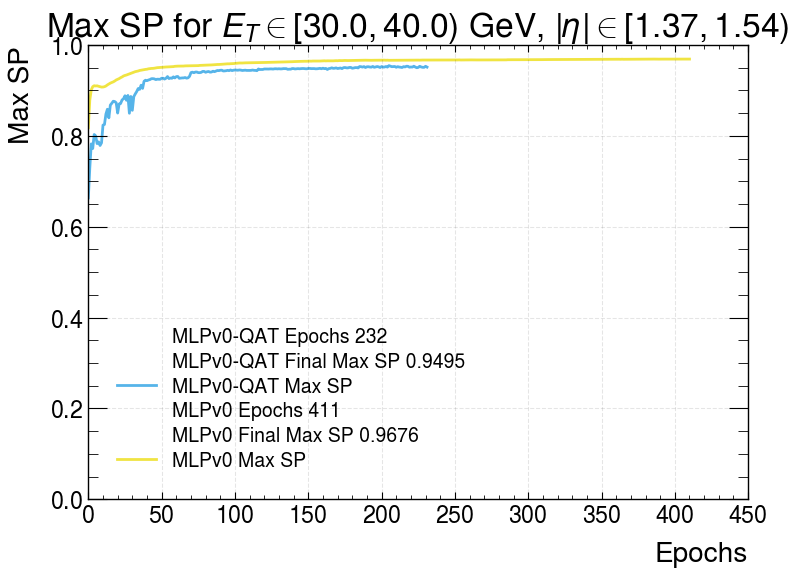

 [Thu, 09 Apr 2026 23:11:42] INFO Substituting symbol \in from Computer Modern


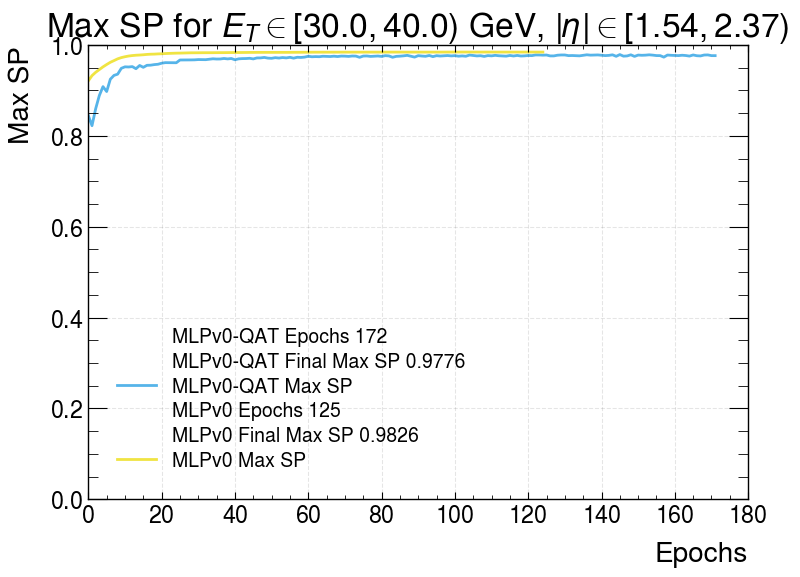

 [Thu, 09 Apr 2026 23:11:42] INFO Substituting symbol \in from Computer Modern


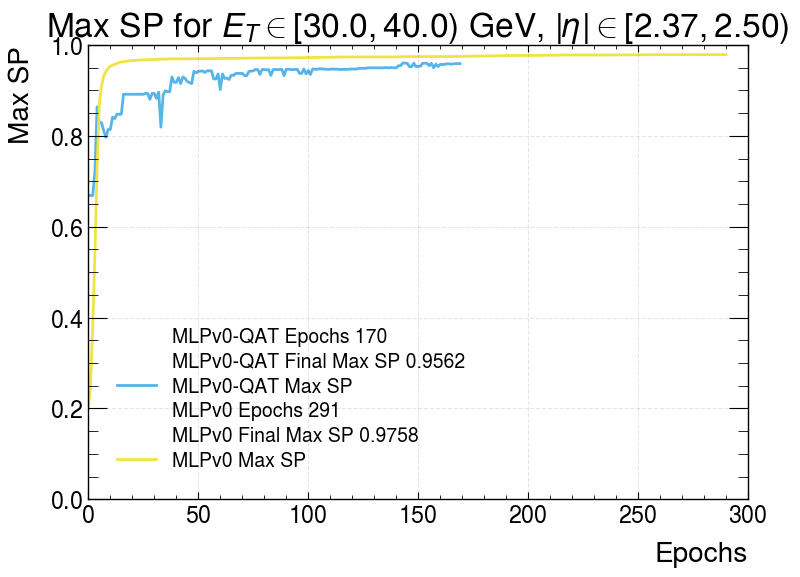

 [Thu, 09 Apr 2026 23:11:42] INFO Substituting symbol \in from Computer Modern


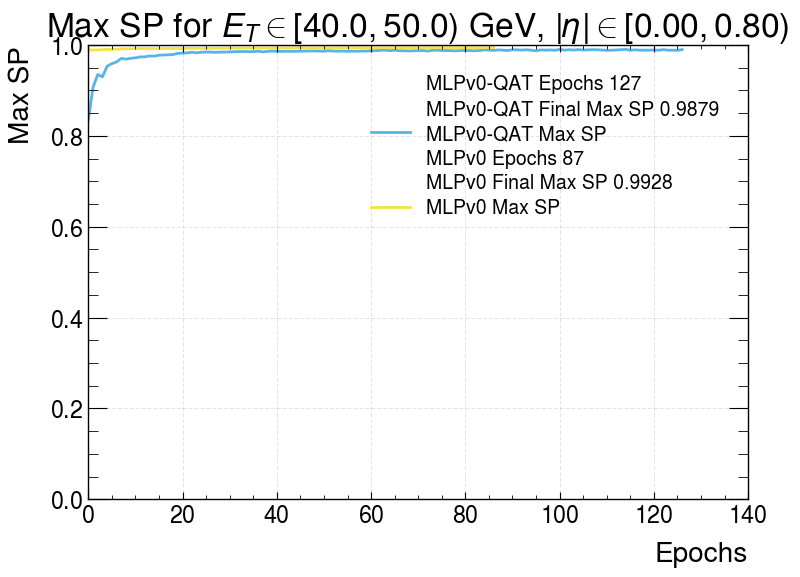

 [Thu, 09 Apr 2026 23:11:43] INFO Substituting symbol \in from Computer Modern


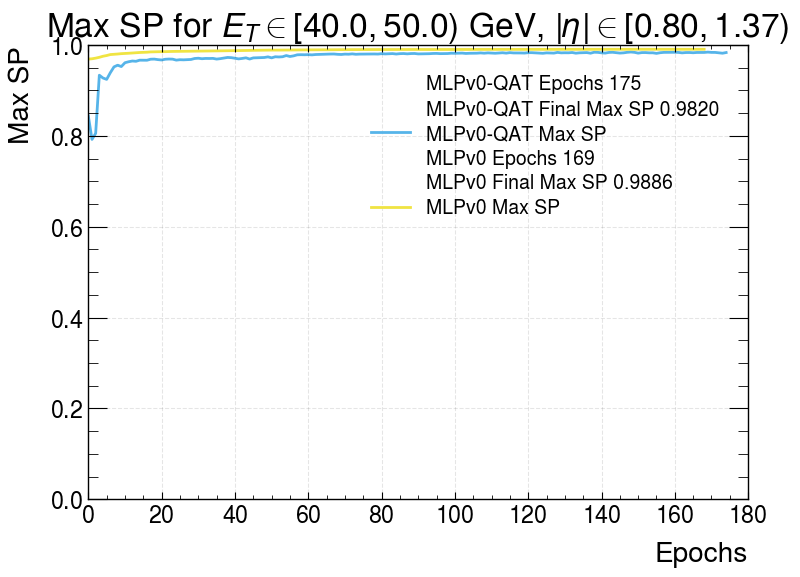

 [Thu, 09 Apr 2026 23:11:43] INFO Substituting symbol \in from Computer Modern


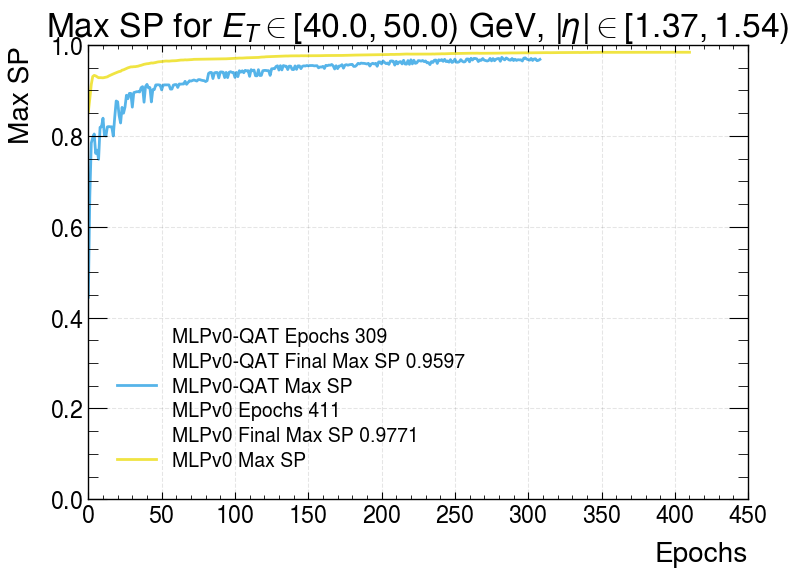

 [Thu, 09 Apr 2026 23:11:43] INFO Substituting symbol \in from Computer Modern


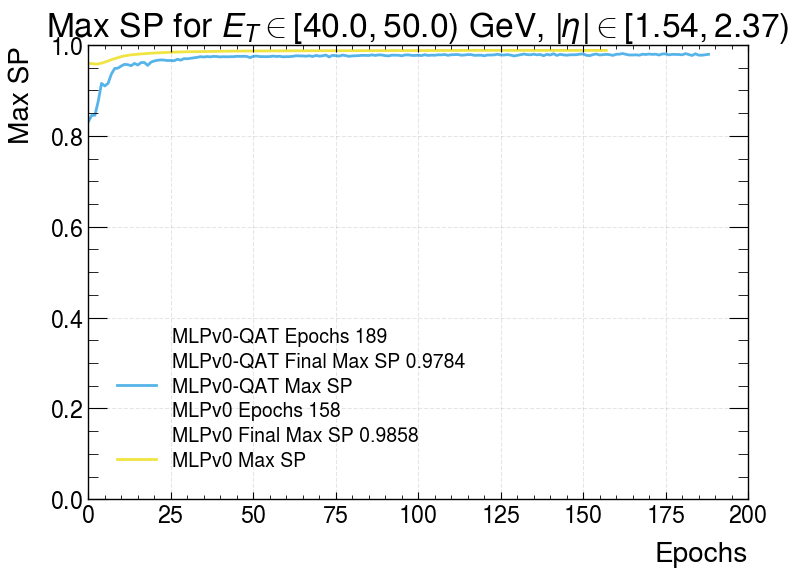

 [Thu, 09 Apr 2026 23:11:43] INFO Substituting symbol \in from Computer Modern


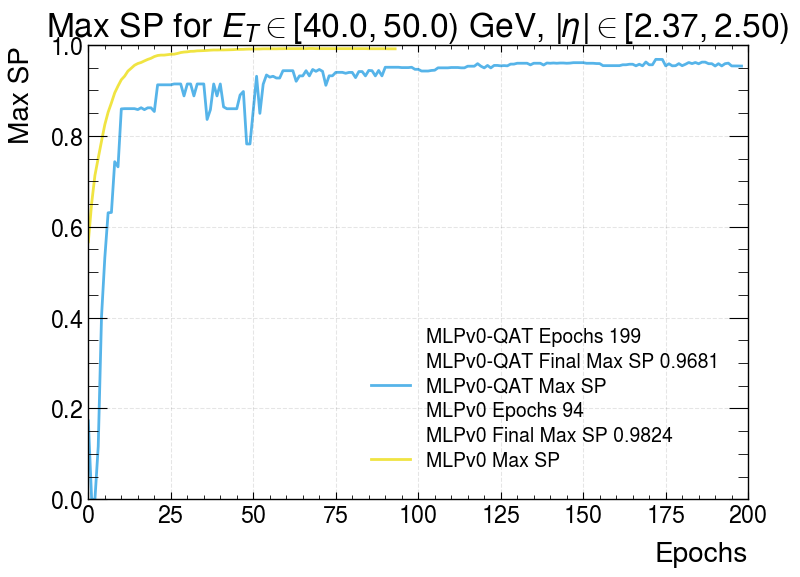

 [Thu, 09 Apr 2026 23:11:43] INFO Substituting symbol \in from Computer Modern


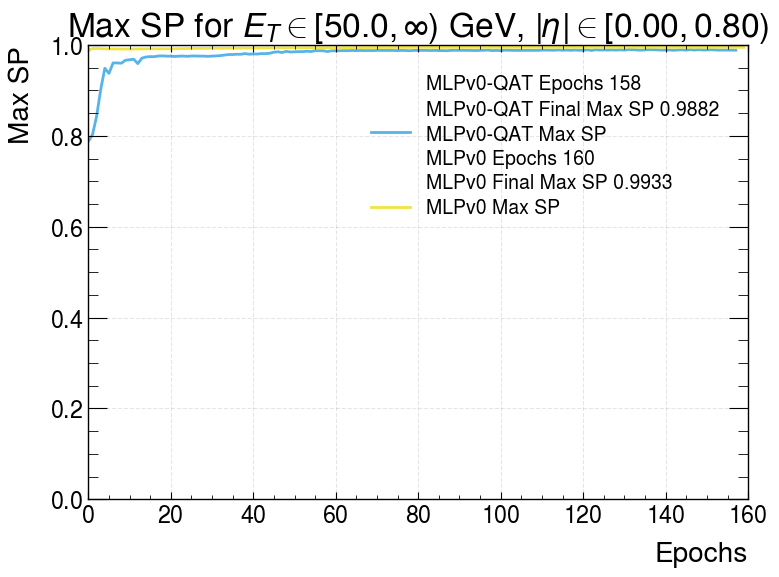

 [Thu, 09 Apr 2026 23:11:43] INFO Substituting symbol \in from Computer Modern


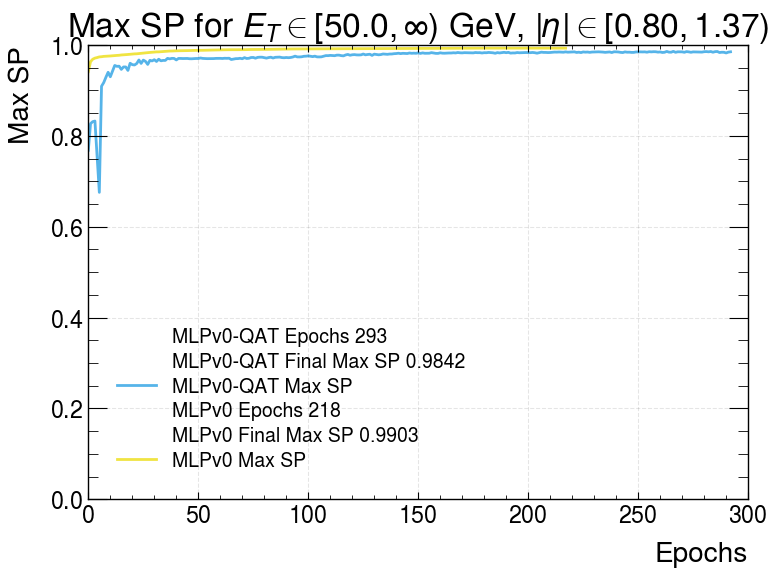

 [Thu, 09 Apr 2026 23:11:44] INFO Substituting symbol \in from Computer Modern


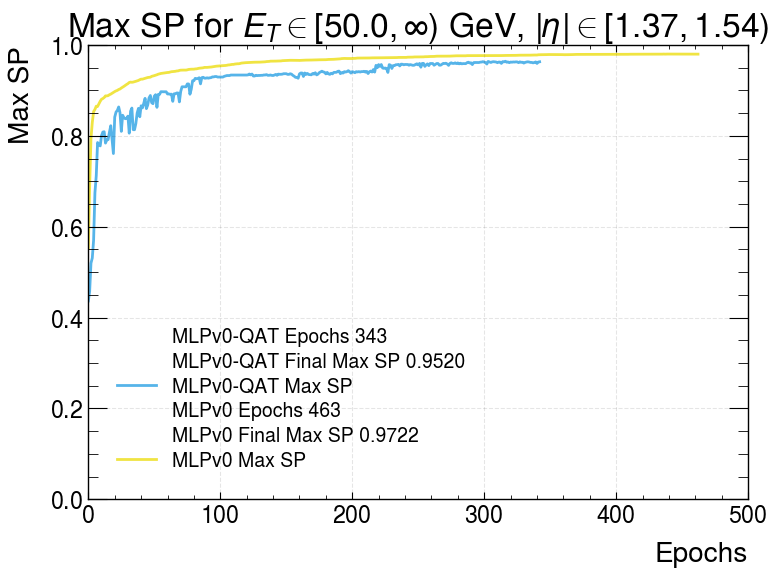

 [Thu, 09 Apr 2026 23:11:44] INFO Substituting symbol \in from Computer Modern


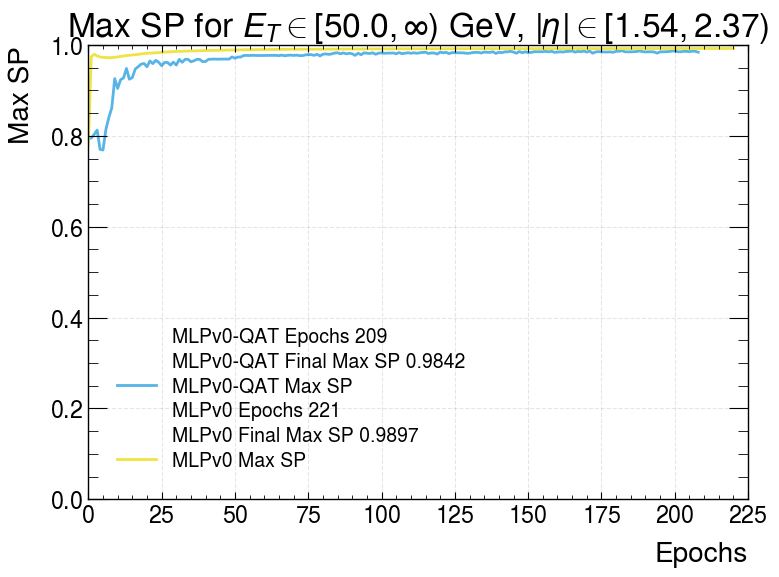

 [Thu, 09 Apr 2026 23:11:44] INFO Substituting symbol \in from Computer Modern


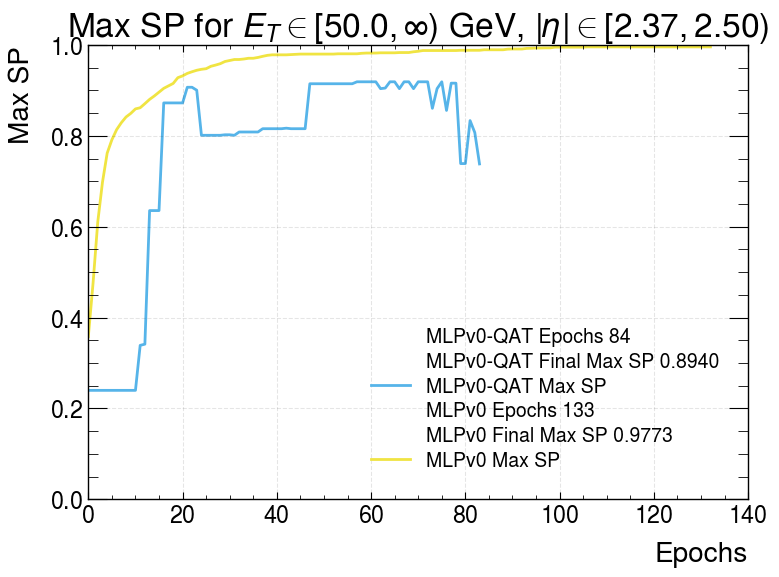

In [8]:
max_sp_plots = plot_training_curve(
    results,
    metric='max_sp_val',
    metric_label='Max SP',
    summary_metric_name='max_sp',
    ylim=(0, 1)
)

 [Thu, 09 Apr 2026 23:11:44] INFO Processing row with et_bin_upper: 20000.0, et_bin_lower: 15000.0, eta_bin_upper: 0.8, eta_bin_lower: 0.0
 [Thu, 09 Apr 2026 23:11:44] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:11:45] INFO Processing row with et_bin_upper: 20000.0, et_bin_lower: 15000.0, eta_bin_upper: 1.37, eta_bin_lower: 0.8
 [Thu, 09 Apr 2026 23:11:45] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:11:45] INFO Processing row with et_bin_upper: 20000.0, et_bin_lower: 15000.0, eta_bin_upper: 1.54, eta_bin_lower: 1.37
 [Thu, 09 Apr 2026 23:11:45] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:11:45] INFO Processing row with et_bin_upper: 20000.0, et_bin_lower: 15000.0, eta_bin_upper: 2.37, eta_bin_lower: 1.54
 [Thu, 09 Apr 2026 23:11:45] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:11:45] INFO Processing row with et_bin_upper: 20000.0, et_bin_lower: 15000.0, eta_bin_upper: 2.500000

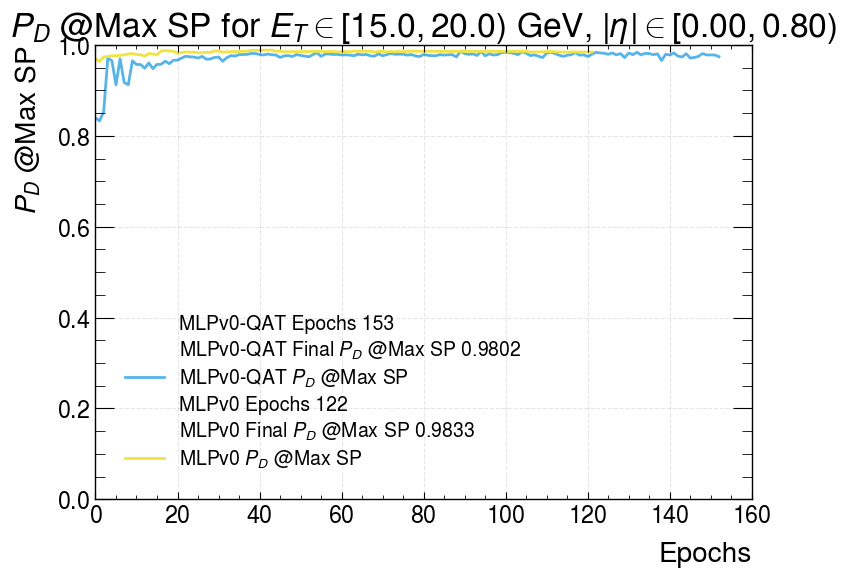

 [Thu, 09 Apr 2026 23:11:52] INFO Substituting symbol \in from Computer Modern


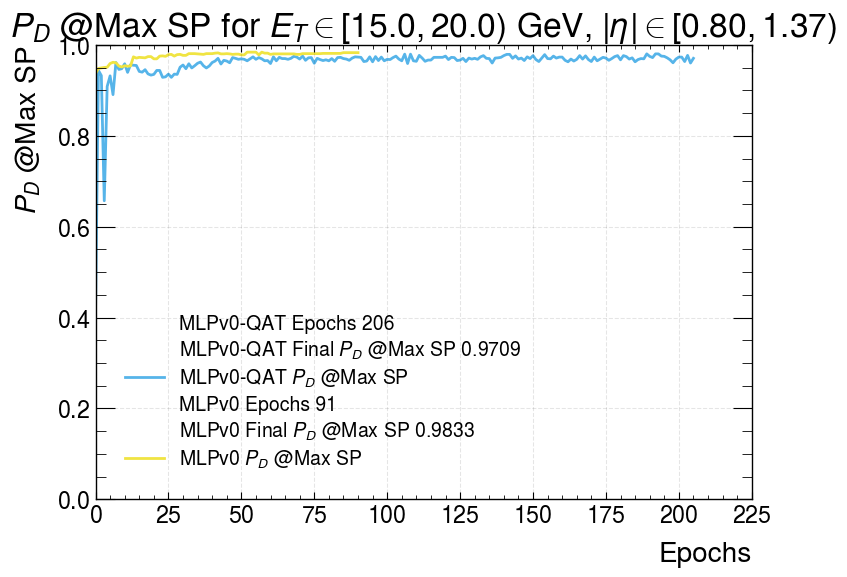

 [Thu, 09 Apr 2026 23:11:53] INFO Substituting symbol \in from Computer Modern


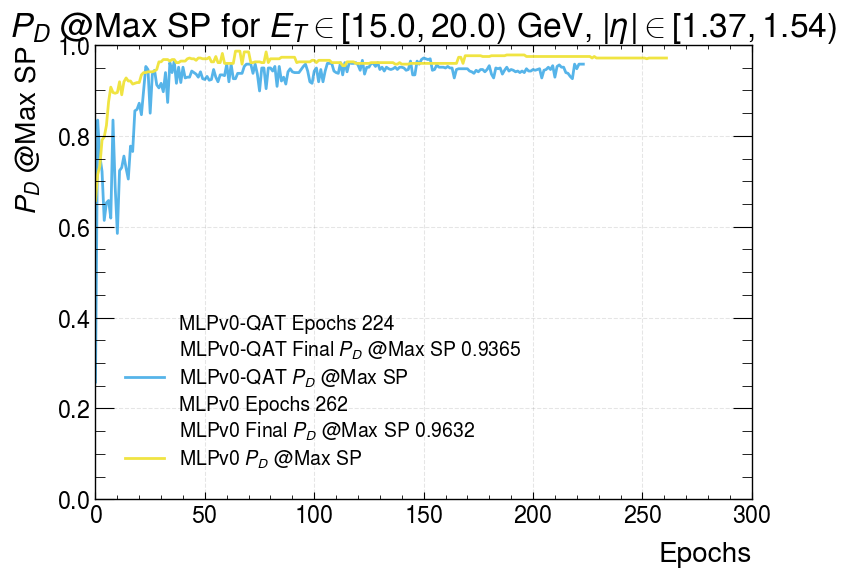

 [Thu, 09 Apr 2026 23:11:53] INFO Substituting symbol \in from Computer Modern


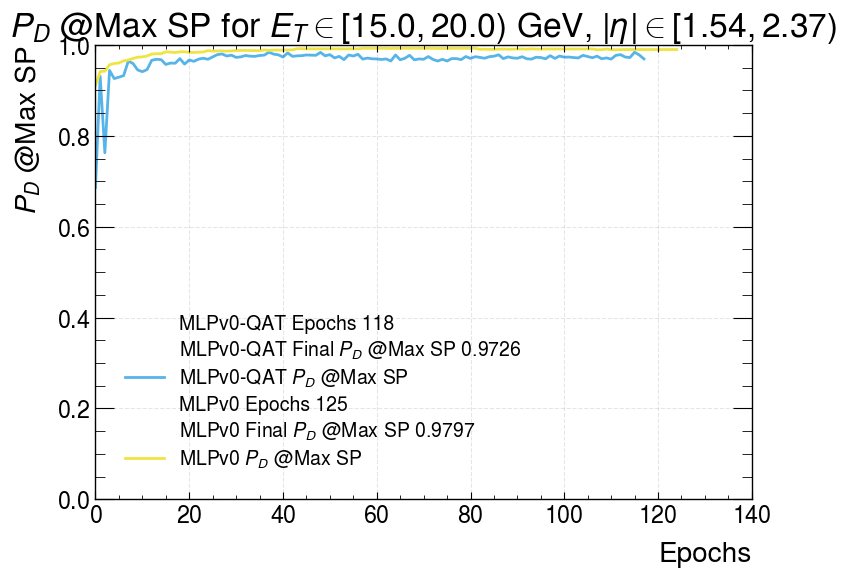

 [Thu, 09 Apr 2026 23:11:53] INFO Substituting symbol \in from Computer Modern


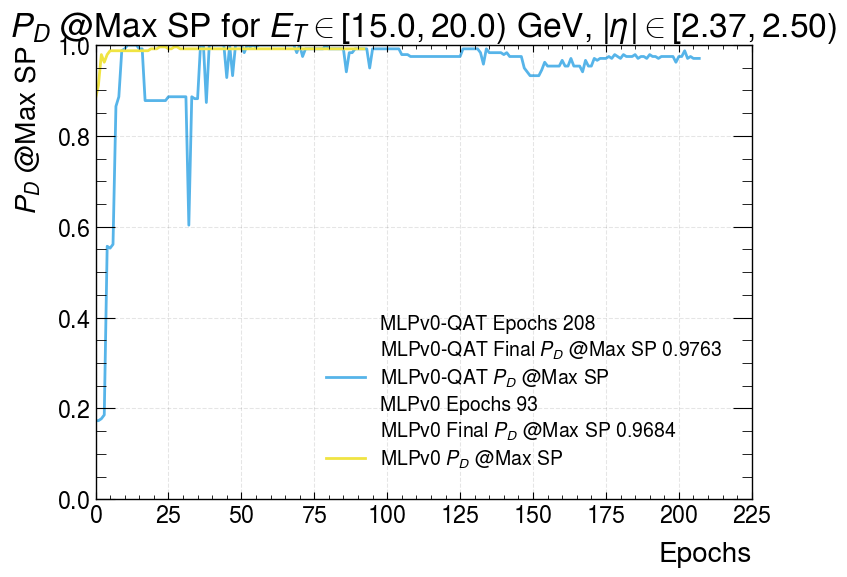

 [Thu, 09 Apr 2026 23:11:53] INFO Substituting symbol \in from Computer Modern


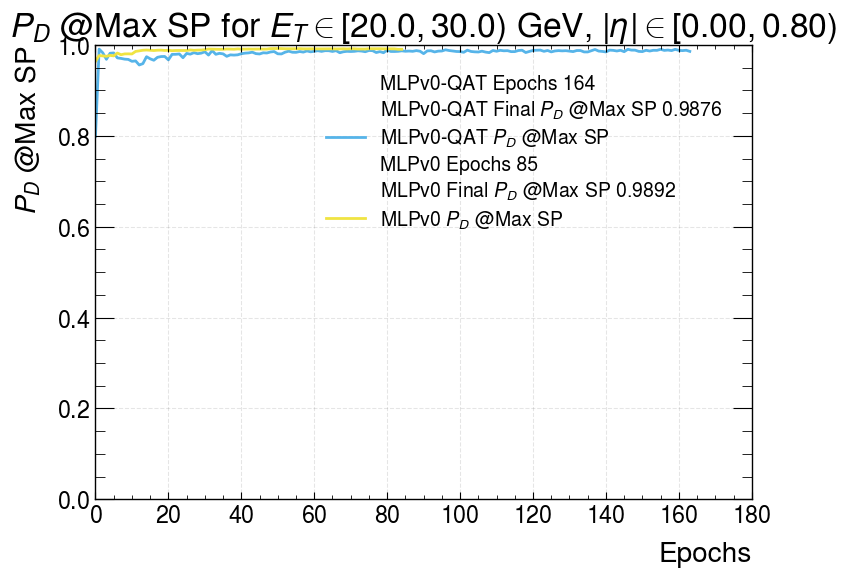

 [Thu, 09 Apr 2026 23:11:53] INFO Substituting symbol \in from Computer Modern


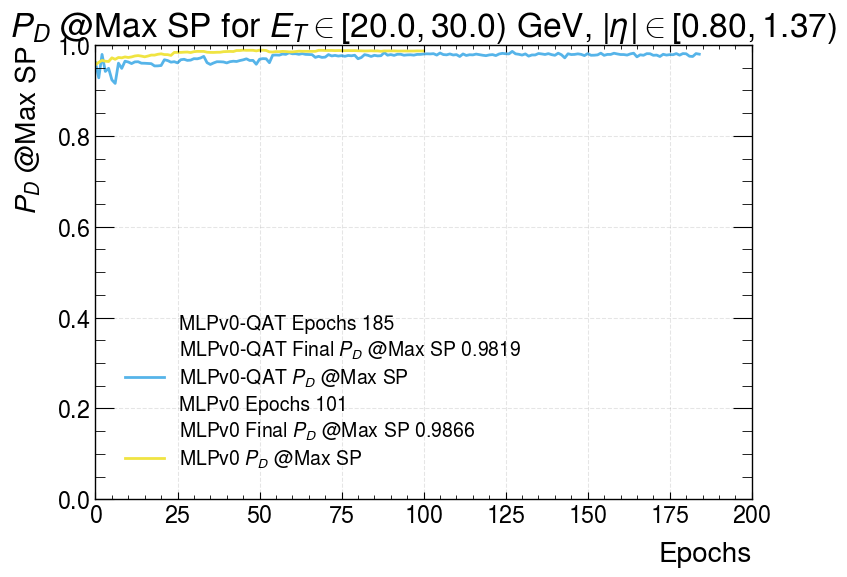

 [Thu, 09 Apr 2026 23:11:53] INFO Substituting symbol \in from Computer Modern


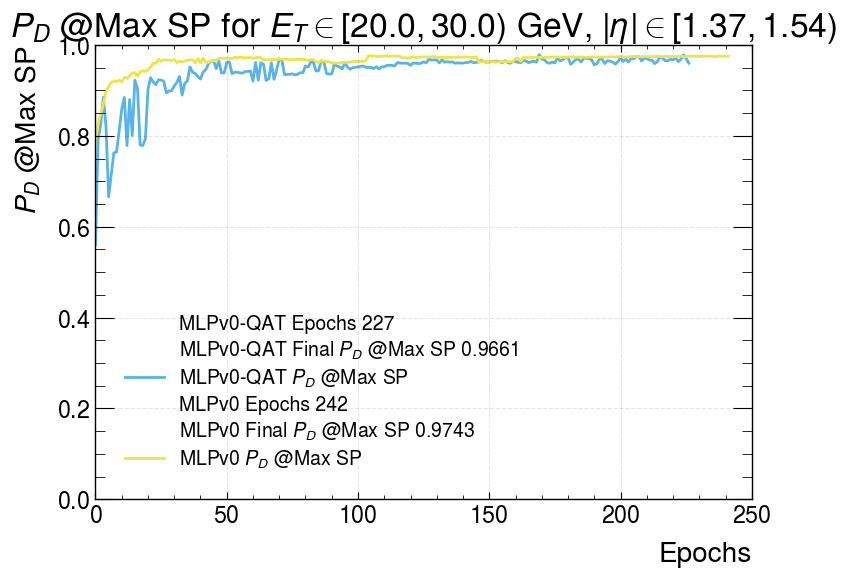

 [Thu, 09 Apr 2026 23:11:54] INFO Substituting symbol \in from Computer Modern


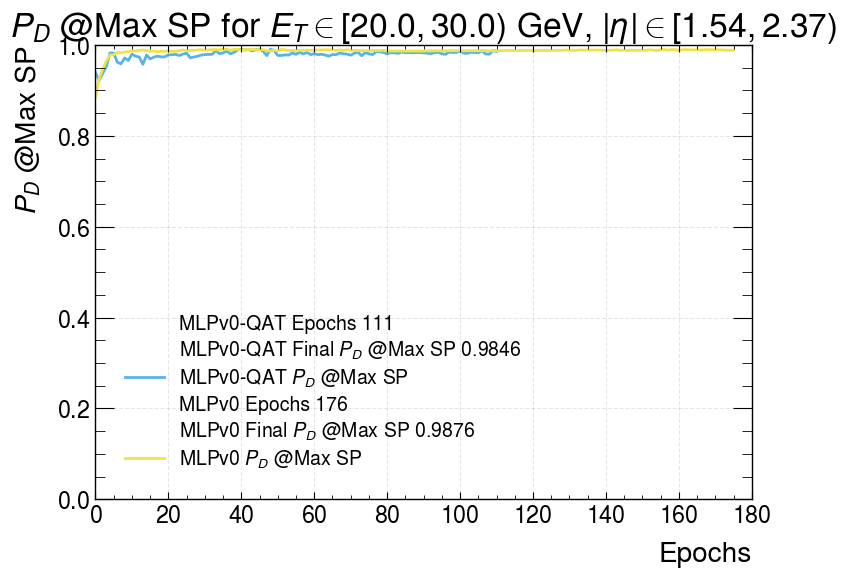

 [Thu, 09 Apr 2026 23:11:54] INFO Substituting symbol \in from Computer Modern


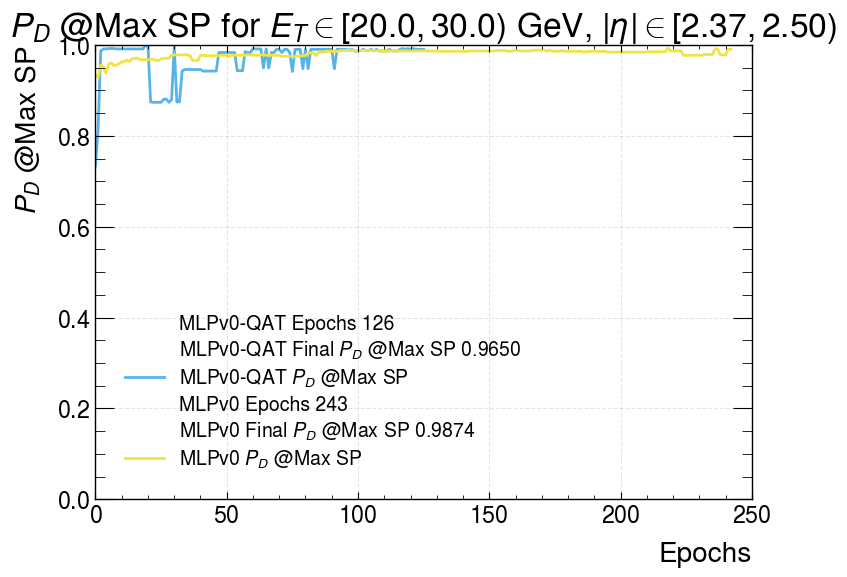

 [Thu, 09 Apr 2026 23:11:54] INFO Substituting symbol \in from Computer Modern


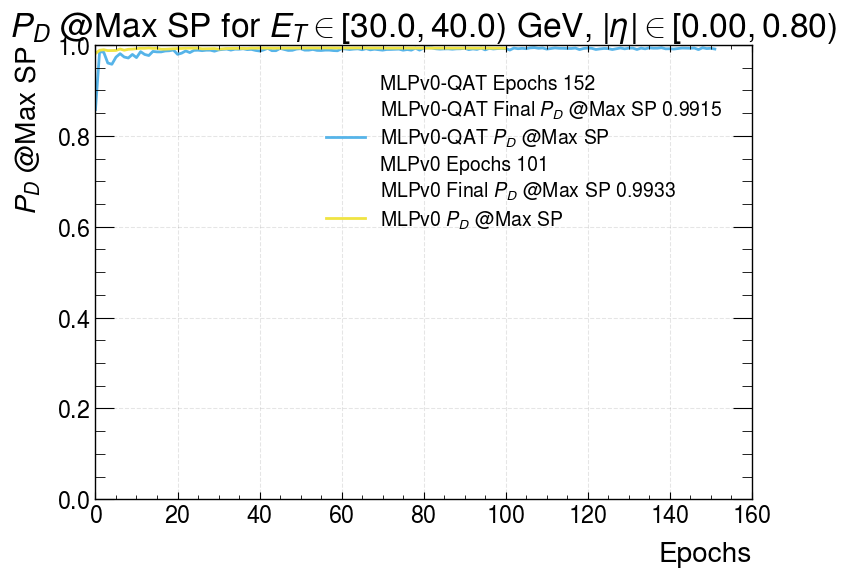

 [Thu, 09 Apr 2026 23:11:54] INFO Substituting symbol \in from Computer Modern


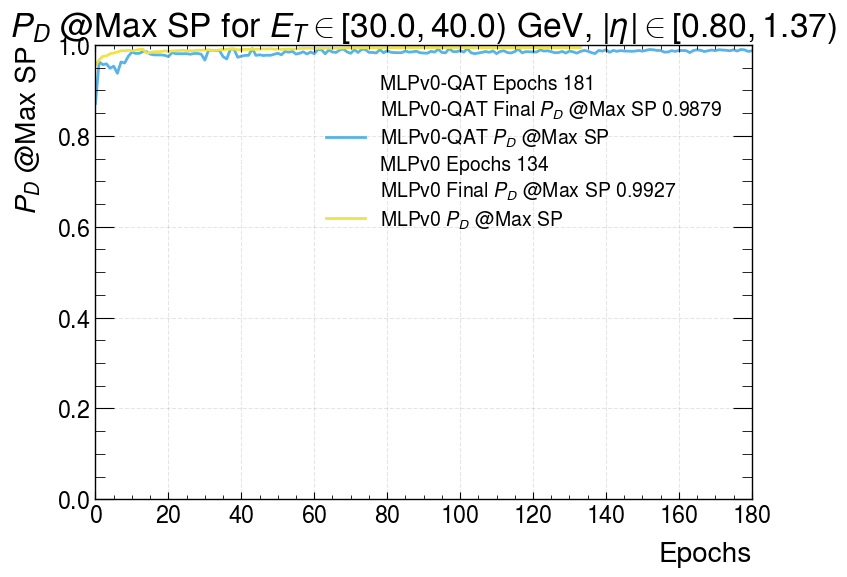

 [Thu, 09 Apr 2026 23:11:54] INFO Substituting symbol \in from Computer Modern


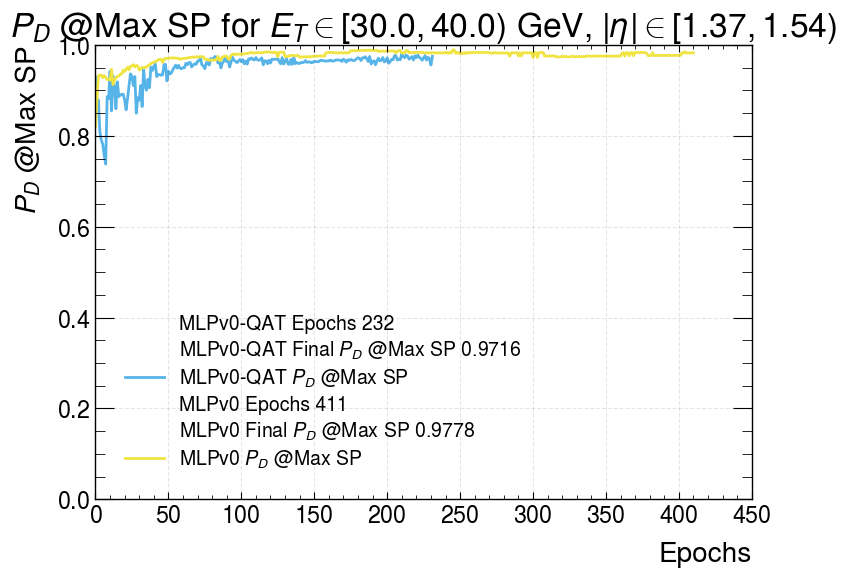

 [Thu, 09 Apr 2026 23:11:54] INFO Substituting symbol \in from Computer Modern


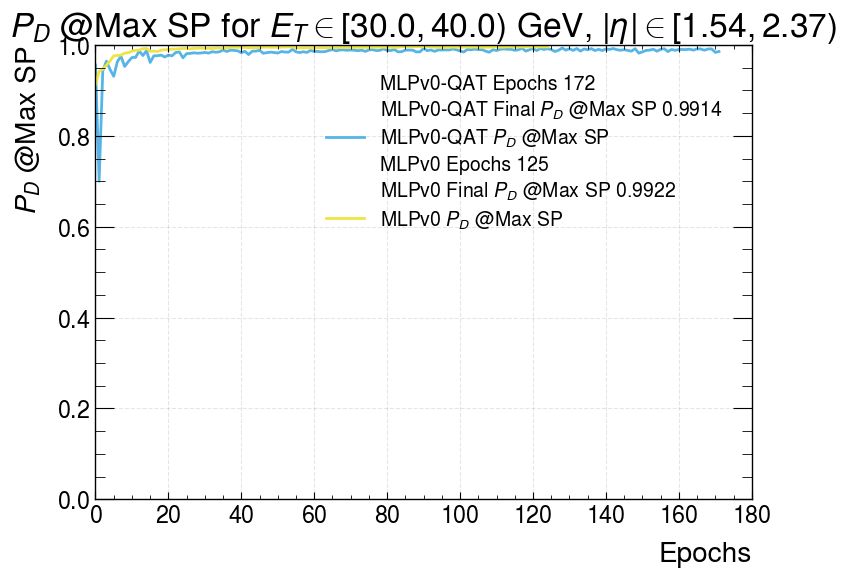

 [Thu, 09 Apr 2026 23:11:55] INFO Substituting symbol \in from Computer Modern


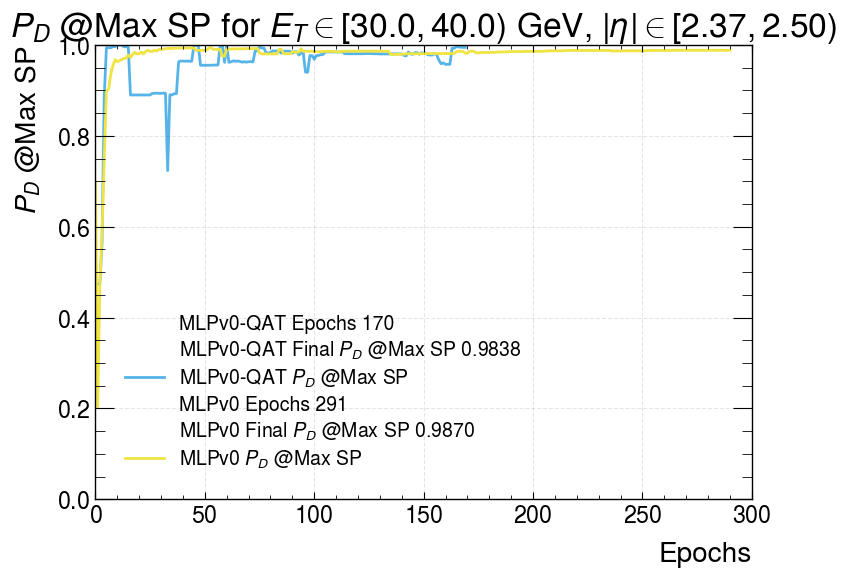

 [Thu, 09 Apr 2026 23:11:55] INFO Substituting symbol \in from Computer Modern


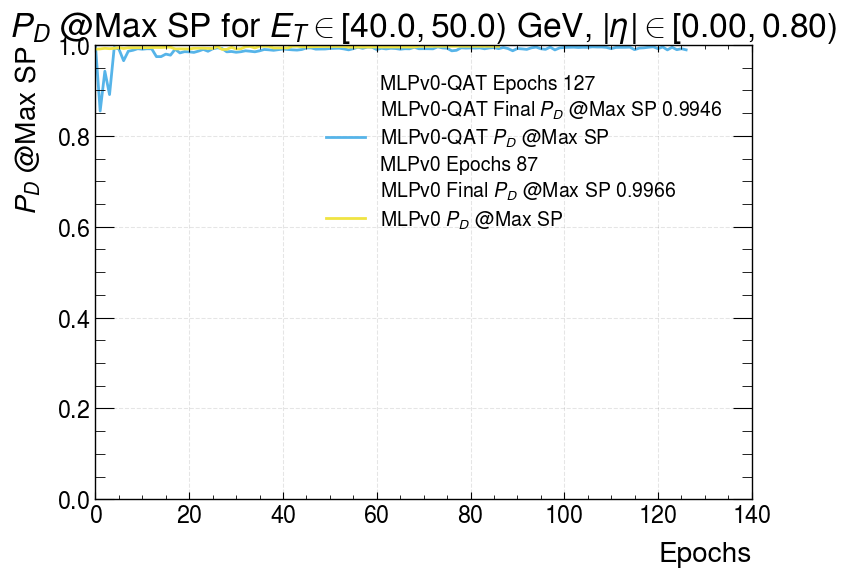

 [Thu, 09 Apr 2026 23:11:55] INFO Substituting symbol \in from Computer Modern


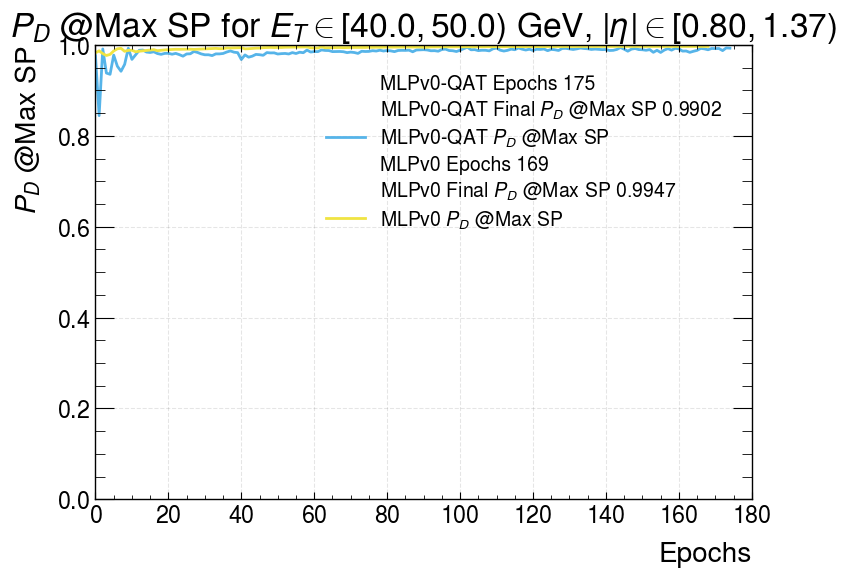

 [Thu, 09 Apr 2026 23:11:55] INFO Substituting symbol \in from Computer Modern


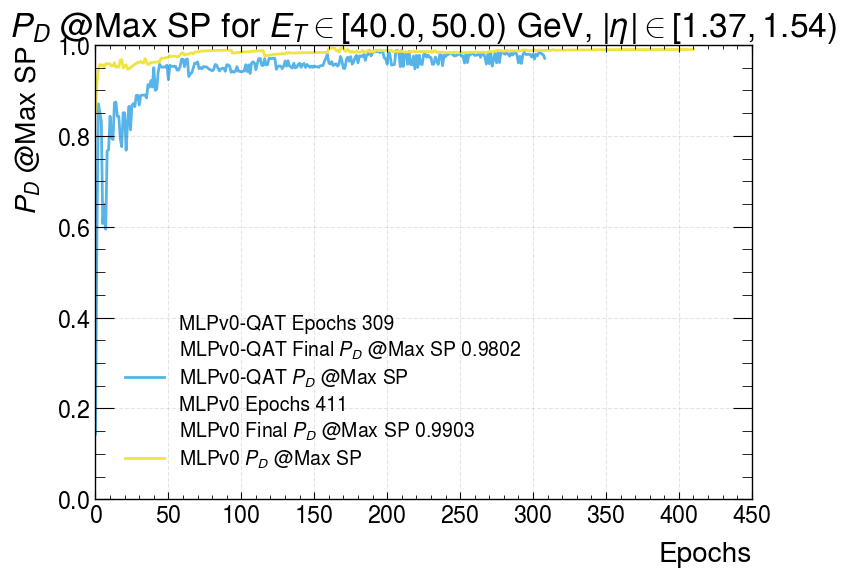

 [Thu, 09 Apr 2026 23:11:55] INFO Substituting symbol \in from Computer Modern


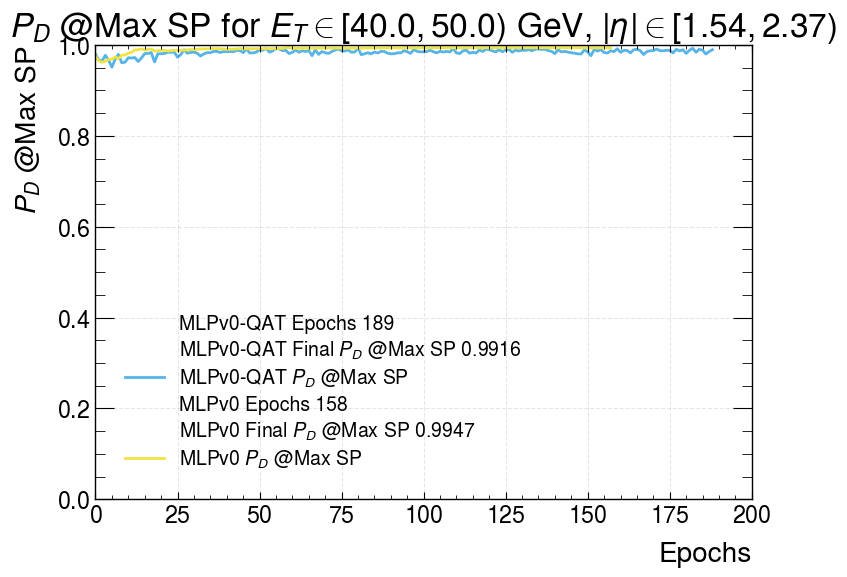

 [Thu, 09 Apr 2026 23:11:55] INFO Substituting symbol \in from Computer Modern


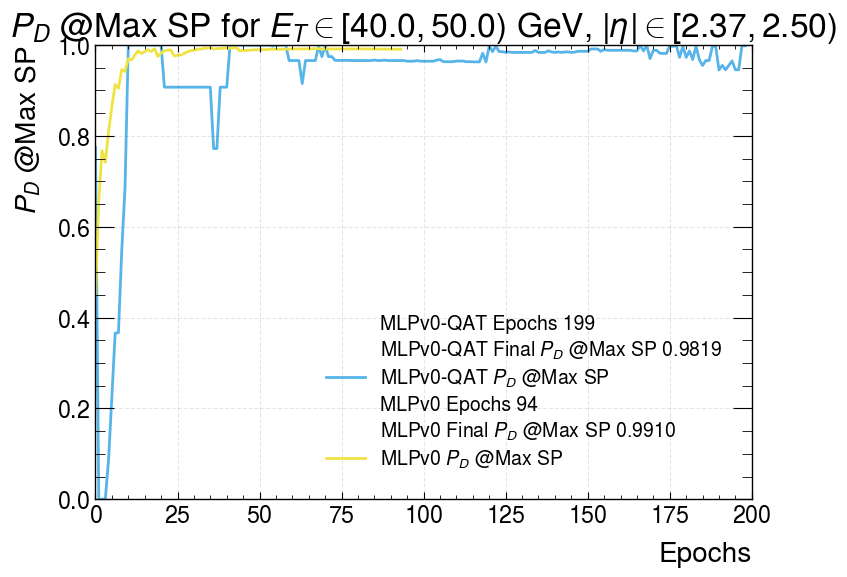

 [Thu, 09 Apr 2026 23:11:56] INFO Substituting symbol \in from Computer Modern


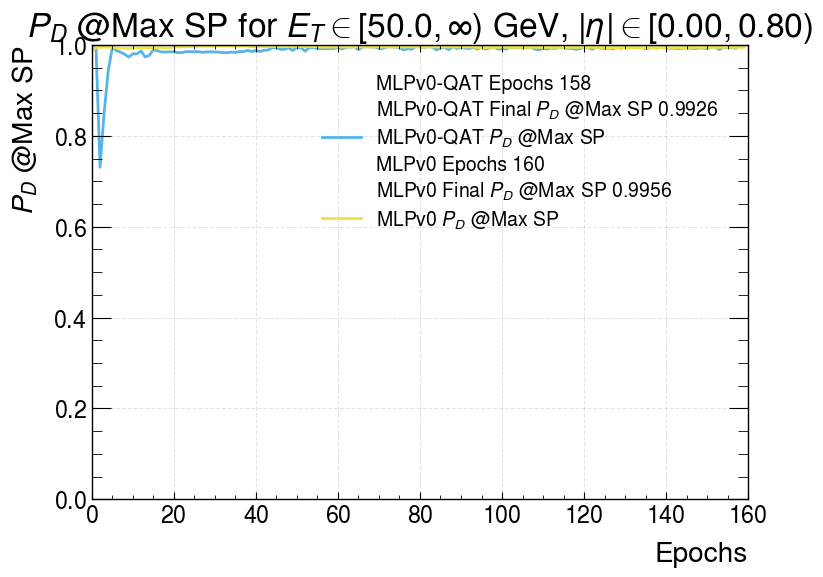

 [Thu, 09 Apr 2026 23:11:56] INFO Substituting symbol \in from Computer Modern


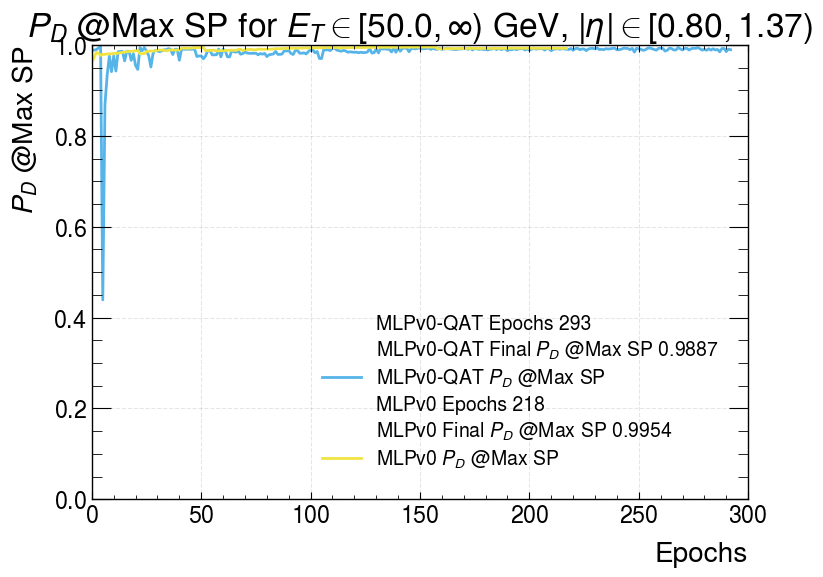

 [Thu, 09 Apr 2026 23:11:56] INFO Substituting symbol \in from Computer Modern


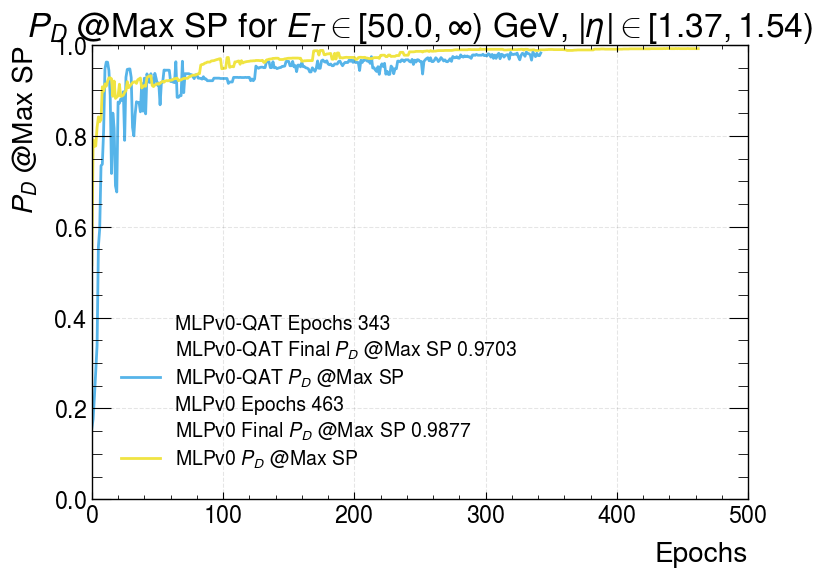

 [Thu, 09 Apr 2026 23:11:56] INFO Substituting symbol \in from Computer Modern


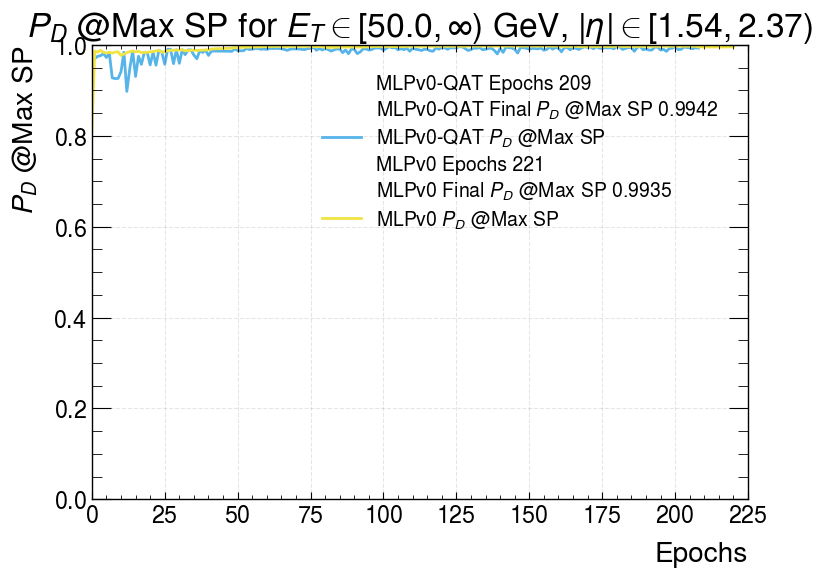

 [Thu, 09 Apr 2026 23:11:56] INFO Substituting symbol \in from Computer Modern


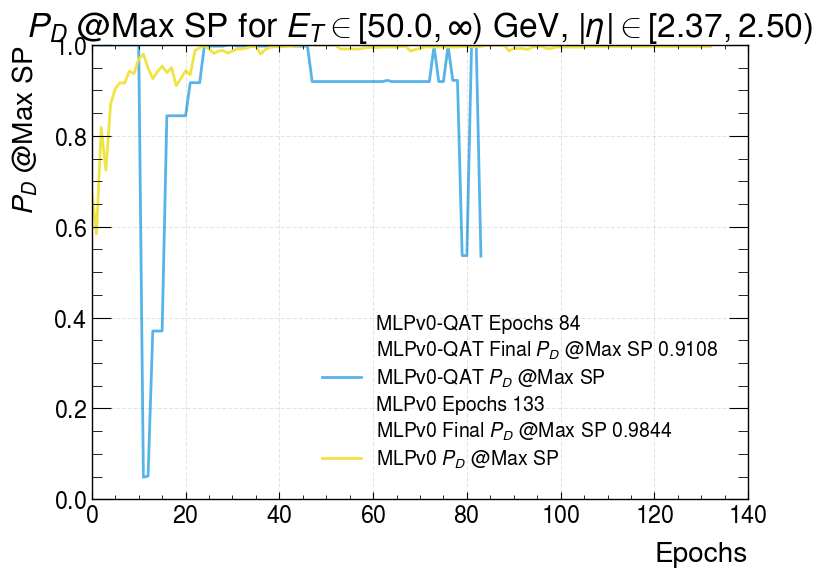

In [9]:
pd_at_max_sp_plots = plot_training_curve(
    results,
    metric='max_sp_pd_val',
    metric_label='$P_D$ @Max SP',
    summary_metric_name='max_sp_pd',
    ylim=(0, 1)
)

 [Thu, 09 Apr 2026 23:11:56] INFO Processing row with et_bin_upper: 20000.0, et_bin_lower: 15000.0, eta_bin_upper: 0.8, eta_bin_lower: 0.0
 [Thu, 09 Apr 2026 23:11:57] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:11:57] INFO Processing row with et_bin_upper: 20000.0, et_bin_lower: 15000.0, eta_bin_upper: 1.37, eta_bin_lower: 0.8
 [Thu, 09 Apr 2026 23:11:57] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:11:57] INFO Processing row with et_bin_upper: 20000.0, et_bin_lower: 15000.0, eta_bin_upper: 1.54, eta_bin_lower: 1.37
 [Thu, 09 Apr 2026 23:11:57] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:11:57] INFO Processing row with et_bin_upper: 20000.0, et_bin_lower: 15000.0, eta_bin_upper: 2.37, eta_bin_lower: 1.54
 [Thu, 09 Apr 2026 23:11:57] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:11:57] INFO Processing row with et_bin_upper: 20000.0, et_bin_lower: 15000.0, eta_bin_upper: 2.500000

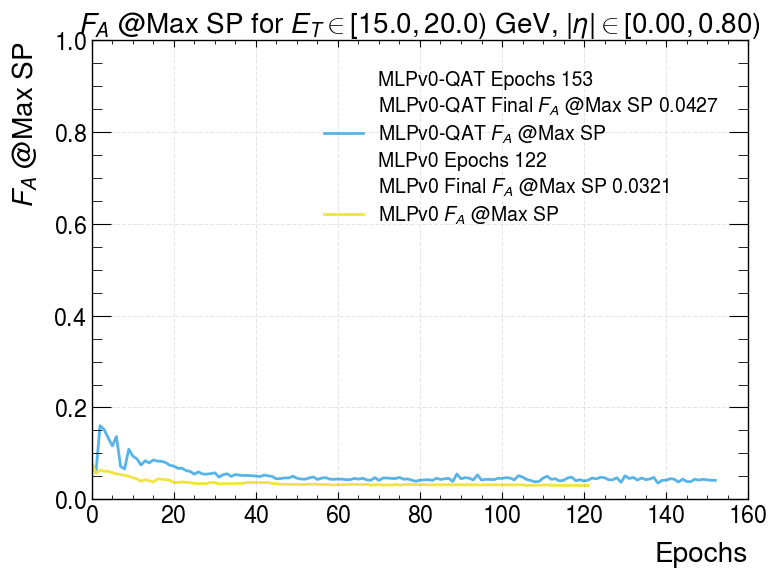

 [Thu, 09 Apr 2026 23:12:04] INFO Substituting symbol \in from Computer Modern


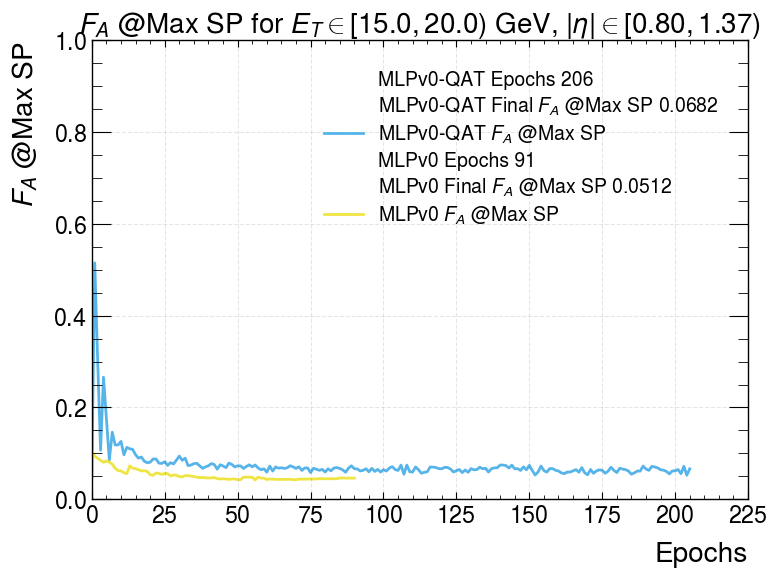

 [Thu, 09 Apr 2026 23:12:04] INFO Substituting symbol \in from Computer Modern


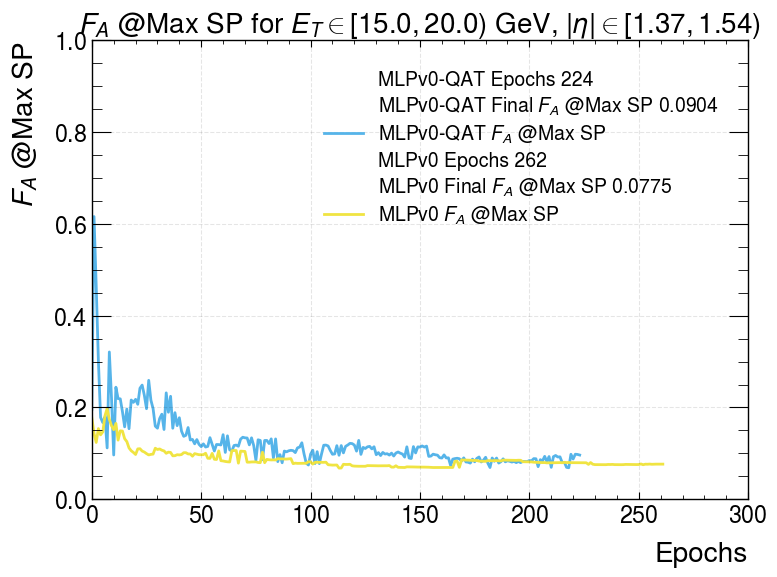

 [Thu, 09 Apr 2026 23:12:04] INFO Substituting symbol \in from Computer Modern


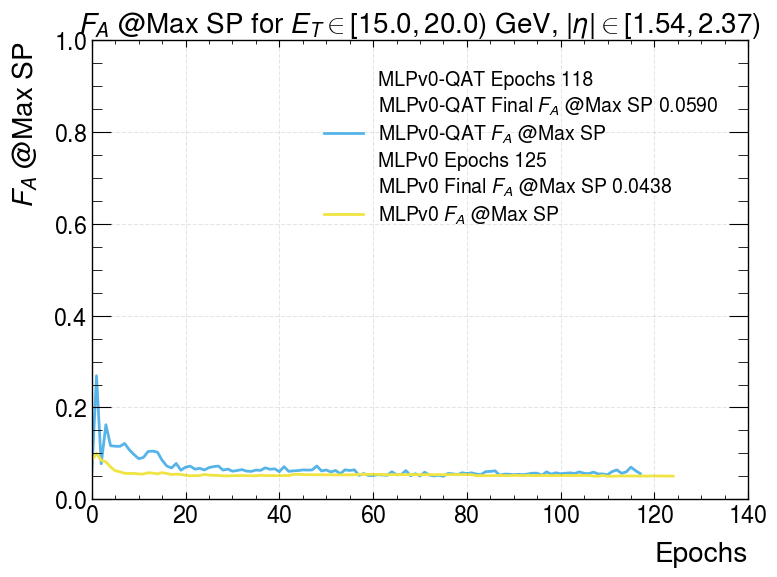

 [Thu, 09 Apr 2026 23:12:04] INFO Substituting symbol \in from Computer Modern


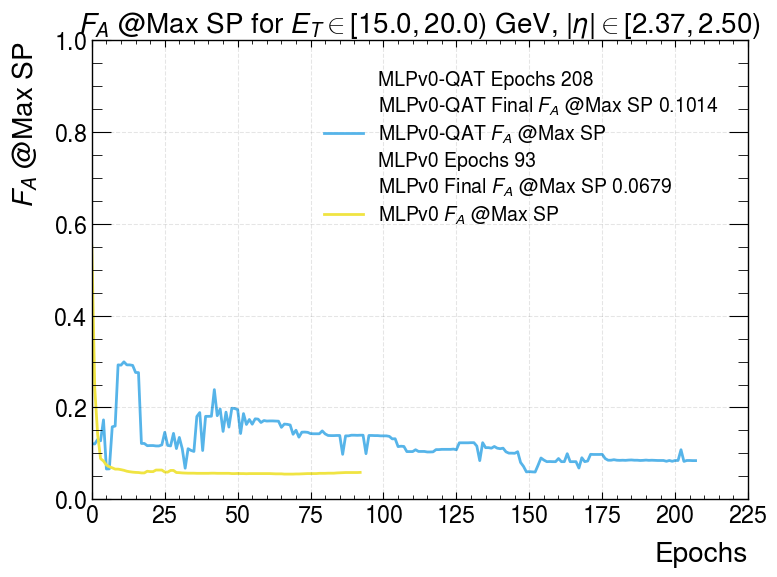

 [Thu, 09 Apr 2026 23:12:04] INFO Substituting symbol \in from Computer Modern


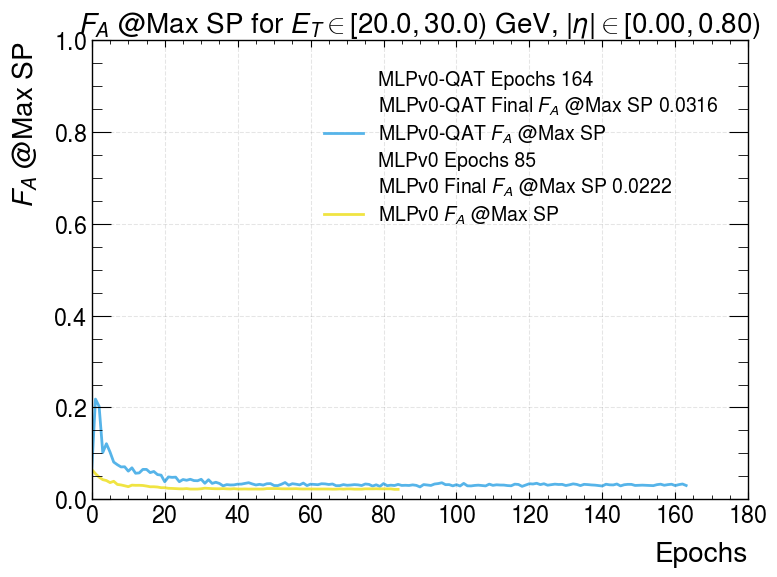

 [Thu, 09 Apr 2026 23:12:04] INFO Substituting symbol \in from Computer Modern


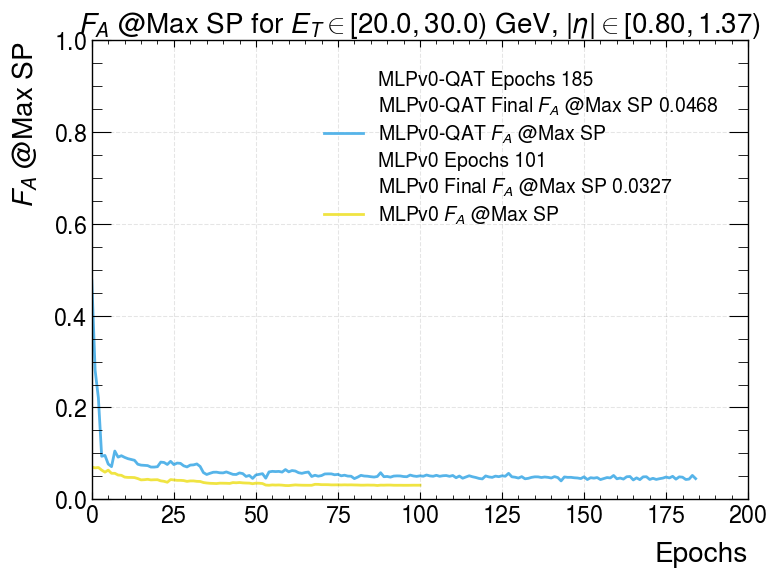

 [Thu, 09 Apr 2026 23:12:04] INFO Substituting symbol \in from Computer Modern


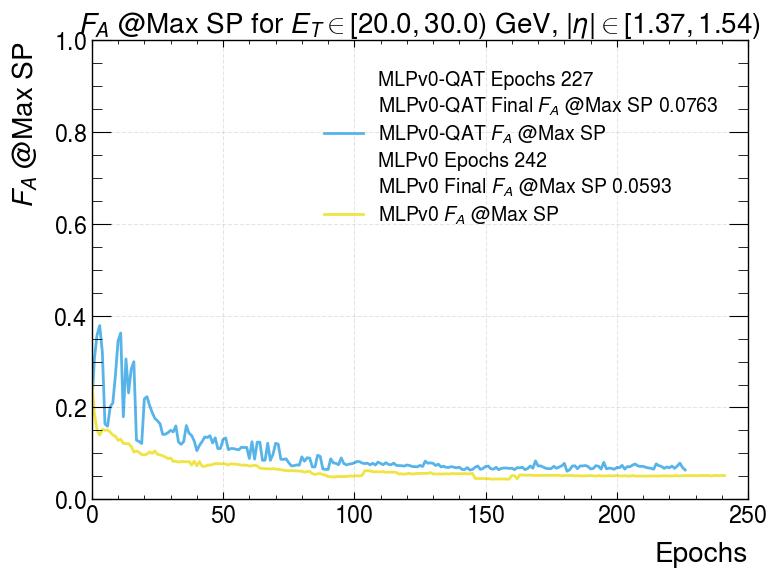

 [Thu, 09 Apr 2026 23:12:05] INFO Substituting symbol \in from Computer Modern


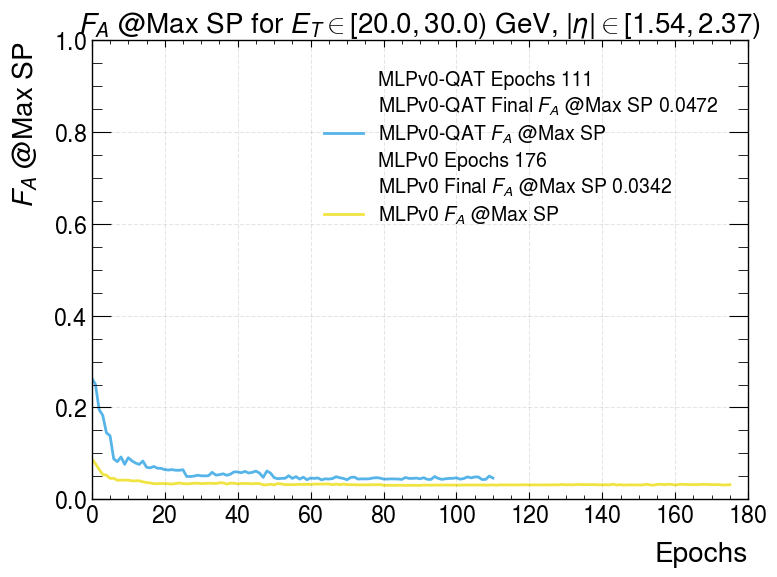

 [Thu, 09 Apr 2026 23:12:05] INFO Substituting symbol \in from Computer Modern


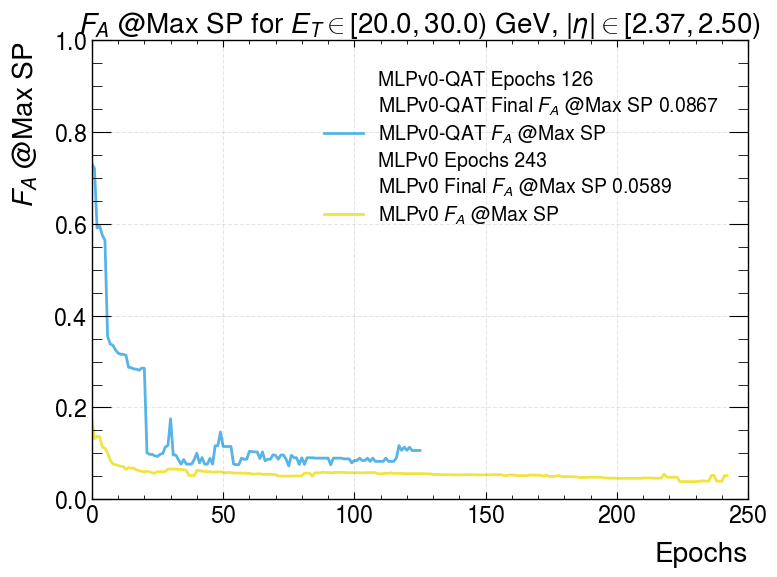

 [Thu, 09 Apr 2026 23:12:05] INFO Substituting symbol \in from Computer Modern


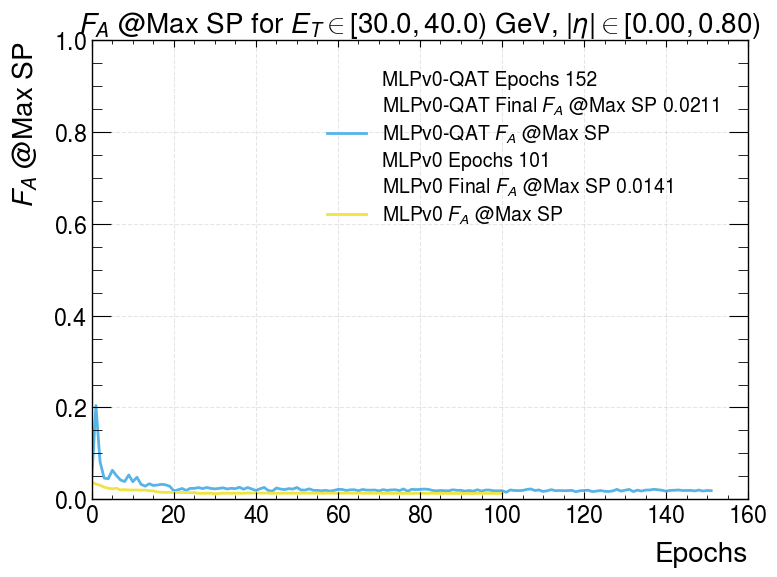

 [Thu, 09 Apr 2026 23:12:05] INFO Substituting symbol \in from Computer Modern


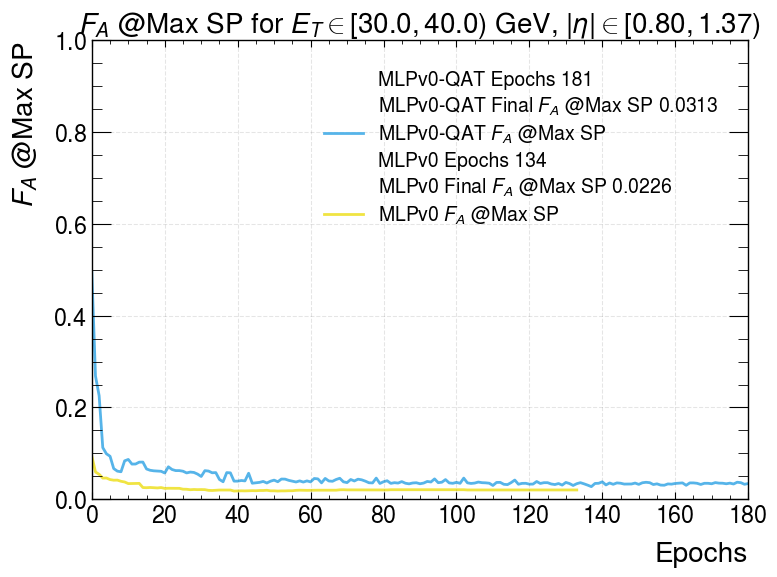

 [Thu, 09 Apr 2026 23:12:05] INFO Substituting symbol \in from Computer Modern


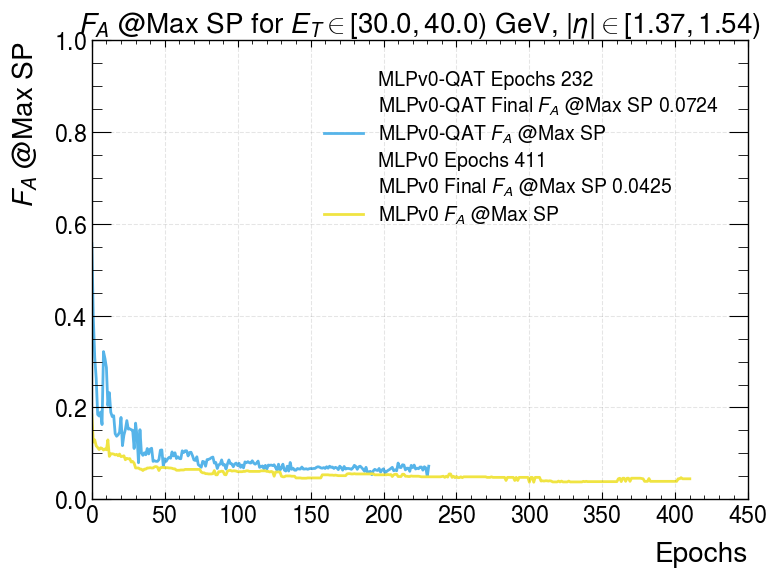

 [Thu, 09 Apr 2026 23:12:05] INFO Substituting symbol \in from Computer Modern


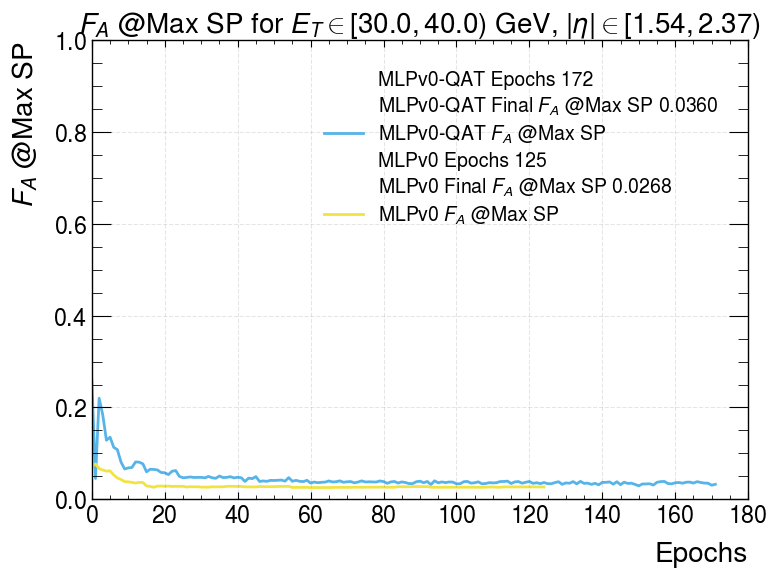

 [Thu, 09 Apr 2026 23:12:05] INFO Substituting symbol \in from Computer Modern


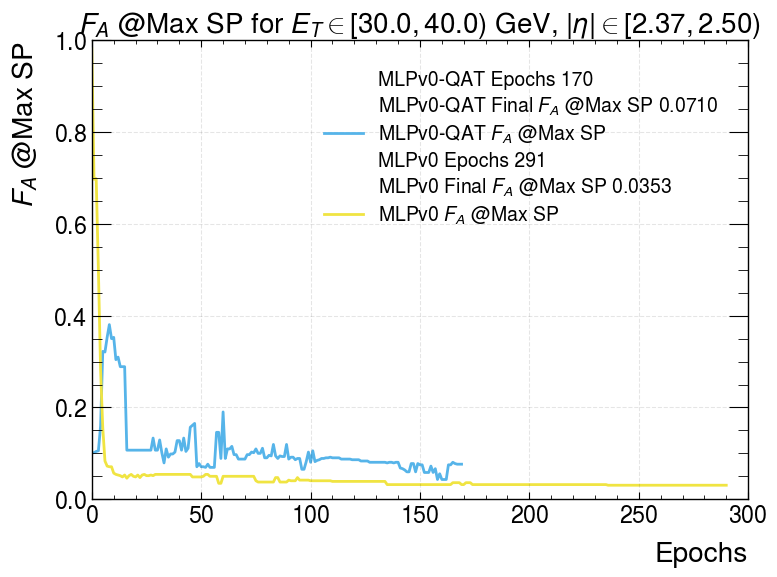

 [Thu, 09 Apr 2026 23:12:06] INFO Substituting symbol \in from Computer Modern


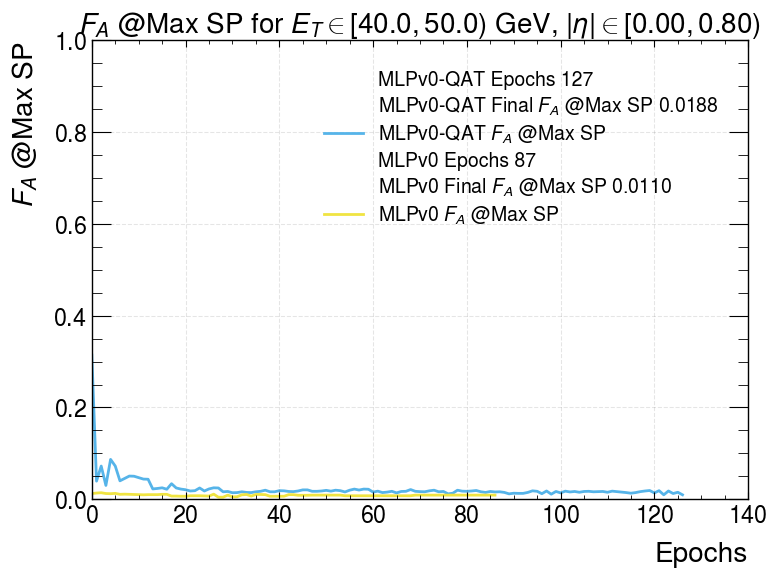

 [Thu, 09 Apr 2026 23:12:06] INFO Substituting symbol \in from Computer Modern


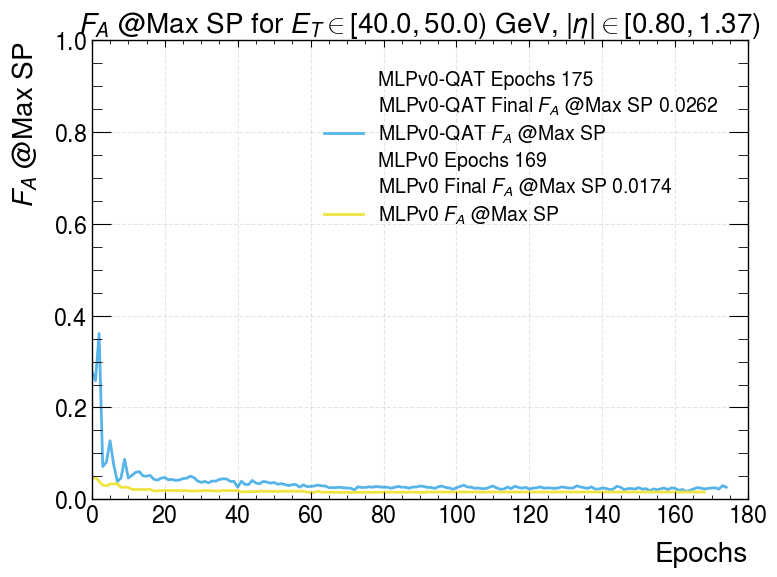

 [Thu, 09 Apr 2026 23:12:06] INFO Substituting symbol \in from Computer Modern


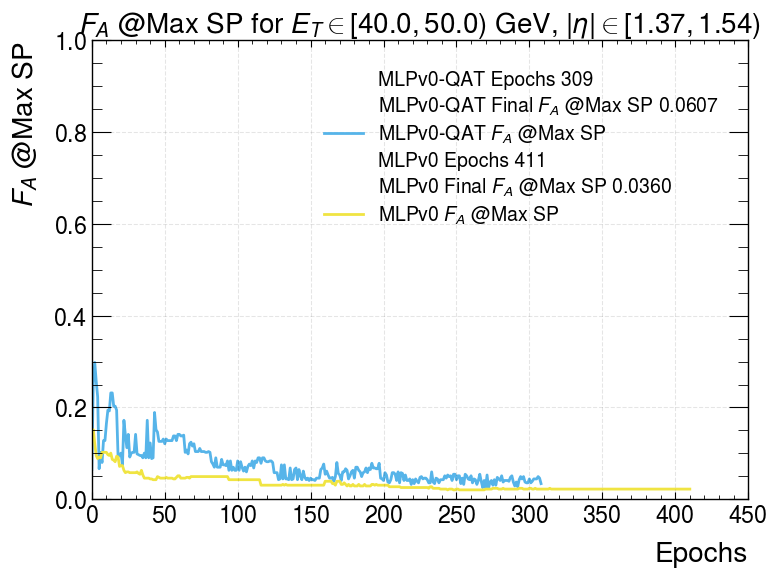

 [Thu, 09 Apr 2026 23:12:06] INFO Substituting symbol \in from Computer Modern


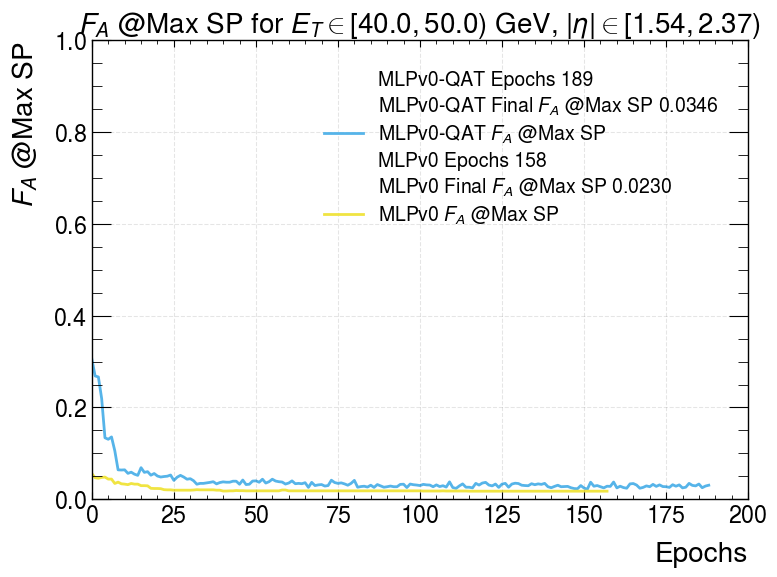

 [Thu, 09 Apr 2026 23:12:07] INFO Substituting symbol \in from Computer Modern


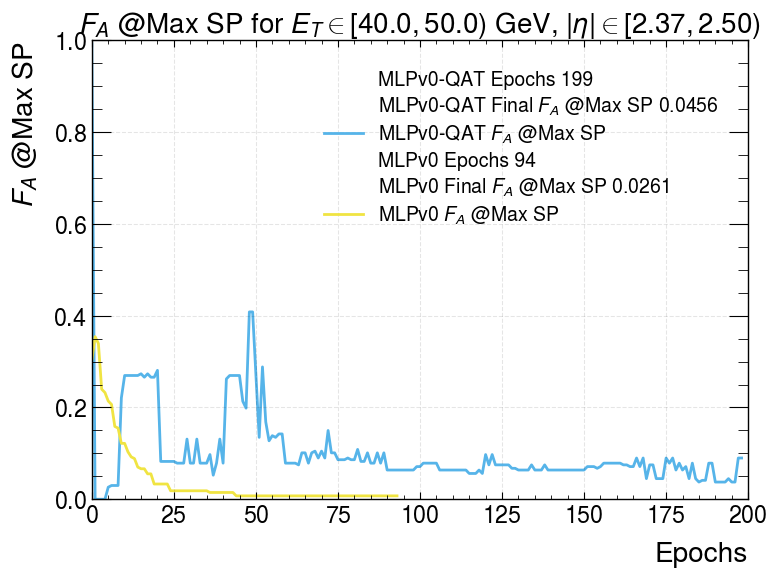

 [Thu, 09 Apr 2026 23:12:07] INFO Substituting symbol \in from Computer Modern


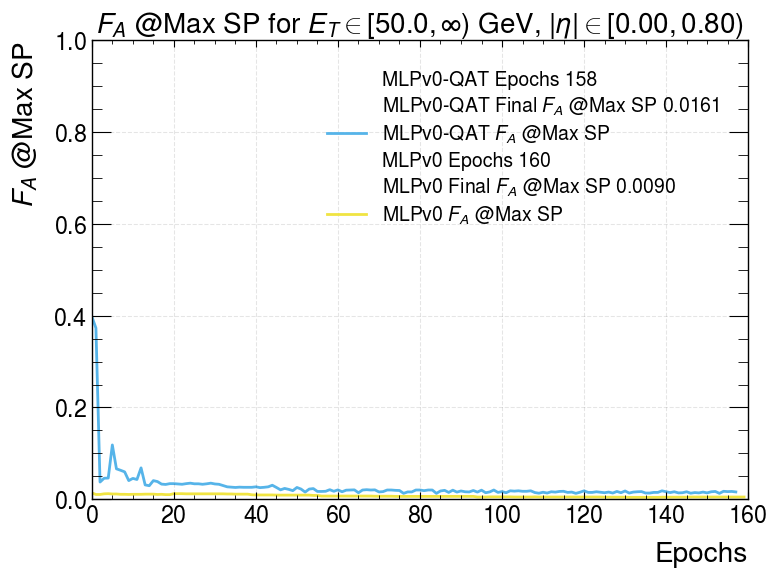

 [Thu, 09 Apr 2026 23:12:07] INFO Substituting symbol \in from Computer Modern


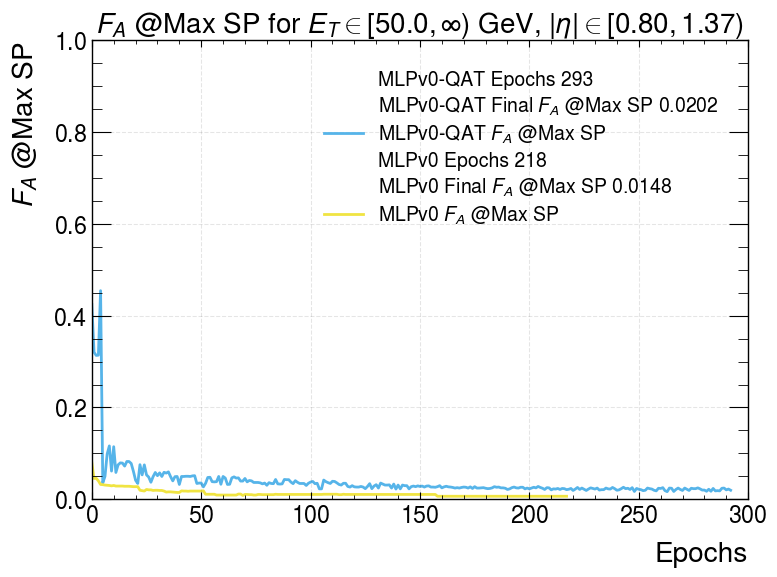

 [Thu, 09 Apr 2026 23:12:07] INFO Substituting symbol \in from Computer Modern


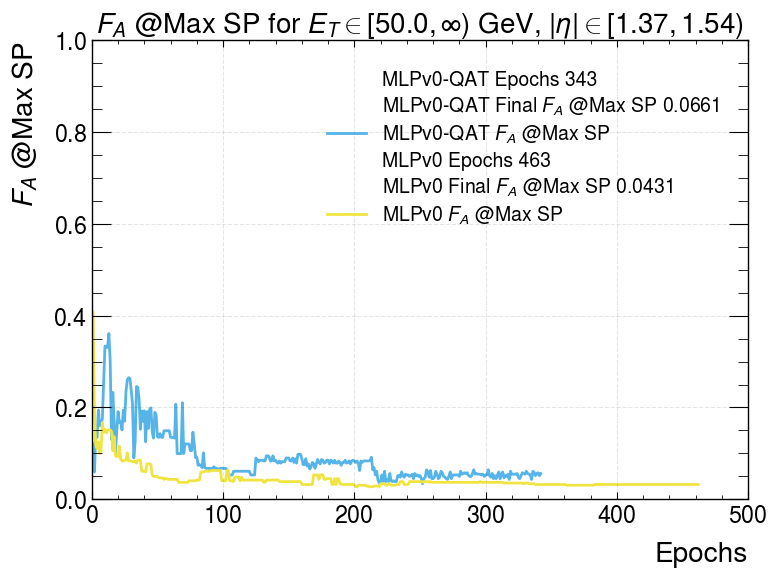

 [Thu, 09 Apr 2026 23:12:07] INFO Substituting symbol \in from Computer Modern


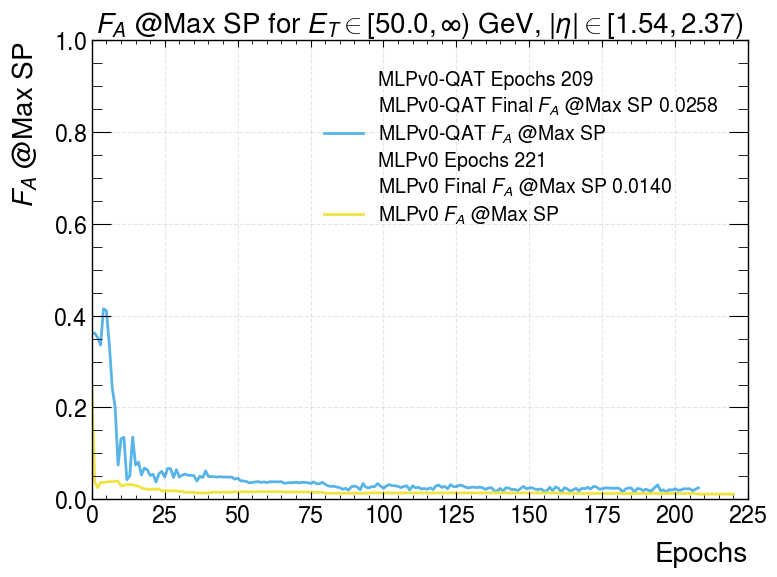

 [Thu, 09 Apr 2026 23:12:07] INFO Substituting symbol \in from Computer Modern


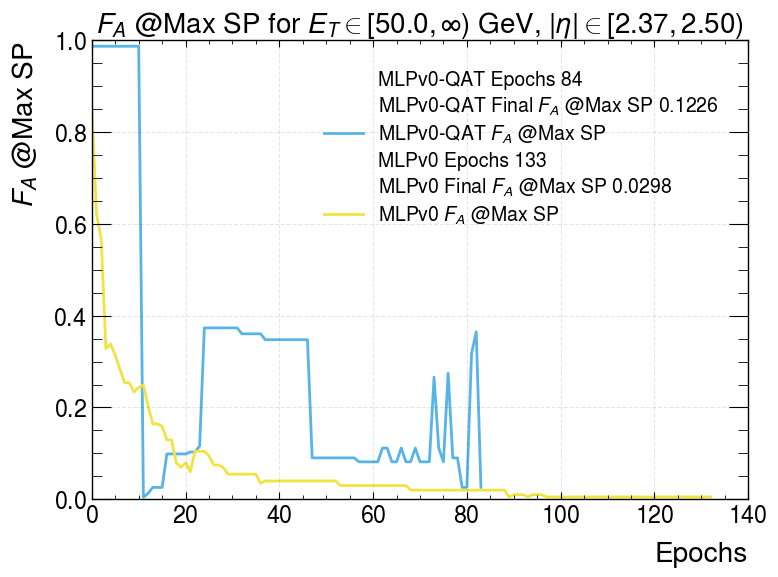

In [10]:
fa_at_max_sp_plots = plot_training_curve(
    results,
    metric='max_sp_fa_val',
    metric_label='$F_A$ @Max SP',
    summary_metric_name='max_sp_fa',
    ylim=(0, 1),
    title_kwargs=dict(fontsize=20)
)

In [11]:
def plot_training_curve_variations(
    model_results: dict,
    metric: str,
    metric_label: str,
    summary_metric_name: str | None = None,
    ylim: tuple[float, float] | None = None,
    legend_kwargs: dict | None = None,
    title_kwargs: dict | None = None,
    gray_alpha: float = 0.1
) -> list[tuple[plt.Figure, plt.Axes]]:
    plots = []
    for row in model_results['best_models_df'].iter_rows(named=True):
        et_bin_upper = row['et_bin_upper']
        et_bin_lower = row['et_bin_lower']
        eta_bin_upper = row['eta_bin_upper']
        eta_bin_lower = row['eta_bin_lower']
        logger.info(f'Processing row with et_bin_upper: {et_bin_upper}, et_bin_lower: {et_bin_lower}, eta_bin_upper: {eta_bin_upper}, eta_bin_lower: {eta_bin_lower}')
        fig, ax = plt.subplots()

        this_bin_df = model_results['results_df'].filter(
            (pl.col('et_bin_upper') == et_bin_upper) &
            (pl.col('et_bin_lower') == et_bin_lower) &
            (pl.col('eta_bin_upper') == eta_bin_upper) &
            (pl.col('eta_bin_lower') == eta_bin_lower)
        )
        if this_bin_df.is_empty():
            logger.warning(f"No data found for et_bin_upper: {et_bin_upper}, et_bin_lower: {et_bin_lower}, eta_bin_upper: {eta_bin_upper}, eta_bin_lower: {eta_bin_lower}")
            continue

        # metric_mean = this_bin_df[metric].mean()
        # metric_std = this_bin_df[metric].std()
        # ax.plot([], [], ' ', label=model_results['label'])
        # ax.plot([], [], ' ', label=f'{metric_label} ${metric_mean:.4f} \\pm {metric_std:.4f}$')

        first_gray = True
        for i, fold_init_training in enumerate(this_bin_df.iter_rows(named=True)):
            logger.info(f'Processing fold/init variation {i+1}')
            fold = fold_init_training['sort']
            init = fold_init_training['init']
            logger.info(f'Processing fold: {fold}, init: {init}')
            label='Unselected' if first_gray else None
            first_gray = False

            if fold == row['sort'] and init == row['init']:
                ax.plot(fold_init_training[metric], label='Selected', color=model_results['train_color'], alpha=1)
            else:
                ax.plot(fold_init_training[metric], label=label, color='k', alpha=gray_alpha)
        
        if title_kwargs is None:
            title_kwargs = {}
        
        if math.isinf(et_bin_upper):
            title = f'{model_results["label"]} {metric_label} for $E_T \\in [{et_bin_lower/1e3:.1f}, \\infty)$ GeV, $|\\eta| \\in [{eta_bin_lower:.2f}, {eta_bin_upper:.2f})$'
        else:
            title = f'{model_results["label"]} {metric_label} for $E_T \\in [{et_bin_lower/1e3:.1f}, {et_bin_upper/1e3:.1f})$ GeV, $|\\eta| \\in [{eta_bin_lower:.2f}, {eta_bin_upper:.2f})$'

        ax.set_title(title, **title_kwargs)
        ax.set(
            xlabel='Epochs',
            ylabel=metric_label,
            ylim=ylim
        )
        if legend_kwargs is None:
            legend_kwargs = {}
        ax.legend(**legend_kwargs)
        ax.grid(linestyle='--', alpha=0.1, color='k')
        fig.tight_layout()
        plots.append((fig, ax))
    return plots

 [Thu, 09 Apr 2026 23:12:07] INFO Processing row with et_bin_upper: 20000.0, et_bin_lower: 15000.0, eta_bin_upper: 0.8, eta_bin_lower: 0.0
 [Thu, 09 Apr 2026 23:12:07] INFO Processing fold/init variation 1
 [Thu, 09 Apr 2026 23:12:07] INFO Processing fold: 0, init: 0
 [Thu, 09 Apr 2026 23:12:07] INFO Processing fold/init variation 2
 [Thu, 09 Apr 2026 23:12:07] INFO Processing fold: 0, init: 1
 [Thu, 09 Apr 2026 23:12:07] INFO Processing fold/init variation 3
 [Thu, 09 Apr 2026 23:12:07] INFO Processing fold: 0, init: 2
 [Thu, 09 Apr 2026 23:12:07] INFO Processing fold/init variation 4
 [Thu, 09 Apr 2026 23:12:07] INFO Processing fold: 0, init: 3
 [Thu, 09 Apr 2026 23:12:07] INFO Processing fold/init variation 5
 [Thu, 09 Apr 2026 23:12:07] INFO Processing fold: 0, init: 4
 [Thu, 09 Apr 2026 23:12:07] INFO Processing fold/init variation 6
 [Thu, 09 Apr 2026 23:12:07] INFO Processing fold: 1, init: 0
 [Thu, 09 Apr 2026 23:12:07] INFO Processing fold/init variation 7
 [Thu, 09 Apr 2026 2

[(<Figure size 800x600 with 1 Axes>,
  <Axes: title={'center': 'MLPv0-QAT Max SP for $E_T \\in [15.0, 20.0)$ GeV, $|\\eta| \\in [0.00, 0.80)$'}, xlabel='Epochs', ylabel='Max SP'>),
 (<Figure size 800x600 with 1 Axes>,
  <Axes: title={'center': 'MLPv0-QAT Max SP for $E_T \\in [15.0, 20.0)$ GeV, $|\\eta| \\in [0.80, 1.37)$'}, xlabel='Epochs', ylabel='Max SP'>),
 (<Figure size 800x600 with 1 Axes>,
  <Axes: title={'center': 'MLPv0-QAT Max SP for $E_T \\in [15.0, 20.0)$ GeV, $|\\eta| \\in [1.37, 1.54)$'}, xlabel='Epochs', ylabel='Max SP'>),
 (<Figure size 800x600 with 1 Axes>,
  <Axes: title={'center': 'MLPv0-QAT Max SP for $E_T \\in [15.0, 20.0)$ GeV, $|\\eta| \\in [1.54, 2.37)$'}, xlabel='Epochs', ylabel='Max SP'>),
 (<Figure size 800x600 with 1 Axes>,
  <Axes: title={'center': 'MLPv0-QAT Max SP for $E_T \\in [15.0, 20.0)$ GeV, $|\\eta| \\in [2.37, 2.50)$'}, xlabel='Epochs', ylabel='Max SP'>),
 (<Figure size 800x600 with 1 Axes>,
  <Axes: title={'center': 'MLPv0-QAT Max SP for $E_T \\in 

 [Thu, 09 Apr 2026 23:12:13] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:13] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:13] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:13] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:13] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:13] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:13] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:14] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:14] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:14] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:14] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:14] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:14] INFO Substituting symbo

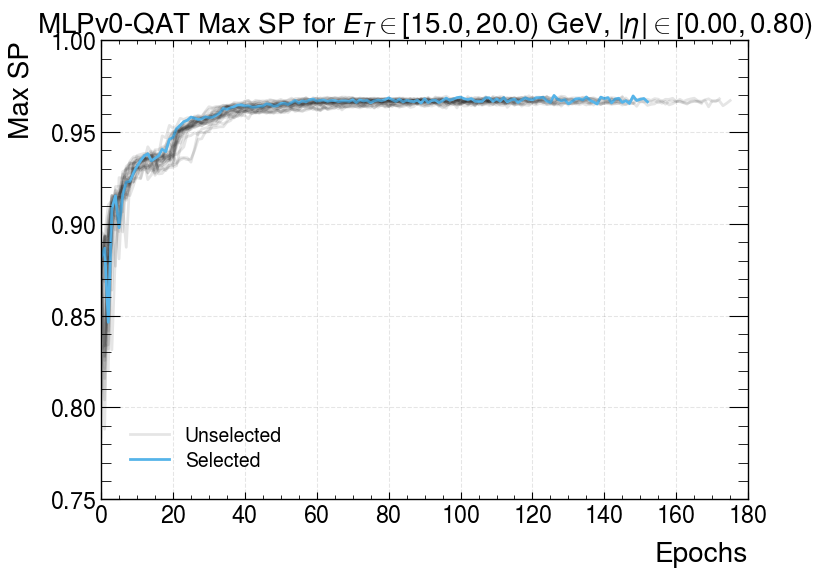

 [Thu, 09 Apr 2026 23:12:15] INFO Substituting symbol \in from Computer Modern


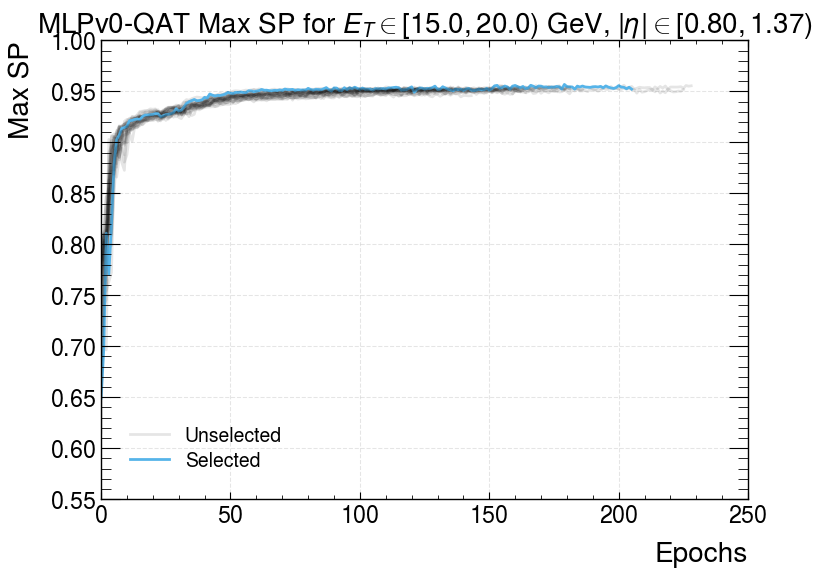

 [Thu, 09 Apr 2026 23:12:15] INFO Substituting symbol \in from Computer Modern


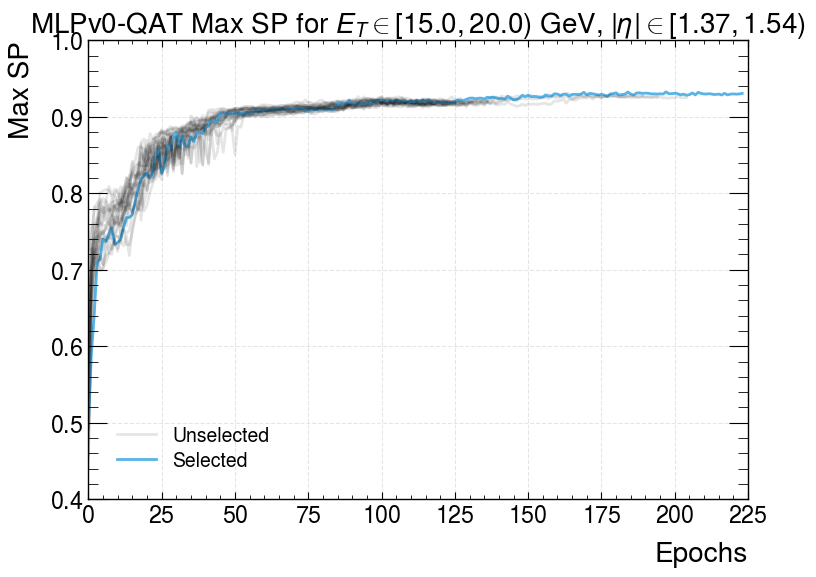

 [Thu, 09 Apr 2026 23:12:15] INFO Substituting symbol \in from Computer Modern


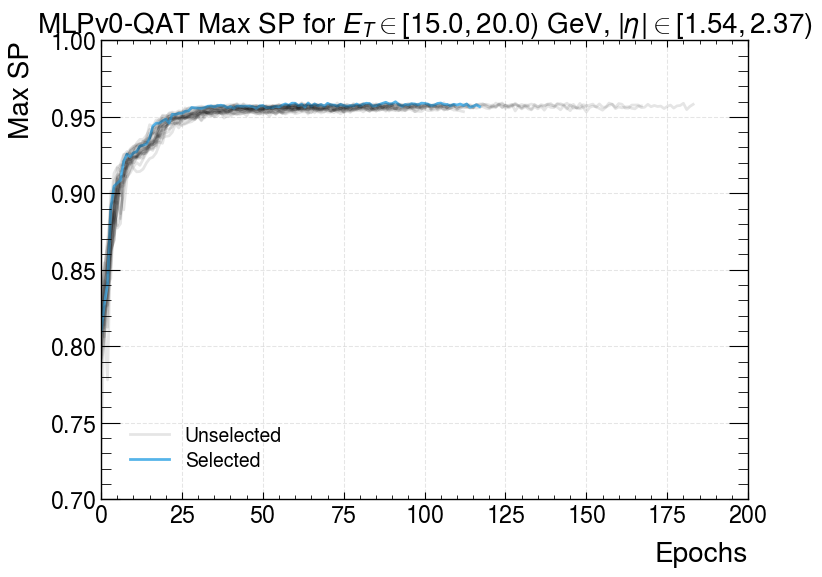

 [Thu, 09 Apr 2026 23:12:15] INFO Substituting symbol \in from Computer Modern


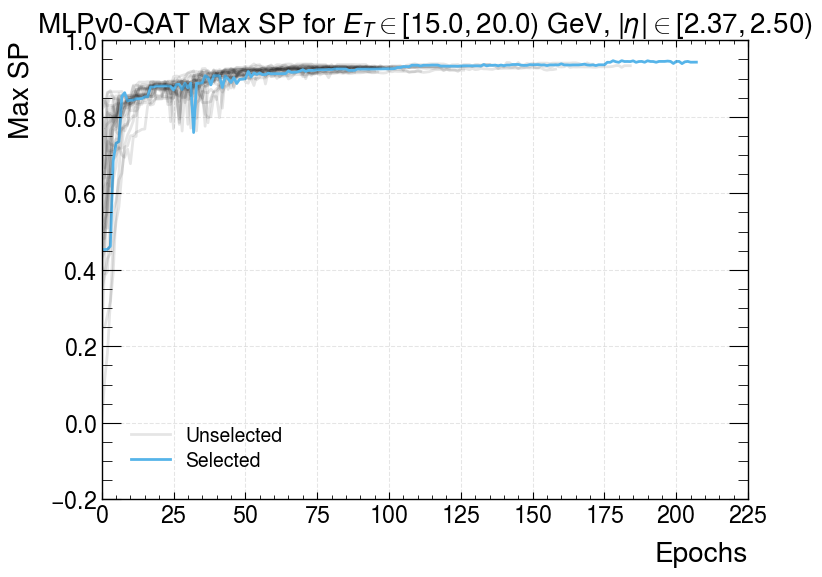

 [Thu, 09 Apr 2026 23:12:16] INFO Substituting symbol \in from Computer Modern


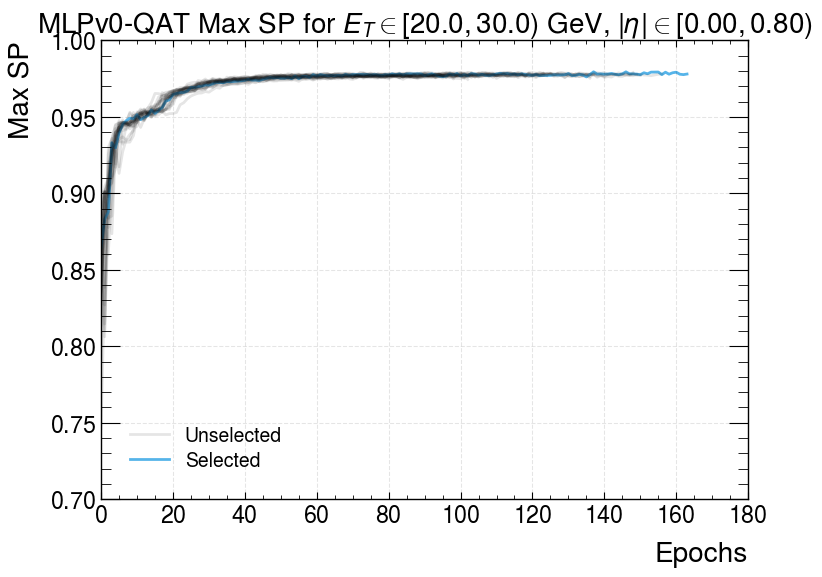

 [Thu, 09 Apr 2026 23:12:16] INFO Substituting symbol \in from Computer Modern


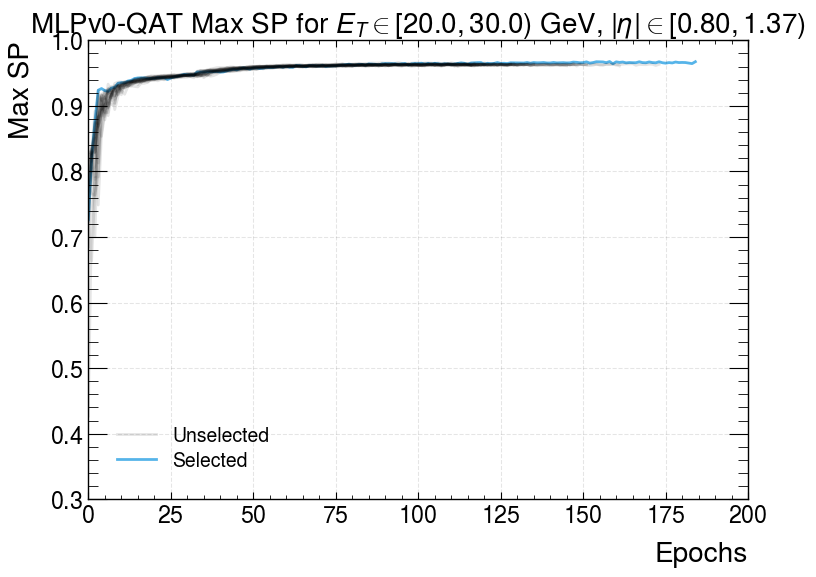

 [Thu, 09 Apr 2026 23:12:16] INFO Substituting symbol \in from Computer Modern


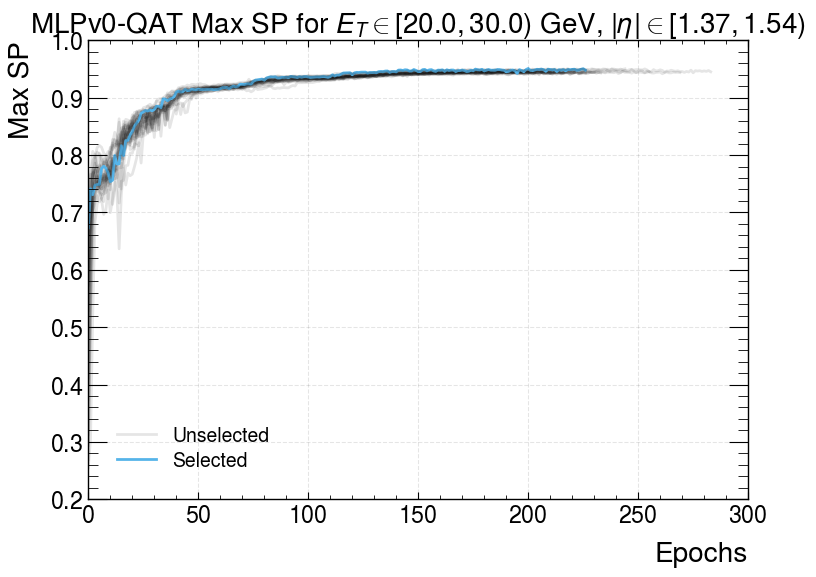

 [Thu, 09 Apr 2026 23:12:16] INFO Substituting symbol \in from Computer Modern


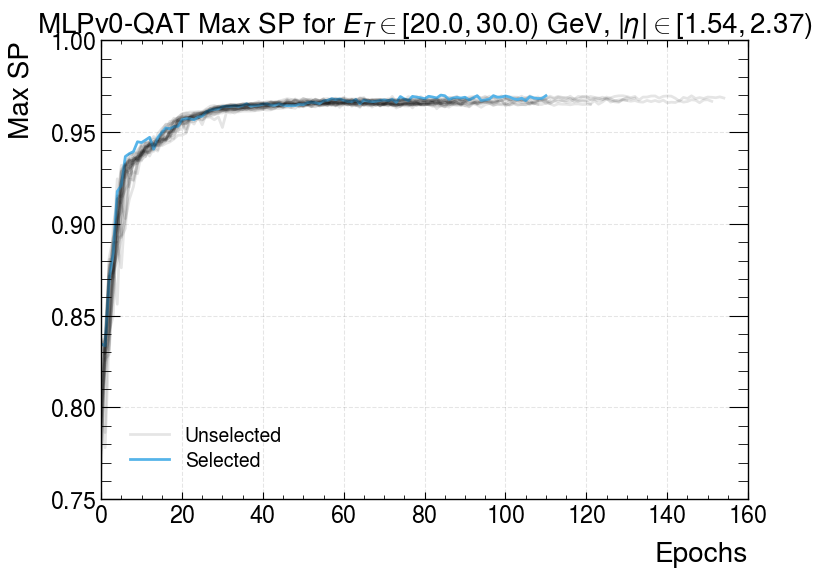

 [Thu, 09 Apr 2026 23:12:16] INFO Substituting symbol \in from Computer Modern


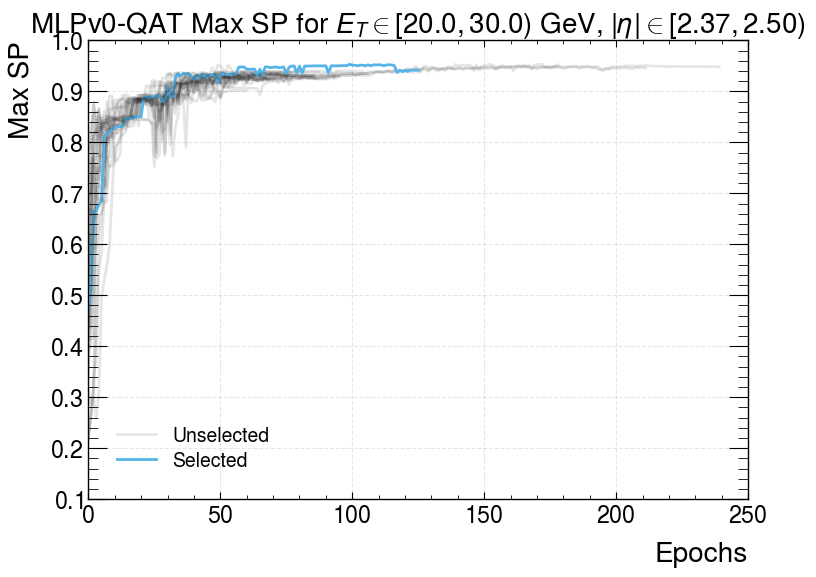

 [Thu, 09 Apr 2026 23:12:16] INFO Substituting symbol \in from Computer Modern


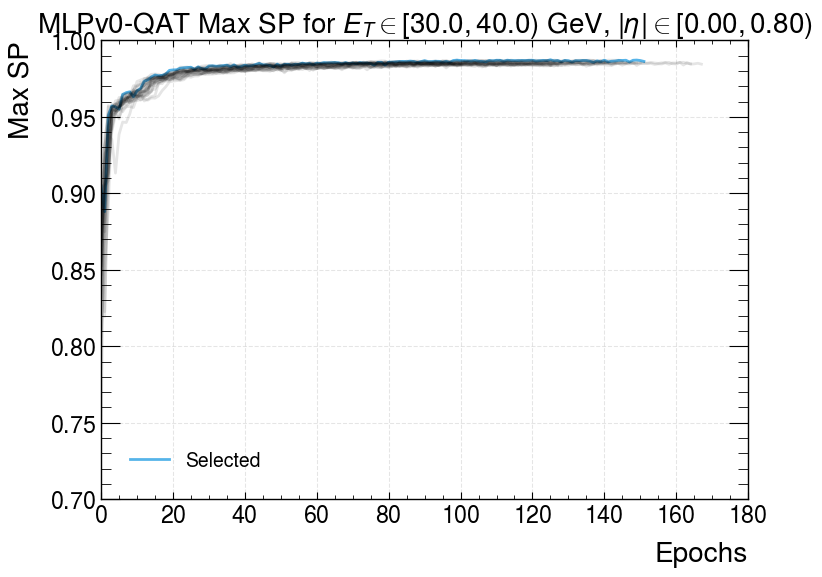

 [Thu, 09 Apr 2026 23:12:16] INFO Substituting symbol \in from Computer Modern


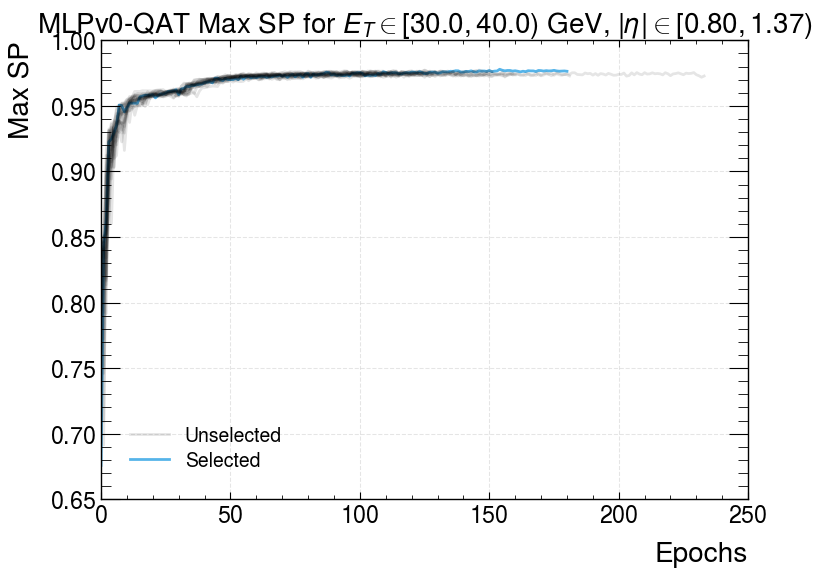

 [Thu, 09 Apr 2026 23:12:17] INFO Substituting symbol \in from Computer Modern


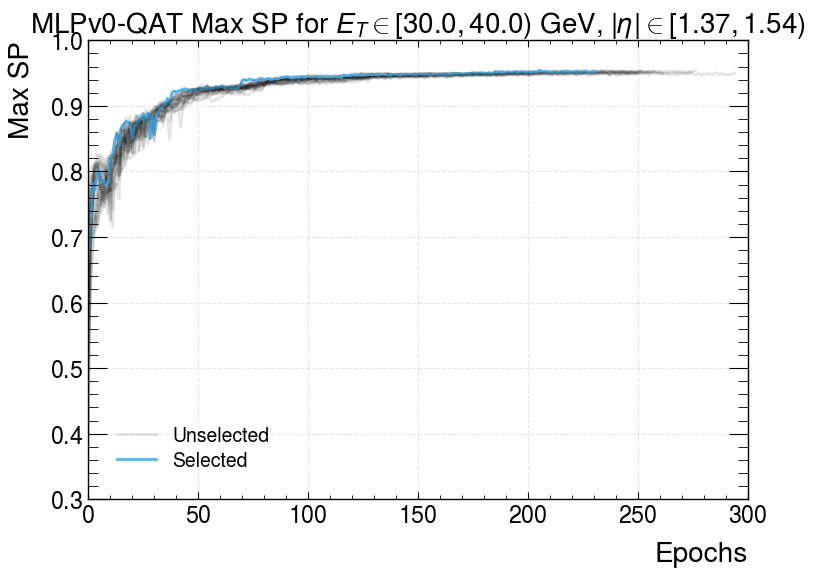

 [Thu, 09 Apr 2026 23:12:17] INFO Substituting symbol \in from Computer Modern


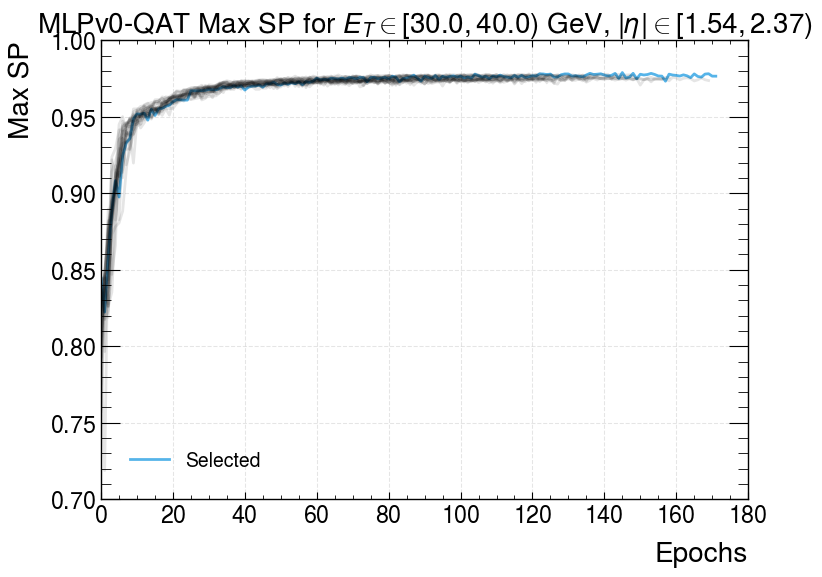

 [Thu, 09 Apr 2026 23:12:17] INFO Substituting symbol \in from Computer Modern


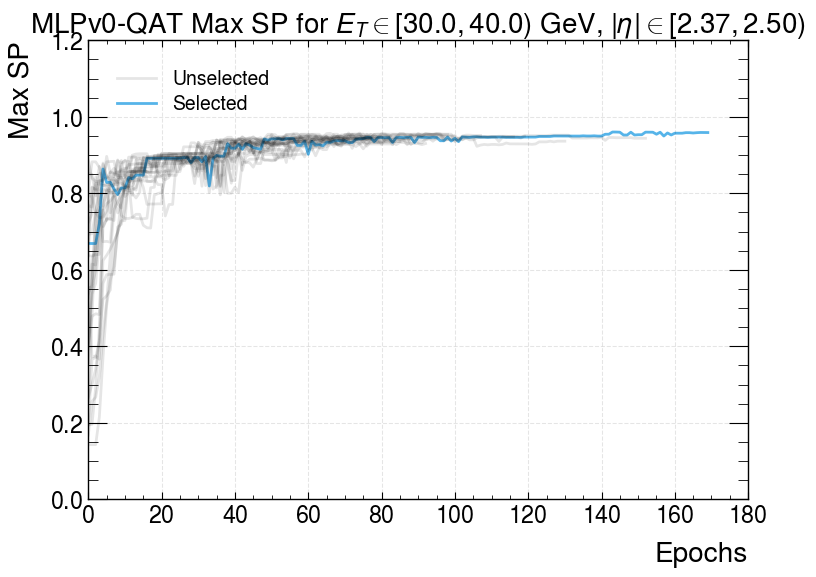

 [Thu, 09 Apr 2026 23:12:17] INFO Substituting symbol \in from Computer Modern


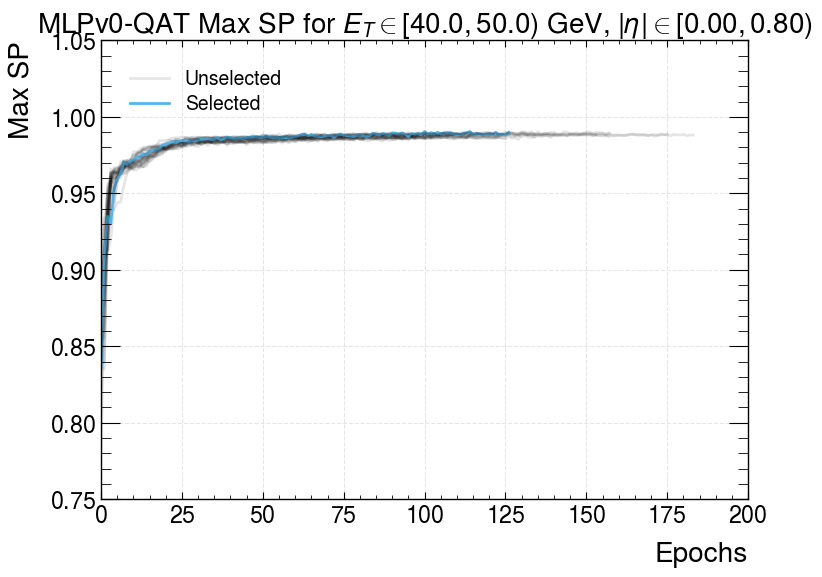

 [Thu, 09 Apr 2026 23:12:17] INFO Substituting symbol \in from Computer Modern


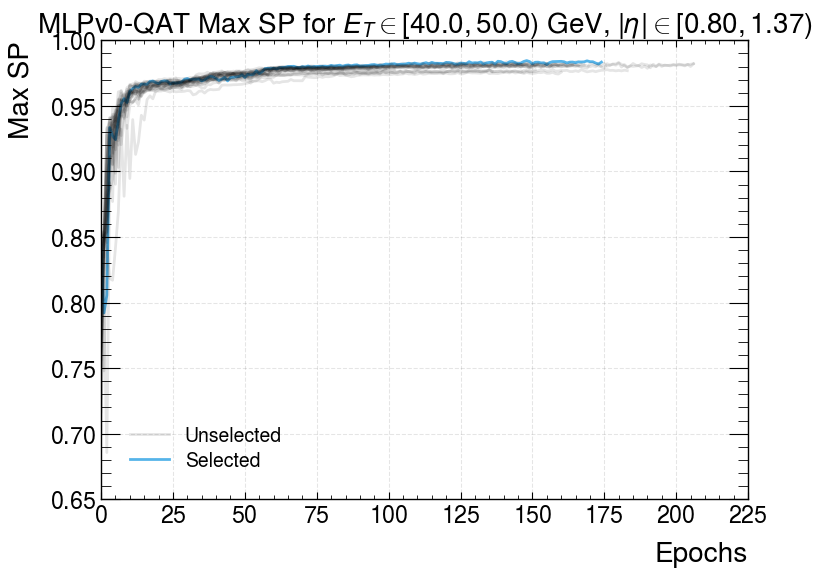

 [Thu, 09 Apr 2026 23:12:17] INFO Substituting symbol \in from Computer Modern


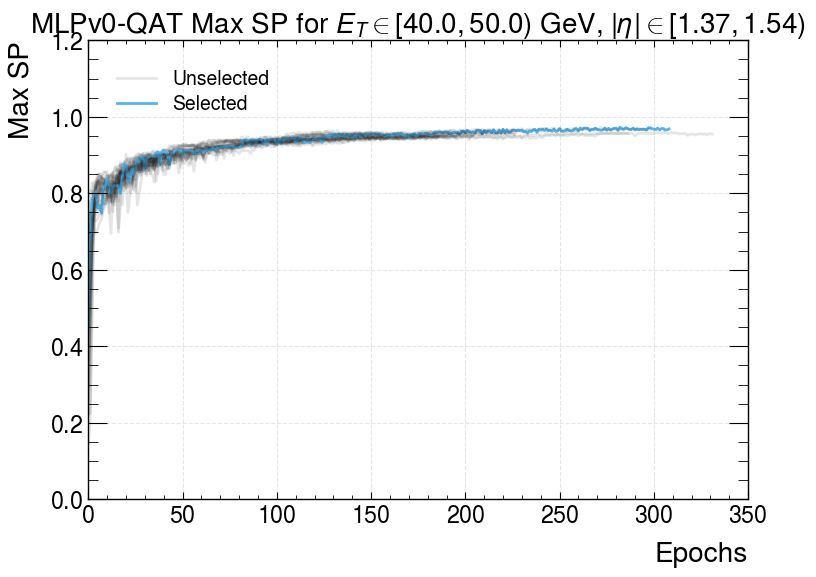

 [Thu, 09 Apr 2026 23:12:17] INFO Substituting symbol \in from Computer Modern


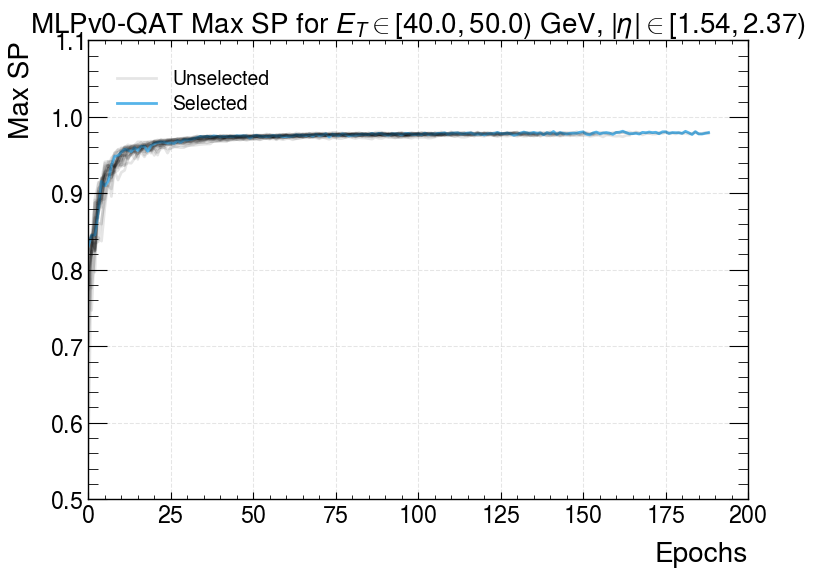

 [Thu, 09 Apr 2026 23:12:18] INFO Substituting symbol \in from Computer Modern


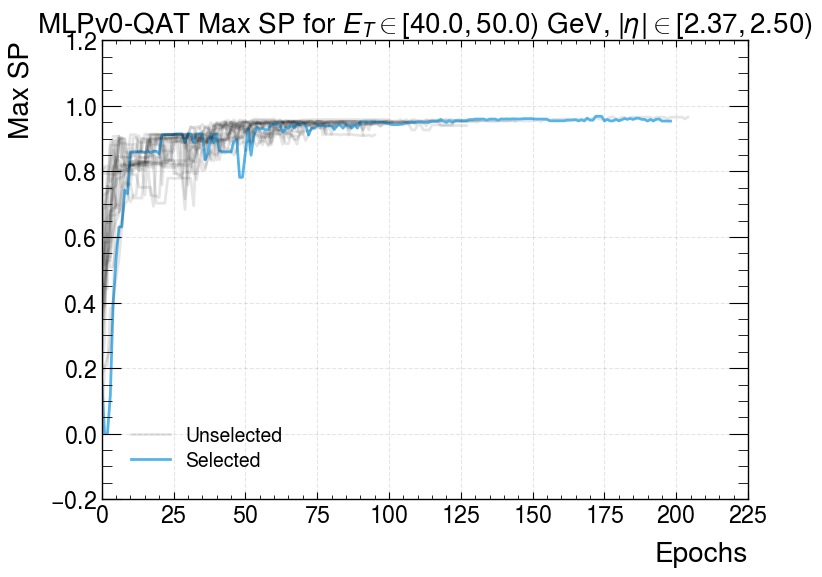

 [Thu, 09 Apr 2026 23:12:18] INFO Substituting symbol \in from Computer Modern


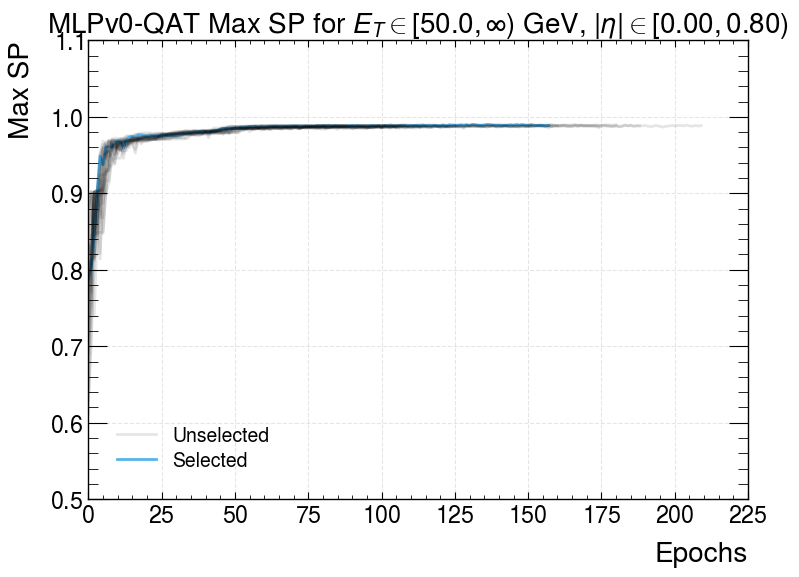

 [Thu, 09 Apr 2026 23:12:18] INFO Substituting symbol \in from Computer Modern


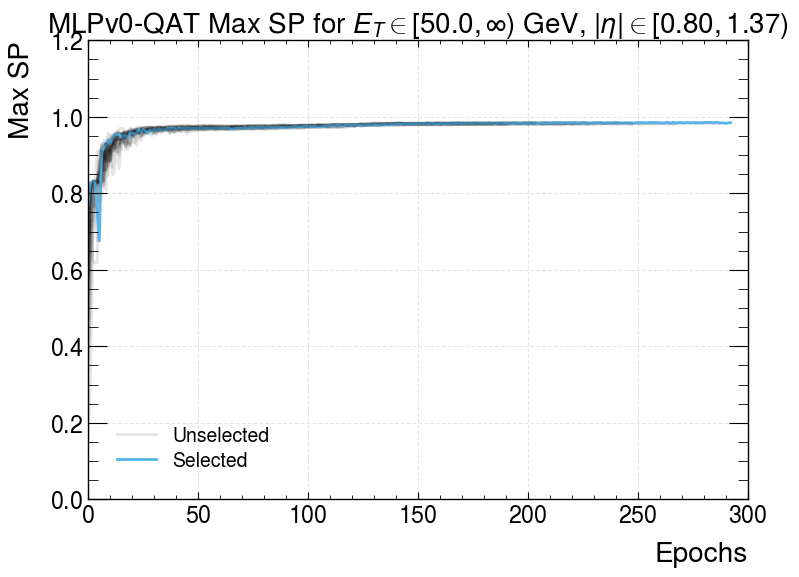

 [Thu, 09 Apr 2026 23:12:18] INFO Substituting symbol \in from Computer Modern


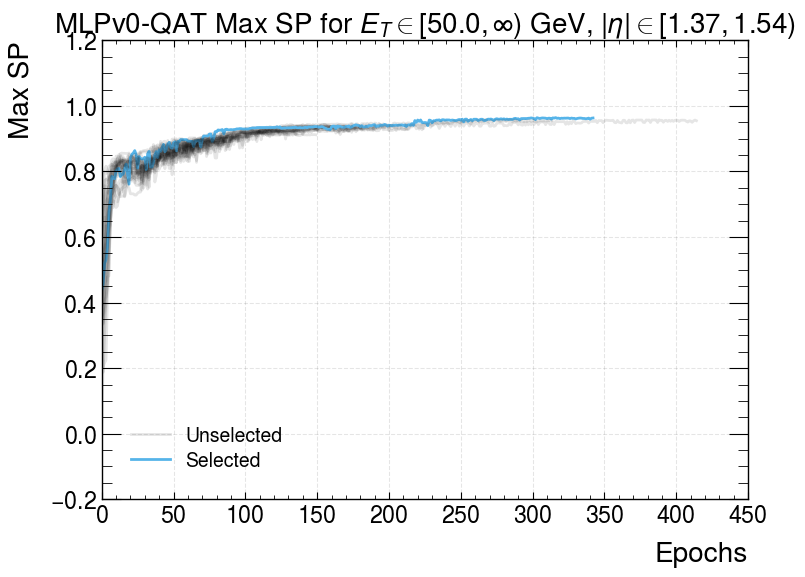

 [Thu, 09 Apr 2026 23:12:18] INFO Substituting symbol \in from Computer Modern


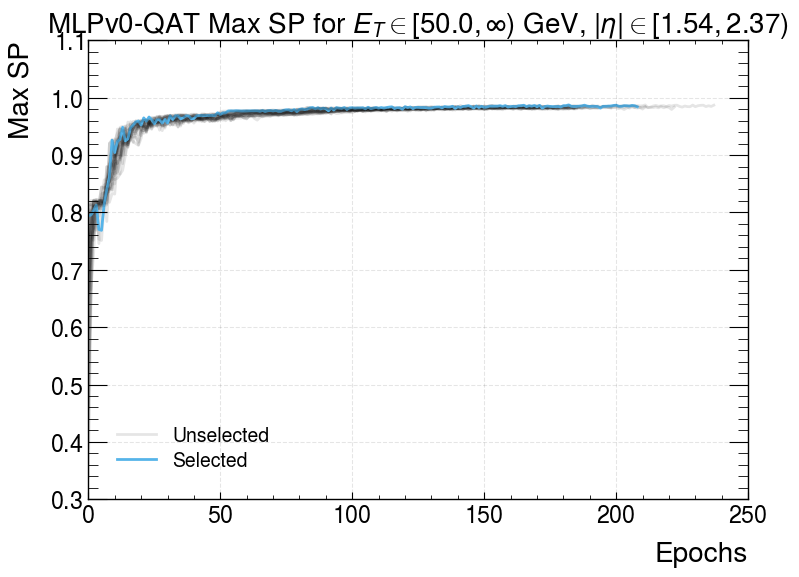

 [Thu, 09 Apr 2026 23:12:18] INFO Substituting symbol \in from Computer Modern


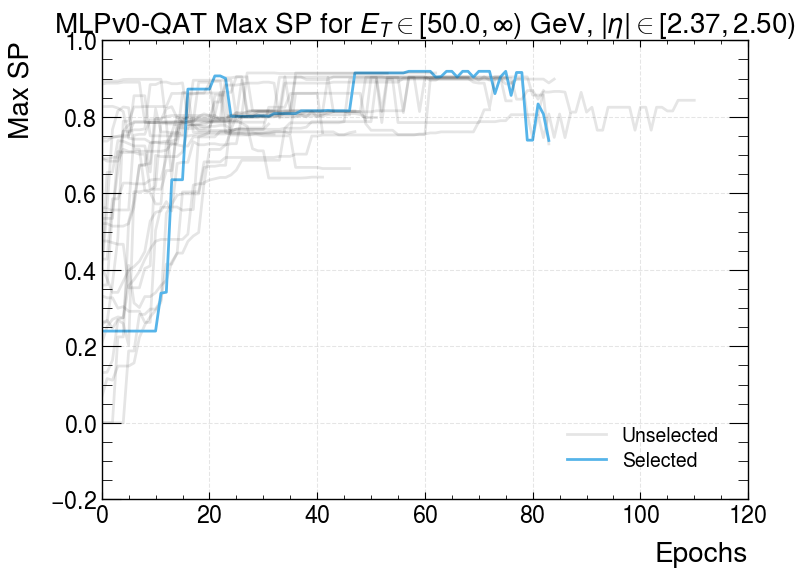

In [12]:
plot_training_curve_variations(
    model_results=results['vqat0'],
    metric='history.max_sp_val',
    metric_label='Max SP',
    title_kwargs=dict(fontsize=20)
)

 [Thu, 09 Apr 2026 23:12:18] INFO Processing row with et_bin_upper: 20000.0, et_bin_lower: 15000.0, eta_bin_upper: 0.8, eta_bin_lower: 0.0
 [Thu, 09 Apr 2026 23:12:18] INFO Processing fold/init variation 1
 [Thu, 09 Apr 2026 23:12:18] INFO Processing fold: 0, init: 0
 [Thu, 09 Apr 2026 23:12:18] INFO Processing fold/init variation 2
 [Thu, 09 Apr 2026 23:12:18] INFO Processing fold: 0, init: 1
 [Thu, 09 Apr 2026 23:12:18] INFO Processing fold/init variation 3
 [Thu, 09 Apr 2026 23:12:18] INFO Processing fold: 0, init: 2
 [Thu, 09 Apr 2026 23:12:18] INFO Processing fold/init variation 4
 [Thu, 09 Apr 2026 23:12:18] INFO Processing fold: 0, init: 3
 [Thu, 09 Apr 2026 23:12:18] INFO Processing fold/init variation 5
 [Thu, 09 Apr 2026 23:12:18] INFO Processing fold: 0, init: 4
 [Thu, 09 Apr 2026 23:12:18] INFO Processing fold/init variation 6
 [Thu, 09 Apr 2026 23:12:18] INFO Processing fold: 1, init: 0
 [Thu, 09 Apr 2026 23:12:18] INFO Processing fold/init variation 7
 [Thu, 09 Apr 2026 2

[(<Figure size 800x600 with 1 Axes>,
  <Axes: title={'center': 'MLPv0 Max SP for $E_T \\in [15.0, 20.0)$ GeV, $|\\eta| \\in [0.00, 0.80)$'}, xlabel='Epochs', ylabel='Max SP'>),
 (<Figure size 800x600 with 1 Axes>,
  <Axes: title={'center': 'MLPv0 Max SP for $E_T \\in [15.0, 20.0)$ GeV, $|\\eta| \\in [0.80, 1.37)$'}, xlabel='Epochs', ylabel='Max SP'>),
 (<Figure size 800x600 with 1 Axes>,
  <Axes: title={'center': 'MLPv0 Max SP for $E_T \\in [15.0, 20.0)$ GeV, $|\\eta| \\in [1.37, 1.54)$'}, xlabel='Epochs', ylabel='Max SP'>),
 (<Figure size 800x600 with 1 Axes>,
  <Axes: title={'center': 'MLPv0 Max SP for $E_T \\in [15.0, 20.0)$ GeV, $|\\eta| \\in [1.54, 2.37)$'}, xlabel='Epochs', ylabel='Max SP'>),
 (<Figure size 800x600 with 1 Axes>,
  <Axes: title={'center': 'MLPv0 Max SP for $E_T \\in [15.0, 20.0)$ GeV, $|\\eta| \\in [2.37, 2.50)$'}, xlabel='Epochs', ylabel='Max SP'>),
 (<Figure size 800x600 with 1 Axes>,
  <Axes: title={'center': 'MLPv0 Max SP for $E_T \\in [20.0, 30.0)$ GeV, $|\\e

 [Thu, 09 Apr 2026 23:12:24] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:24] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:24] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:24] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:24] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:24] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:24] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:24] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:24] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:24] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:24] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:25] INFO Substituting symbol \in from Computer Modern
 [Thu, 09 Apr 2026 23:12:25] INFO Substituting symbo

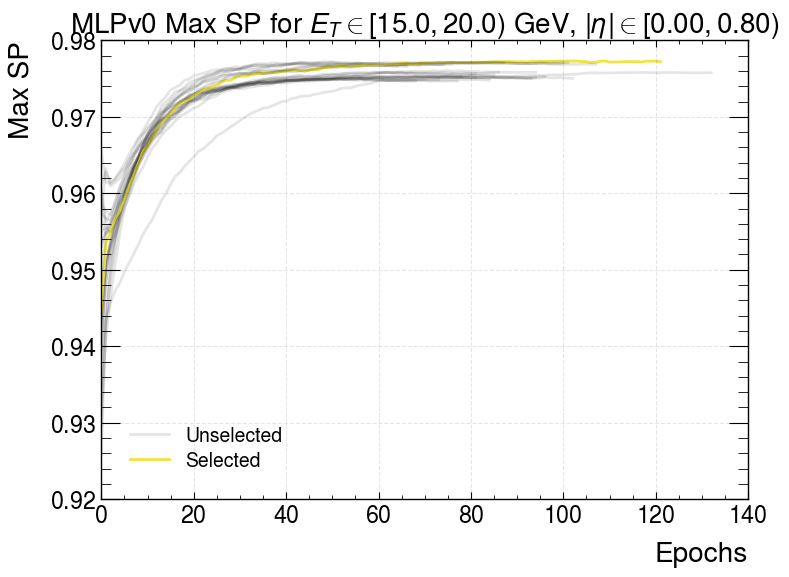

 [Thu, 09 Apr 2026 23:12:26] INFO Substituting symbol \in from Computer Modern


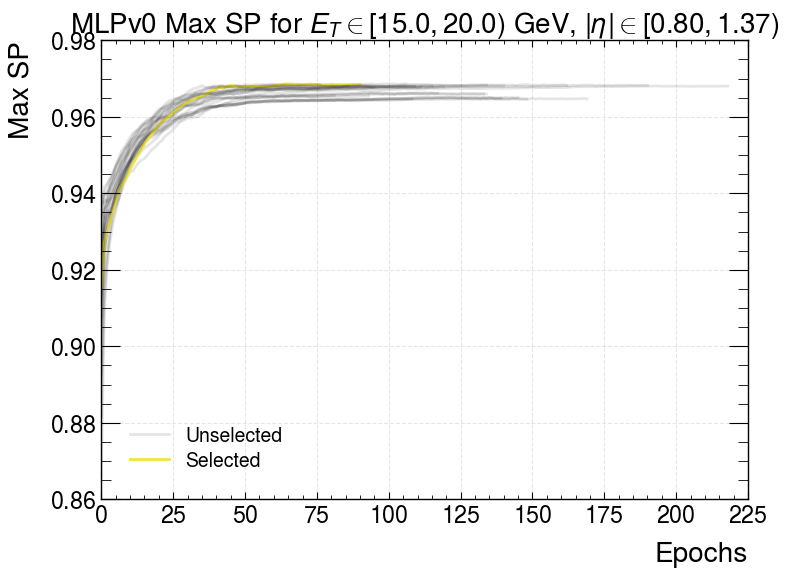

 [Thu, 09 Apr 2026 23:12:26] INFO Substituting symbol \in from Computer Modern


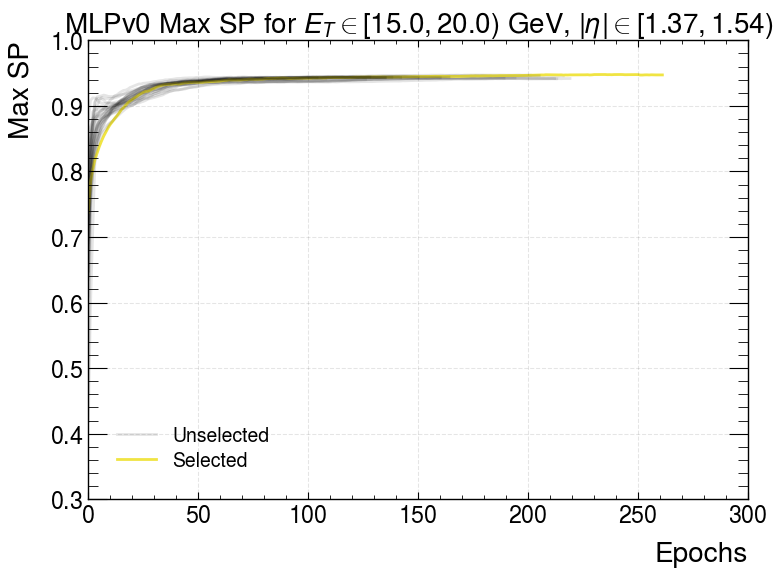

 [Thu, 09 Apr 2026 23:12:26] INFO Substituting symbol \in from Computer Modern


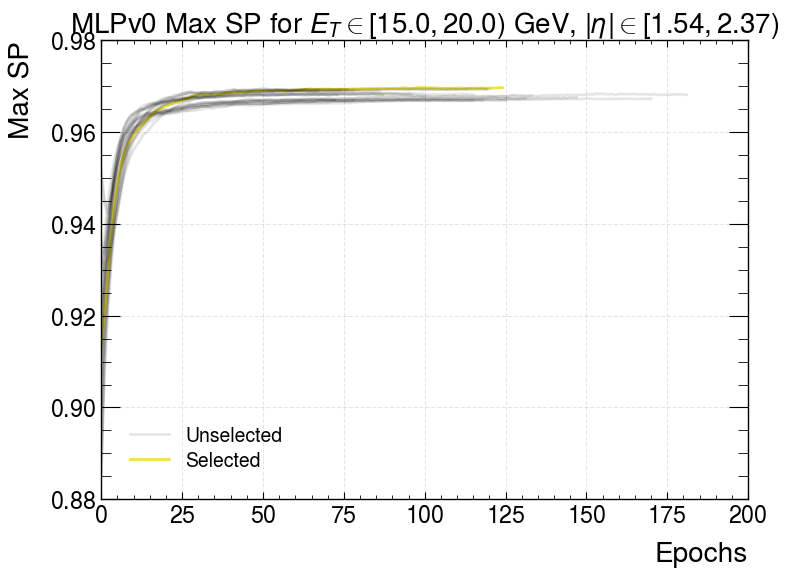

 [Thu, 09 Apr 2026 23:12:26] INFO Substituting symbol \in from Computer Modern


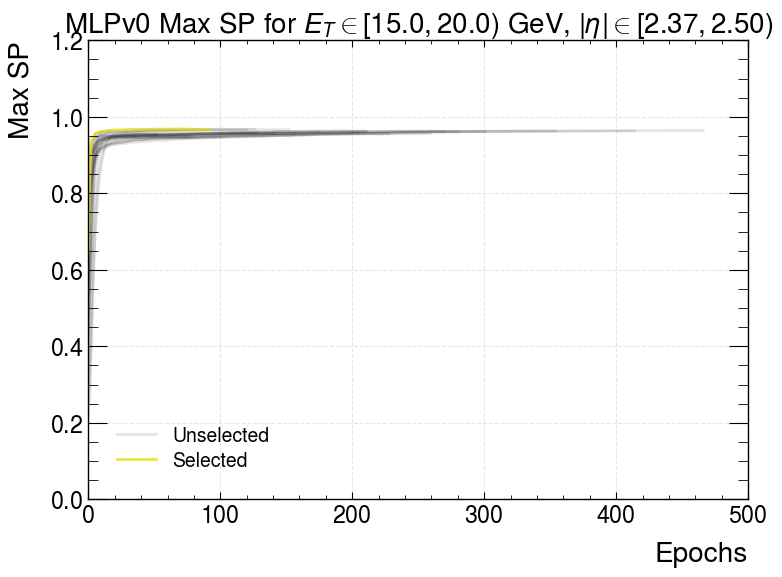

 [Thu, 09 Apr 2026 23:12:26] INFO Substituting symbol \in from Computer Modern


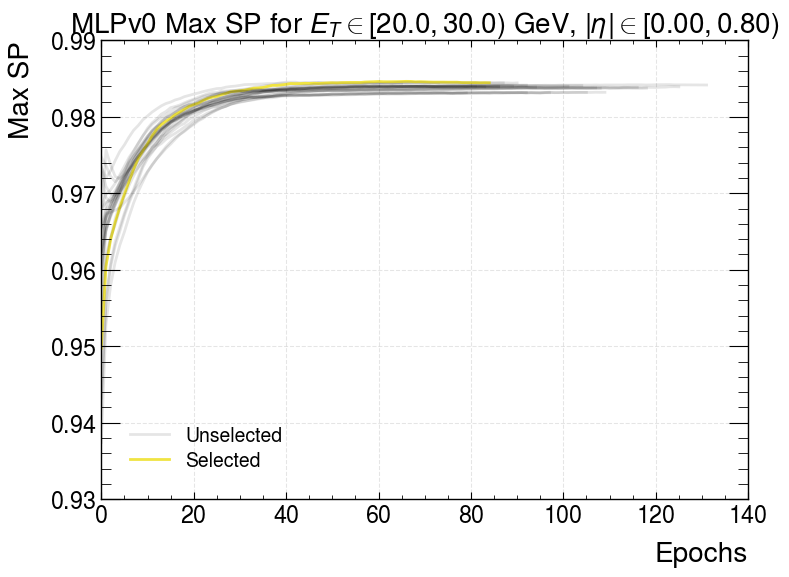

 [Thu, 09 Apr 2026 23:12:26] INFO Substituting symbol \in from Computer Modern


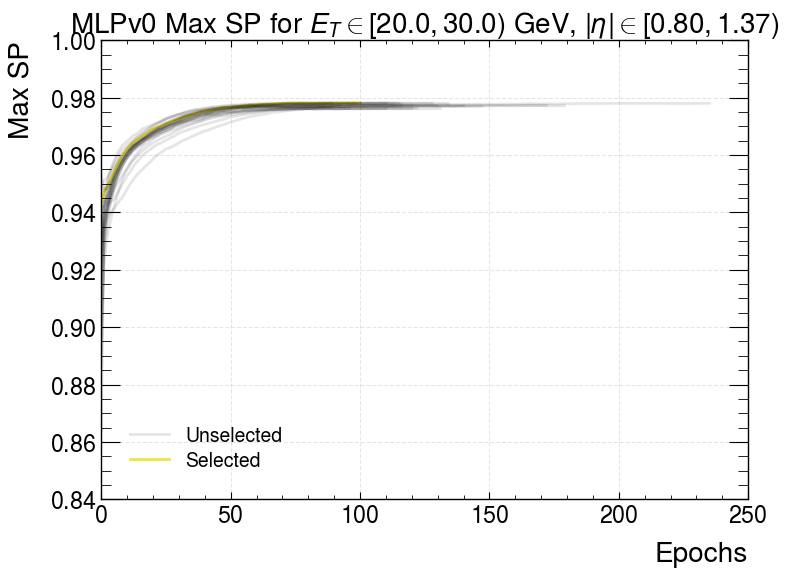

 [Thu, 09 Apr 2026 23:12:27] INFO Substituting symbol \in from Computer Modern


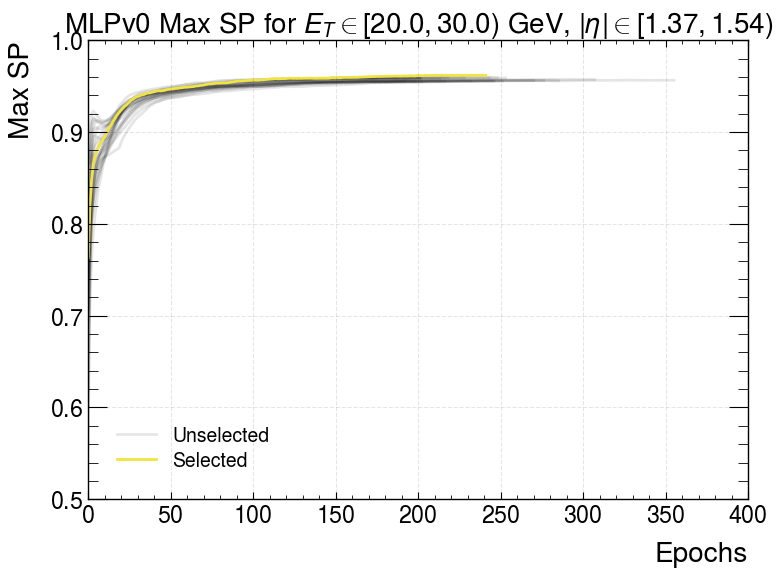

 [Thu, 09 Apr 2026 23:12:27] INFO Substituting symbol \in from Computer Modern


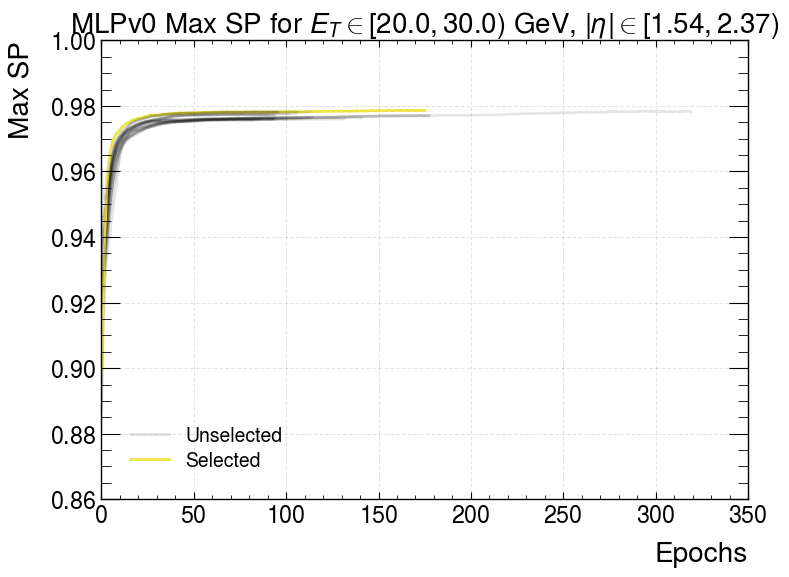

 [Thu, 09 Apr 2026 23:12:27] INFO Substituting symbol \in from Computer Modern


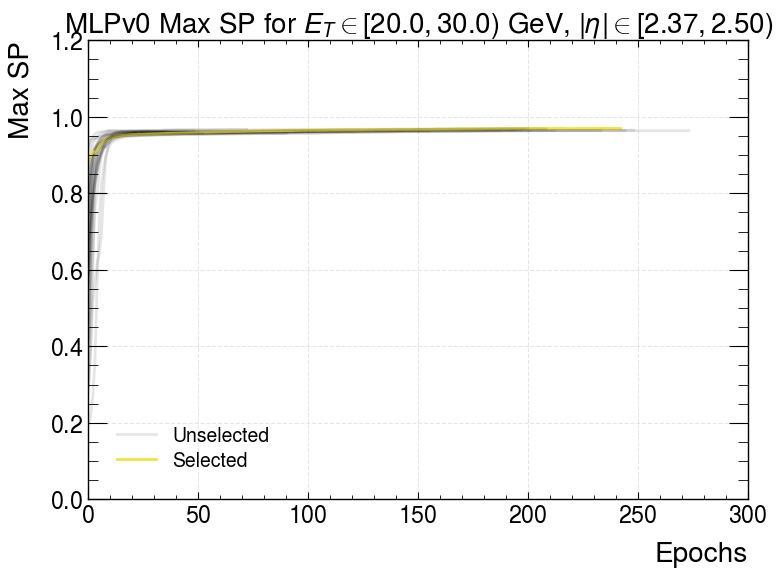

 [Thu, 09 Apr 2026 23:12:27] INFO Substituting symbol \in from Computer Modern


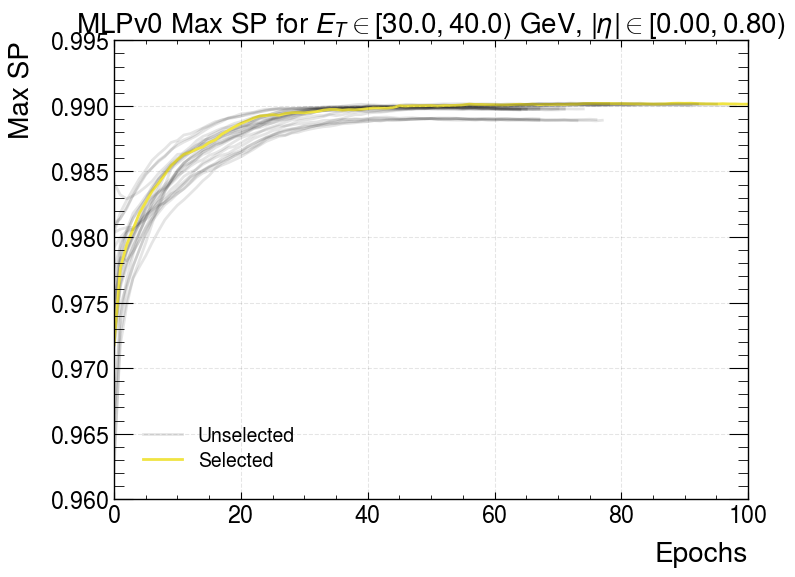

 [Thu, 09 Apr 2026 23:12:27] INFO Substituting symbol \in from Computer Modern


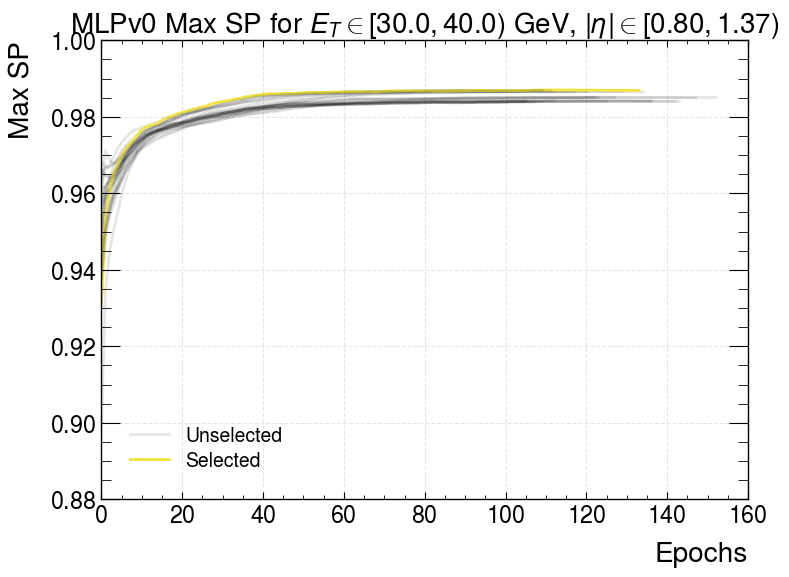

 [Thu, 09 Apr 2026 23:12:27] INFO Substituting symbol \in from Computer Modern


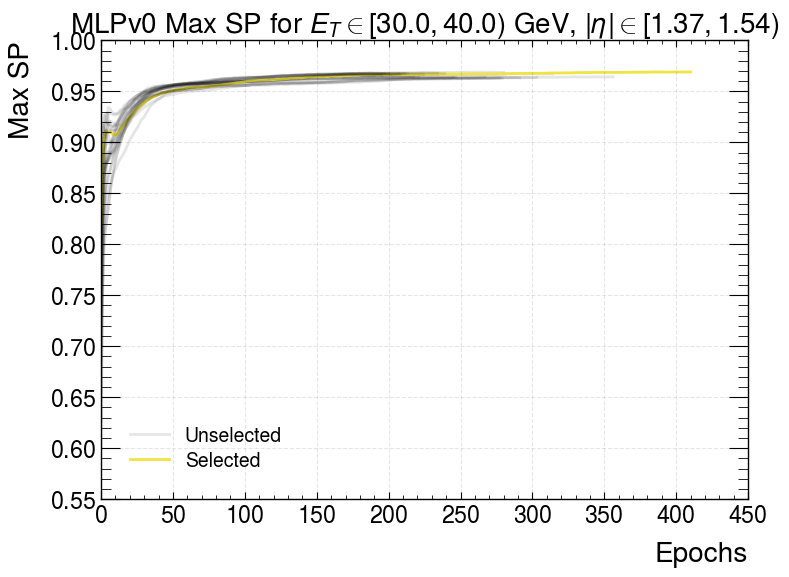

 [Thu, 09 Apr 2026 23:12:27] INFO Substituting symbol \in from Computer Modern


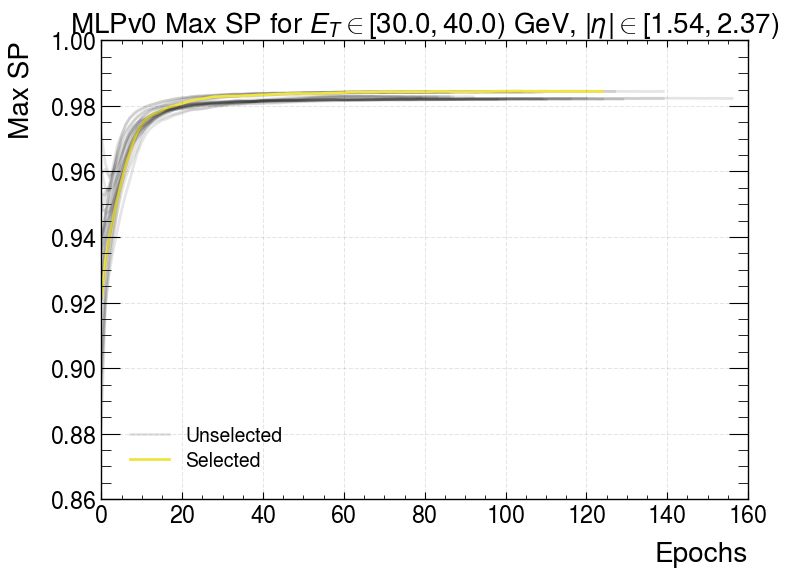

 [Thu, 09 Apr 2026 23:12:28] INFO Substituting symbol \in from Computer Modern


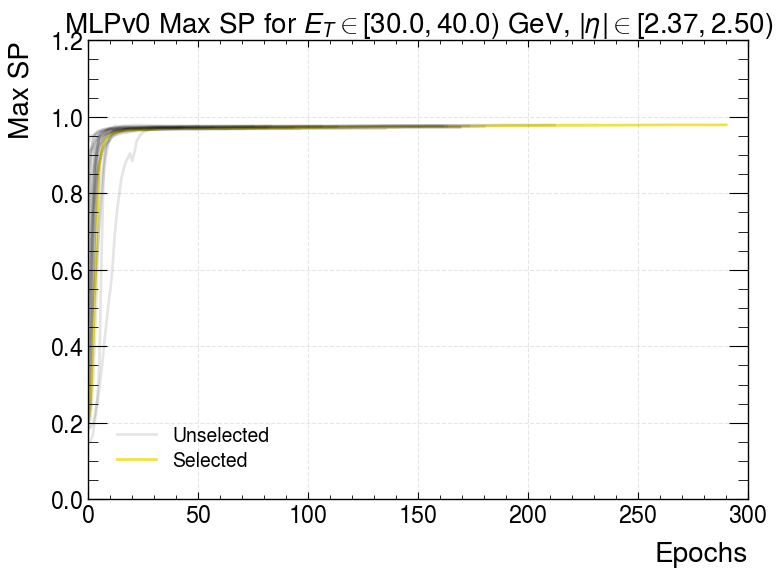

 [Thu, 09 Apr 2026 23:12:28] INFO Substituting symbol \in from Computer Modern


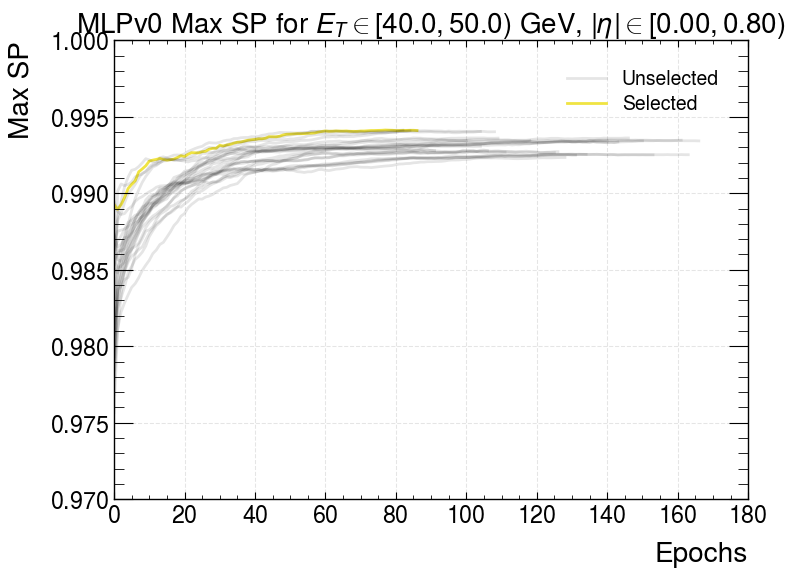

 [Thu, 09 Apr 2026 23:12:28] INFO Substituting symbol \in from Computer Modern


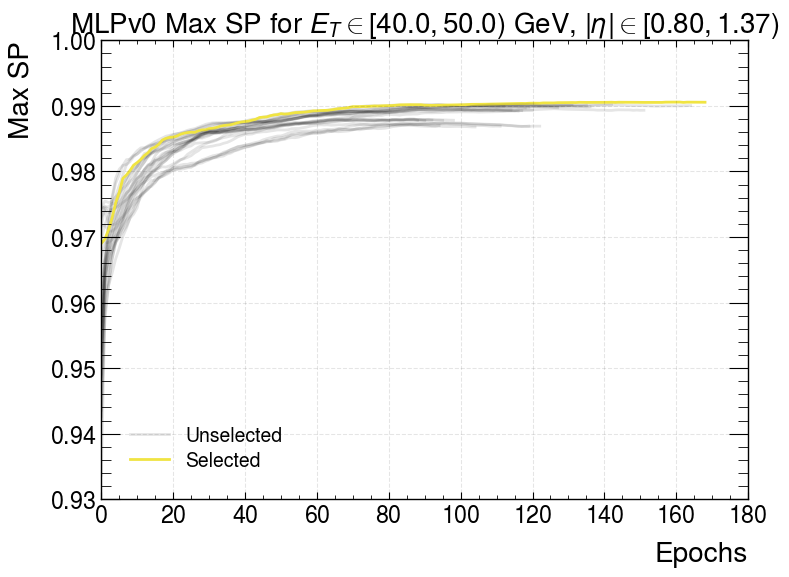

 [Thu, 09 Apr 2026 23:12:28] INFO Substituting symbol \in from Computer Modern


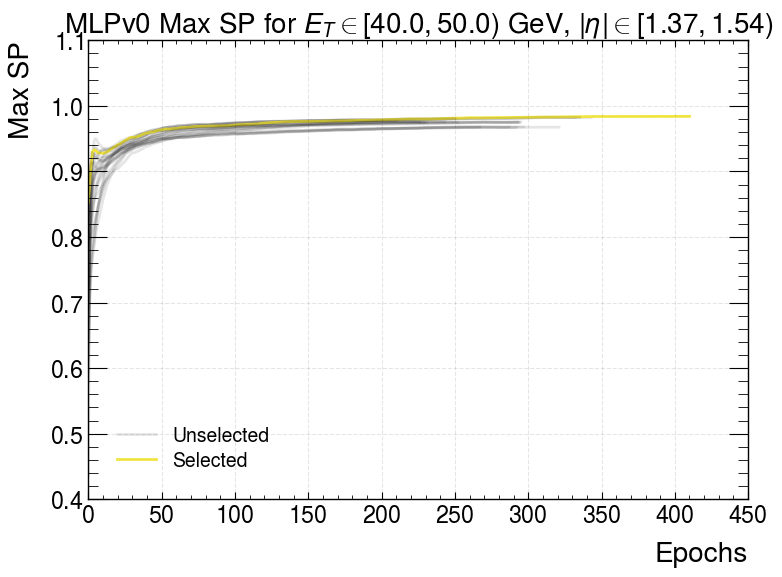

 [Thu, 09 Apr 2026 23:12:28] INFO Substituting symbol \in from Computer Modern


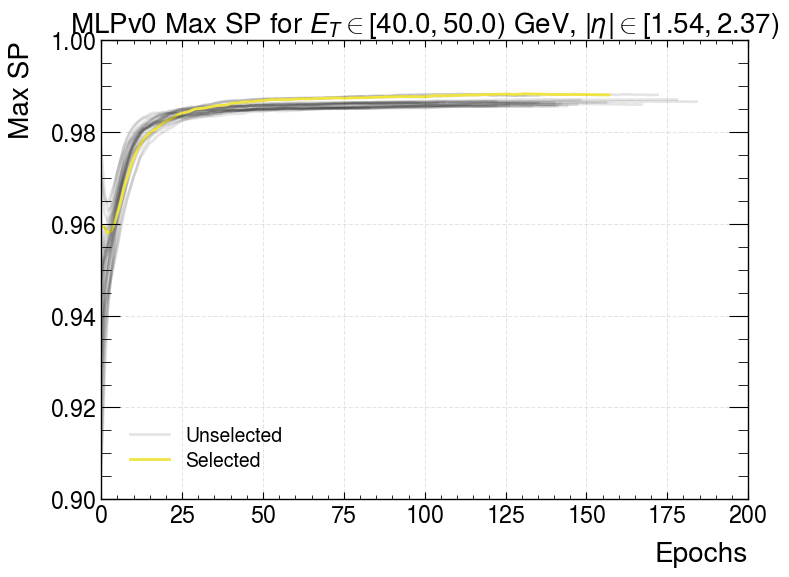

 [Thu, 09 Apr 2026 23:12:28] INFO Substituting symbol \in from Computer Modern


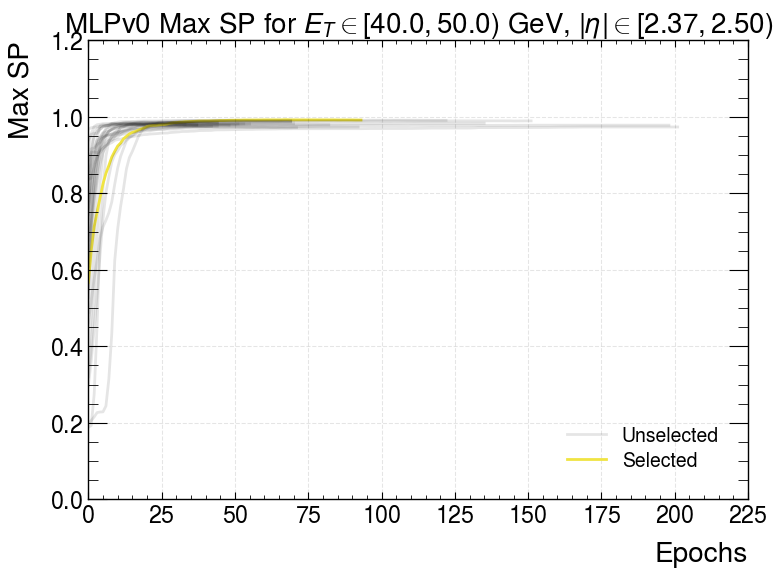

 [Thu, 09 Apr 2026 23:12:28] INFO Substituting symbol \in from Computer Modern


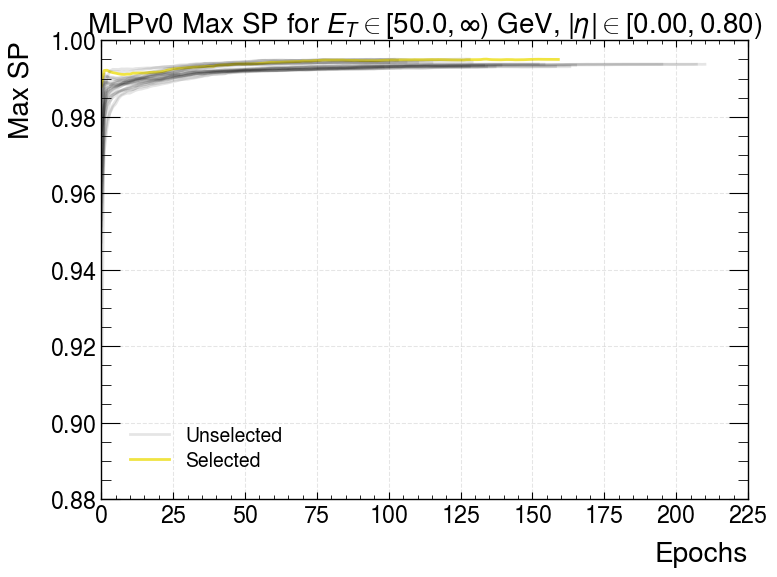

 [Thu, 09 Apr 2026 23:12:29] INFO Substituting symbol \in from Computer Modern


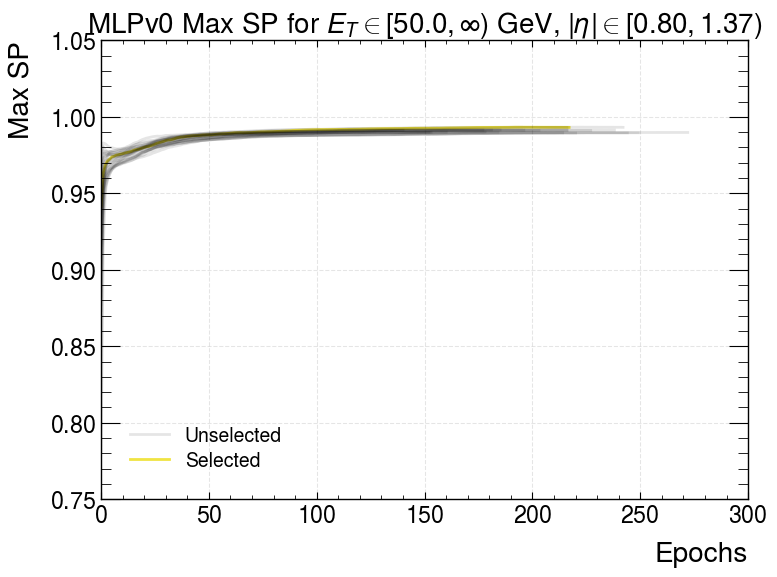

 [Thu, 09 Apr 2026 23:12:29] INFO Substituting symbol \in from Computer Modern


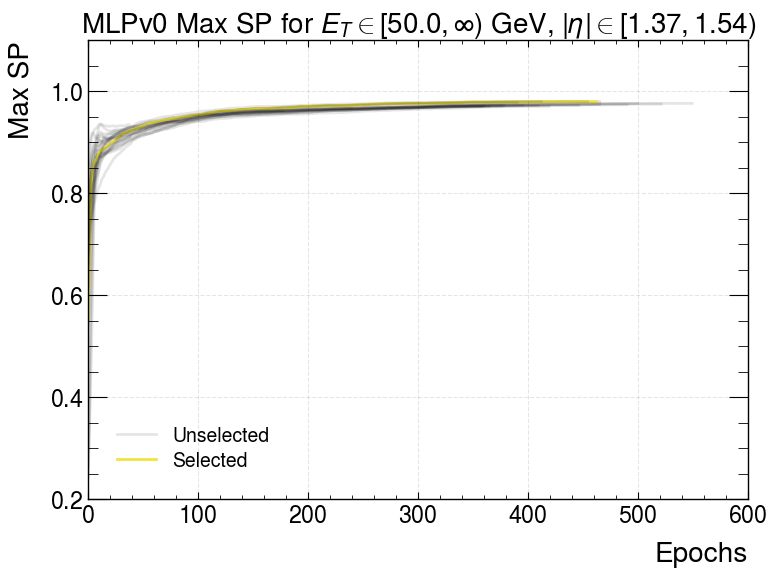

 [Thu, 09 Apr 2026 23:12:29] INFO Substituting symbol \in from Computer Modern


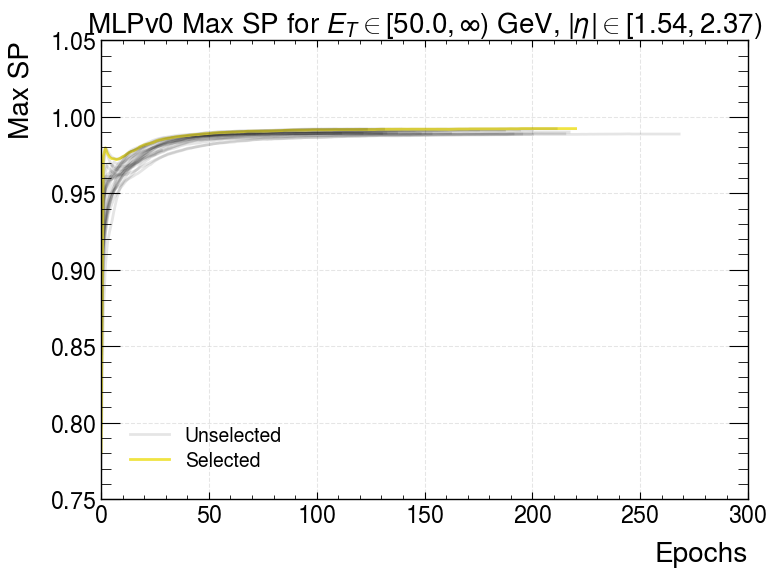

 [Thu, 09 Apr 2026 23:12:29] INFO Substituting symbol \in from Computer Modern


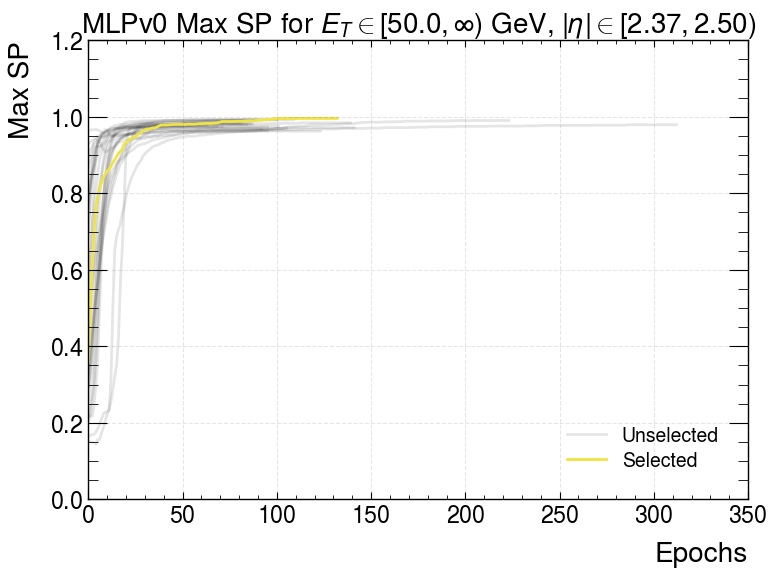

In [13]:
plot_training_curve_variations(
    model_results=results['mlp0'],
    metric='history.max_sp_val',
    metric_label='Max SP',
    title_kwargs=dict(fontsize=20)
)